# 1. <strong style="color:darkblue;">Introduction</strong>

Diamonds are among the most valuable and widely traded gemstones in the world. Their market value is determined by several factors, including physical characteristics, quality grades, market demand, and pricing strategies. The diamond industry relies on standardized evaluation methods to ensure consistent assessment of diamond quality and value.

The most widely accepted grading system is known as the Four Cs, which includes Carat, Cut, Color, and Clarity. These characteristics are considered the primary indicators of a diamond's quality and significantly influence its market price. In addition to these factors, appraisal value, discount percentage, sales channel, and customer satisfaction may also affect the final selling price of a diamond.

The dataset used in this project contains information about diamond sales transactions, including physical characteristics, pricing information, appraisal values, sales channels, certifications, and customer satisfaction. Before performing any analysis, the dataset underwent a comprehensive data preprocessing stage to improve data quality by handling missing values, correcting inconsistent data types, removing duplicate records, standardizing categorical values, and validating the integrity of the data.

The primary objective of this project is to explore the relationships between different diamond characteristics and their selling prices through Exploratory Data Analysis (EDA). Various statistical techniques and visualizations are used to identify trends, compare subgroups, investigate pricing behavior, and evaluate the influence of different variables on diamond value.

Furthermore, the project applies clustering techniques using the K-Means algorithm to identify groups of similar diamonds and employs a Linear Regression model to predict diamond prices based on their characteristics. Statistical hypothesis testing is also performed to determine whether the observed relationships are statistically significant.

The findings of this analysis provide valuable insights into the factors influencing diamond pricing and demonstrate how data analysis and machine learning techniques can support business decision-making in the diamond industry.

# 2. <strong style="color:darkblue;">Data Preprocessing</strong>

## <strong style="color:purple;">Import Libraries</strong>

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy import stats
import pandas as pd  
import seaborn as sns 
import json
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.model_selection import cross_val_score
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance

In [2]:
# Load dataset
df_original = pd.read_csv("diamond_sales_final_project.csv")

# Create a copy for cleaning and analysis
df = df_original.copy()

## <strong style="color:purple;">Data Loading</strong>

In [3]:
df

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction
0,DIA62153,2024-07-03,0.97,Fair,G,I1,57.2,60.0,6.59,6.36,3.72,1547,1640,5.2,Showroom,London,GIA,38,8.6
1,DIA62717,2022-11-01,1.13,Very Good,F,SI1,63.2,56.0,6.66,6.69,4.22,5584,"6,238",4.9,Boutique,London,IGI,64,9.2
2,DIA62114,2023-11-03,0.41,Ideal,G,VS2,59.8,NaN,4.85,4.81,2.89,1061,1077,0.4,Boutique,New York,IGI,47,8.3
3,DIA60472,16/06/2024,0.74 ct,Ideal,F,SI1,62.2,54.0,5.79,5.85,3.62,2583,3204,6.8,Online,London,GIA,103,8.0
4,DIA64139,2023-08-07,0.71,Premium,F,VS1,59.1,61.0,5.84,5.81,3.44,2839,3085,10.2,Wholesale,Paris,IGI,9,8.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4517,DIA62184,"Feb 15, 2024",1.05,Very Good,I,SI2,62.3,59.0,6.42,6.46,4.01,"$3,742",4199,9.0,Online,New York,GIA,30,7.1
4518,DIA62181,2023-01-15,0.54,Good,D,SI1,63.7,57.0,5.22,5.14,3.30,1310,1540,0.8,Boutique,Tokyo,IGI,47,8.6
4519,DIA62409,2023-03-27,0.91,Ideal,G,SI1,61.9,56.0,6.22,6.18,3.84,4731,4981,3.1,Showroom,Tokyo,Uncertified,2,7.1
4520,DIA62033,2023-09-12,1.02,Premium,H,SI1,59.1,60.0,6.59,6.54,3.88,4037,4099,6.1,Online,Tokyo,GIA,39,8.2


## <strong style="color:purple;">Initial Data Inspection</strong>

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4522 entries, 0 to 4521
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   DiamondID             4522 non-null   object 
 1   SaleDate              4522 non-null   object 
 2   Carat                 4522 non-null   object 
 3   Cut                   4522 non-null   object 
 4   Color                 4522 non-null   object 
 5   Clarity               4522 non-null   object 
 6   DepthPct              4318 non-null   float64
 7   TablePct              4372 non-null   float64
 8   LengthMm              4522 non-null   float64
 9   WidthMm               4522 non-null   float64
 10  HeightMm              4522 non-null   float64
 11  PriceUSD              4522 non-null   object 
 12  AppraisalUSD          4522 non-null   object 
 13  DiscountPercent       4522 non-null   float64
 14  SalesChannel          4522 non-null   object 
 15  StoreLocation        

In [5]:
df.head()

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction
0,DIA62153,2024-07-03,0.97,Fair,G,I1,57.2,60.0,6.59,6.36,3.72,1547,1640,5.2,Showroom,London,GIA,38,8.6
1,DIA62717,2022-11-01,1.13,Very Good,F,SI1,63.2,56.0,6.66,6.69,4.22,5584,"6,238",4.9,Boutique,London,IGI,64,9.2
2,DIA62114,2023-11-03,0.41,Ideal,G,VS2,59.8,NaN,4.85,4.81,2.89,1061,1077,0.4,Boutique,New York,IGI,47,8.3
3,DIA60472,16/06/2024,0.74 ct,Ideal,F,SI1,62.2,54.0,5.79,5.85,3.62,2583,3204,6.8,Online,London,GIA,103,8.0
4,DIA64139,2023-08-07,0.71,Premium,F,VS1,59.1,61.0,5.84,5.81,3.44,2839,3085,10.2,Wholesale,Paris,IGI,9,8.7


##### The dataset contains information about diamond sales. It includes the physical and quality characteristics of each diamond (such as carat, cut, color, and clarity), as well as business-related information including sale price, appraisal value, discount, sales channel, store location, certifications, days on the market, and customer satisfaction.

## <strong style="color:purple;">Data cleaning</strong>

In [6]:
## A loop that will give me a better view of what I need to clean up in the data rather than having to fiddle with the table.
def column_report(df):
    for col in df.columns:
        print("\n" + "="*60)
        print(f"📊 COLUMN: {col}")
        print("="*60)

        print(f"Type: {df[col].dtype}")
        print(f"Missing Values: {df[col].isnull().sum()}")
        print(f"Missing %: {round(df[col].isnull().mean() * 100, 2)}%")
        print(f"Unique Values: {df[col].nunique()}")

        print("\n🔹 Example Values:")
        print(df[col].dropna().unique()[:10])

        print("\n🔹 Value Counts (Top 5):")
        print(df[col].value_counts().head())

        print("="*60)

column_report(df)


📊 COLUMN: DiamondID
Type: object
Missing Values: 0
Missing %: 0.0%
Unique Values: 4500

🔹 Example Values:
['DIA62153' 'DIA62717' 'DIA62114' 'DIA60472' 'DIA64139' 'DIA63048'
 'DIA62282' 'DIA62815' 'DIA63749' 'DIA63063']

🔹 Value Counts (Top 5):
DiamondID
DIA63305    2
DIA64270    2
DIA64308    2
DIA63125    2
DIA60198    2
Name: count, dtype: int64

📊 COLUMN: SaleDate
Type: object
Missing Values: 0
Missing %: 0.0%
Unique Values: 1380

🔹 Example Values:
['2024-07-03' '2022-11-01' '2023-11-03' '16/06/2024' '2023-08-07'
 '2024-01-09' 'Sep 04, 2022' '2024-04-14' '2024-09-14' '2024-06-06']

🔹 Value Counts (Top 5):
SaleDate
2024-12-21    14
2024-12-04    14
2024-12-16    12
2024-11-03    12
2022-12-03    12
Name: count, dtype: int64

📊 COLUMN: Carat
Type: object
Missing Values: 0
Missing %: 0.0%
Unique Values: 283

🔹 Example Values:
['0.97' '1.13' '0.41' '0.74 ct' '0.71' '1.21' '0.64' '1.02' '0.7' '1.01']

🔹 Value Counts (Top 5):
Carat
1.01    207
0.3     201
0.31    167
0.32    155
0.7     

##### During the initial data inspection, several data quality issues were identified. The dataset contains duplicate DiamondID values, inconsistent date formats in the SaleDate column, incorrect data types in columns such as Carat, PriceUSD, AppraisalUSD, and DaysOnMarket, as well as inconsistent text formatting (different capitalization and extra spaces) in columns like Cut, SalesChannel, StoreLocation, and Certification. Additionally, several columns contain missing values, including DepthPct, TablePct, StoreLocation, Certification, DaysOnMarket, and CustomerSatisfaction. These issues should be addressed before performing further analysis to ensure accurate and reliable results.

## <strong style="color:purple;">Data Format Cleaning</strong>

In [7]:
## Carat
df['Carat'] = df['Carat'].replace(r'[^0-9.\-]', '', regex=True)  # Remove "ct" and any unwanted characters
df['Carat'] = pd.to_numeric(df['Carat'], errors='coerce')        # Convert to numeric

## PriceUSD
df['PriceUSD'] = df['PriceUSD'].replace(r'[^0-9.\-]', '', regex=True)  # Remove commas or other symbols if they exist
df['PriceUSD'] = pd.to_numeric(df['PriceUSD'], errors='coerce')        # Convert to numeric

## AppraisalUSD
df['AppraisalUSD'] = df['AppraisalUSD'].replace(r'[^0-9.\-]', '', regex=True)  # Remove commas
df['AppraisalUSD'] = pd.to_numeric(df['AppraisalUSD'], errors='coerce')         # Convert to numeric

## DaysOnMarket
df['DaysOnMarket'] = df['DaysOnMarket'].replace(r'[^0-9.\-]', '', regex=True)  # Remove unwanted characters
df['DaysOnMarket'] = pd.to_numeric(df['DaysOnMarket'], errors='coerce')         # Convert to numeric

## <strong style="color:purple;">Category Standardization</strong>

In [8]:
# ==================================
# Category Standardization
# ==================================

# Remove extra spaces and standardize capitalization

# Cut
df['Cut'] = df['Cut'].str.strip().str.title()

# Sales Channel
df['SalesChannel'] = df['SalesChannel'].str.strip().str.title()

# Store Location
df['StoreLocation'] = df['StoreLocation'].str.strip().str.title()

# Certification
df['Certification'] = df['Certification'].str.strip().str.title()

# Fix official certification names
df['Certification'] = df['Certification'].replace({
    'Gia': 'GIA',
    'Igi': 'IGI',
    'Hrd': 'HRD'
})


# Check unique values after cleaning

print("Cut values:")
print(df['Cut'].unique())

print("\nSalesChannel values:")
print(df['SalesChannel'].unique())

print("\nStoreLocation values:")
print(df['StoreLocation'].unique())

print("\nCertification values:")
print(df['Certification'].unique())

Cut values:
['Fair' 'Very Good' 'Ideal' 'Premium' 'Good']

SalesChannel values:
['Showroom' 'Boutique' 'Online' 'Wholesale']

StoreLocation values:
['London' 'New York' 'Paris' nan 'Mumbai' 'Tokyo' 'Dubai']

Certification values:
['GIA' 'IGI' nan 'HRD' 'Uncertified']


## <strong style="color:purple;">Invalid Values & Outlier Detection</strong>

In [9]:
df.describe()

,Carat,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,DaysOnMarket,CustomerSatisfaction
count,4522.000000,4318.000000,4372.000000,4522.000000,4522.000000,4522.000000,4522.000000,4522.000000,4522.000000,4451.000000,4352.000000
mean,0.843377,61.728833,57.411802,5.740668,5.742167,3.543512,3961.266696,4275.439628,5.589828,31.248034,8.027619
std,2.118356,1.454172,2.277990,1.119739,1.110384,0.694372,3984.712381,4316.754624,5.731201,20.579373,1.012108
min,0.000000,44.000000,49.000000,3.850000,3.840000,0.000000,336.000000,347.000000,-10.000000,1.000000,-2.000000
25%,0.400000,61.000000,56.000000,4.710000,4.720000,2.910000,950.250000,1028.250000,2.700000,15.000000,7.500000
50%,0.700000,61.800000,57.000000,5.710000,5.720000,3.530000,2441.500000,2645.500000,4.800000,28.000000,8.100000
75%,1.040000,62.500000,59.000000,6.540000,6.540000,4.040000,5372.250000,5785.000000,7.700000,43.000000,8.600000
max,99.000000,72.900000,95.000000,9.080000,9.010000,5.600000,18803.000000,22679.000000,150.000000,171.000000,22.000000


In [10]:
# ==================================
# Outlier Detection - IQR Method
# ==================================

numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print("\n" + "="*60)
    print(f"Column: {col}")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Lower bound: {round(lower_bound, 2)}")
    print(f"Upper bound: {round(upper_bound, 2)}")


Column: Carat
Number of outliers: 151
Lower bound: -0.56
Upper bound: 2.0

Column: DepthPct
Number of outliers: 202
Lower bound: 58.75
Upper bound: 64.75

Column: TablePct
Number of outliers: 48
Lower bound: 51.5
Upper bound: 63.5

Column: LengthMm
Number of outliers: 0
Lower bound: 1.96
Upper bound: 9.28

Column: WidthMm
Number of outliers: 0
Lower bound: 1.99
Upper bound: 9.27

Column: HeightMm
Number of outliers: 1
Lower bound: 1.22
Upper bound: 5.74

Column: PriceUSD
Number of outliers: 285
Lower bound: -5682.75
Upper bound: 12005.25

Column: AppraisalUSD
Number of outliers: 285
Lower bound: -6106.88
Upper bound: 12920.12

Column: DiscountPercent
Number of outliers: 45
Lower bound: -4.8
Upper bound: 15.2

Column: DaysOnMarket
Number of outliers: 71
Lower bound: -27.0
Upper bound: 85.0

Column: CustomerSatisfaction
Number of outliers: 39
Lower bound: 5.85
Upper bound: 10.25


In [11]:
# ==================================
# Invalid Values Validation
# ==================================

invalid_checks = {
    "Negative/Zero Carat": df[df['Carat'] <= 0],
    "Unusually High Carat": df[df['Carat'] > 5],
    "Invalid DepthPct": df[df['DepthPct'] <= 0],
    "Invalid TablePct": df[df['TablePct'] <= 0],
    "Invalid Length": df[df['LengthMm'] <= 0],
    "Invalid Width": df[df['WidthMm'] <= 0],
    "Invalid Height": df[df['HeightMm'] <= 0],
    "Negative Price": df[df['PriceUSD'] <= 0],
    "Negative Appraisal": df[df['AppraisalUSD'] <= 0],
    "Negative DaysOnMarket": df[df['DaysOnMarket'] < 0],
    "Invalid Satisfaction": df[
        (df['CustomerSatisfaction'] < 0) |
        (df['CustomerSatisfaction'] > 10)
    ]
}

for name, result in invalid_checks.items():
    print("="*60)
    print(name)
    print("Number of invalid records:", len(result))

Negative/Zero Carat
Number of invalid records: 6
Unusually High Carat
Number of invalid records: 2
Invalid DepthPct
Number of invalid records: 0
Invalid TablePct
Number of invalid records: 0
Invalid Length
Number of invalid records: 0
Invalid Width
Number of invalid records: 0
Invalid Height
Number of invalid records: 1
Negative Price
Number of invalid records: 0
Negative Appraisal
Number of invalid records: 0
Negative DaysOnMarket
Number of invalid records: 0
Invalid Satisfaction
Number of invalid records: 10


## <strong style="color:purple;">Inconsistent Carat Values</strong>

Two records contained a carat value of **99.0**, which was inconsistent with their selling prices, physical dimensions, and the overall distribution of carat values in the dataset.

Because the original carat values could not be determined with confidence, these records were treated as data-entry errors and removed from the dataset before further analysis.

Since only two records were affected (less than **0.05%** of the dataset), their removal is not expected to influence the overall representativeness of the data while preventing distortion of statistical analyses.


In [12]:
# ==================================
# Detect Inconsistent Carat Values
# ==================================

inconsistent_carat_records = df.loc[
    df['Carat'] > 5,
    [
        'DiamondID',
        'Carat',
        'PriceUSD',
        'LengthMm',
        'WidthMm',
        'HeightMm'
    ]
]

print(
    f"Number of inconsistent carat records: "
    f"{len(inconsistent_carat_records)}"
)

inconsistent_carat_records

Number of inconsistent carat records: 2


,DiamondID,Carat,PriceUSD,LengthMm,WidthMm,HeightMm
1653,DIA63761,99.0,1223,5.16,5.20,3.21
2971,DIA62579,99.0,6108,6.41,6.38,3.99


In [13]:
# ==================================
# Remove Inconsistent Carat Records
# ==================================

rows_before = len(df)

df = df.loc[df['Carat'] <= 5].copy()

rows_removed = rows_before - len(df)

print(f"Rows removed: {rows_removed}")
print(f"Dataset shape after removal: {df.shape}")

Rows removed: 2
Dataset shape after removal: (4520, 19)


In [14]:
# ==================================
# Data Cleaning - Invalid Values & Data Corrections
# ==================================

import numpy as np


# ==================================
# Fix DiscountPercent calculation
# ==================================

df.loc[:, 'DiscountPercent'] = (
    (df['AppraisalUSD'] - df['PriceUSD']) /
    df['AppraisalUSD'] * 100
).round(1)


# ==================================
# Fix invalid Customer Satisfaction values
# Expected range: 0-10
# ==================================

df.loc[
    (df['CustomerSatisfaction'] < 0) |
    (df['CustomerSatisfaction'] > 10),
    'CustomerSatisfaction'
] = np.nan


# ==================================
# Fix invalid Carat values
# Carat cannot be zero or negative
# ==================================

df.loc[
    df['Carat'] <= 0,
    'Carat'
] = np.nan


# ==================================
# Fix invalid Height values
# Height cannot be zero or negative
# ==================================

df.loc[
    df['HeightMm'] <= 0,
    'HeightMm'
] = np.nan


# ==================================
# Validation Check
# ==================================

print("Invalid Carat values:")
print(df[df['Carat'] <= 0].shape[0])


print("\nInvalid Height values:")
print(df[df['HeightMm'] <= 0].shape[0])


print("\nInvalid Customer Satisfaction values:")
print(
    df[
        (df['CustomerSatisfaction'] < 0) |
        (df['CustomerSatisfaction'] > 10)
    ].shape[0]
)


print("\nDiscount Percent range:")
print(
    df['DiscountPercent'].min(),
    "-",
    df['DiscountPercent'].max()
)

Invalid Carat values:
0

Invalid Height values:
0

Invalid Customer Satisfaction values:
0

Discount Percent range:
-16.4 - 22.9


## <strong style="color:purple;">Missing Values</strong>

In [15]:
df.isnull().sum() ## how many missing values?

DiamondID                 0
SaleDate                  0
Carat                     6
Cut                       0
Color                     0
Clarity                   0
DepthPct                204
TablePct                150
LengthMm                  0
WidthMm                   0
HeightMm                  1
PriceUSD                  0
AppraisalUSD              0
DiscountPercent           0
SalesChannel              0
StoreLocation            92
Certification           160
DaysOnMarket             71
CustomerSatisfaction    180
dtype: int64

In [16]:
missing_percent = df.isnull().mean() * 100 ## how many missing values in precent?
print(missing_percent.sort_values(ascending=False)) 
## if above 50% - delete with df = df.drop(columns=['column_name'])
## if between 20% - 50% - fill or delete depending on how important the column is
## if bleow 20% - fill (Unknown/median/mean)

DepthPct                4.513274
CustomerSatisfaction    3.982301
Certification           3.539823
TablePct                3.318584
StoreLocation           2.035398
DaysOnMarket            1.570796
Carat                   0.132743
HeightMm                0.022124
DiamondID               0.000000
SaleDate                0.000000
Cut                     0.000000
WidthMm                 0.000000
LengthMm                0.000000
Color                   0.000000
Clarity                 0.000000
SalesChannel            0.000000
DiscountPercent         0.000000
AppraisalUSD            0.000000
PriceUSD                0.000000
dtype: float64


In [17]:
# ==================================
# Missing Values Treatment
# ==================================

# Filling missing values in numerical columns using the median
# int/float columns

df['Carat'] = df['Carat'].fillna(df['Carat'].median())

df['DepthPct'] = df['DepthPct'].fillna(df['DepthPct'].median())

df['TablePct'] = df['TablePct'].fillna(df['TablePct'].median())

df['HeightMm'] = df['HeightMm'].fillna(df['HeightMm'].median())

df['DaysOnMarket'] = df['DaysOnMarket'].fillna(df['DaysOnMarket'].median())

df['CustomerSatisfaction'] = df['CustomerSatisfaction'].fillna(
    df['CustomerSatisfaction'].median()
)


# Filling missing values in categorical columns using "Unknown"
# string columns

df['Certification'] = df['Certification'].fillna("Unknown")

df['StoreLocation'] = df['StoreLocation'].fillna("Unknown")


# Converting date column to datetime format
# date columns

df['SaleDate'] = pd.to_datetime(
    df['SaleDate'],
    format='mixed',
    dayfirst=True,    # Day/month order (e.g. 04/08/2024 = 4 August 2024)
    errors='coerce'
)


# ==================================
# Validation
# ==================================

print("Missing values after cleaning:")
print(df.isnull().sum())


# General examples:
# df['col'] = df['col'].fillna(df['col'].median())      # Numerical column
# df['col'] = df['col'].fillna("Unknown")               # Categorical column
# df['date'] = pd.to_datetime(df['date'], format='mixed', dayfirst=True, errors='coerce')  # Date column

Missing values after cleaning:


DiamondID               0
SaleDate                0
Carat                   0
Cut                     0
Color                   0
Clarity                 0
DepthPct                0
TablePct                0
LengthMm                0
WidthMm                 0
HeightMm                0
PriceUSD                0
AppraisalUSD            0
DiscountPercent         0
SalesChannel            0
StoreLocation           0
Certification           0
DaysOnMarket            0
CustomerSatisfaction    0
dtype: int64


In [18]:
missing_percent = df.isnull().mean() * 100 ## how many missing values in precent?
print(missing_percent.sort_values(ascending=False)) 
## if above 50% - delete with df = df.drop(columns=['column_name'])
## if between 20% - 50% - fill or delete depending on how important the column is
## if blow 20% - fill (Unknown/median/mean)

DiamondID               0.0
SaleDate                0.0
Carat                   0.0
Cut                     0.0
Color                   0.0
Clarity                 0.0
DepthPct                0.0
TablePct                0.0
LengthMm                0.0
WidthMm                 0.0
HeightMm                0.0
PriceUSD                0.0
AppraisalUSD            0.0
DiscountPercent         0.0
SalesChannel            0.0
StoreLocation           0.0
Certification           0.0
DaysOnMarket            0.0
CustomerSatisfaction    0.0
dtype: float64


##### Category values were standardized by removing extra spaces and correcting inconsistent capitalization. Special cases such as diamond certification organizations (GIA, IGI, HRD) were restored to their official naming format.

## <strong style="color:purple;">Duplicates Handling</strong>

In [19]:
df.duplicated().sum() ## how many duplicate values

np.int64(22)

In [20]:
df[df.duplicated()] ## show duplicate values

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction
1446,DIA63863,2024-02-26,0.35,Ideal,F,VS2,61.4,54.0,4.54,4.58,2.80,706,754,6.4,Online,Tokyo,IGI,55.0,8.9
2320,DIA62308,2024-05-18,0.84,Premium,F,VVS2,60.4,62.0,6.15,6.10,3.70,4243,4688,9.5,Online,London,Uncertified,26.0,6.4
2383,DIA63703,2024-12-04,1.01,Very Good,D,VS2,60.6,56.0,6.45,6.51,3.93,7001,7521,6.9,Boutique,London,Uncertified,36.0,7.7
2423,DIA61324,2024-09-27,0.32,Very Good,F,VVS2,63.0,56.0,4.37,4.39,2.76,721,715,-0.8,Wholesale,Dubai,GIA,26.0,7.7
2440,DIA63513,2024-04-15,1.01,Very Good,D,SI2,61.9,58.0,6.43,6.49,4.00,4727,5305,10.9,Online,Mumbai,IGI,25.0,8.0
2501,DIA61374,2024-12-20,1.20,Ideal,I,VS2,62.1,57.0,6.78,6.71,4.19,5914,6911,14.4,Boutique,Tokyo,IGI,26.0,9.3
2674,DIA63125,2023-11-25,0.27,Very Good,H,VVS2,62.5,55.0,4.12,4.16,2.59,504,536,6.0,Showroom,London,GIA,11.0,8.4
2869,DIA63305,2022-08-10,0.32,Ideal,G,IF,62.0,54.0,4.42,4.45,2.75,918,1058,13.2,Showroom,Tokyo,IGI,5.0,7.3
2900,DIA60198,2023-02-15,0.33,Ideal,F,VS2,61.8,54.0,4.49,4.47,2.74,854,850,-0.5,Showroom,London,GIA,49.0,8.1
3029,DIA60236,2024-10-11,1.02,Ideal,D,IF,63.0,57.0,6.39,6.35,4.01,15575,17319,10.1,Boutique,Paris,GIA,89.0,7.9


In [21]:
df.duplicated(subset=['DiamondID']).sum()  # how many duplicate DiamondID values

np.int64(22)

In [22]:
df[df.duplicated(subset=['DiamondID'], keep=False)]

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction
68,DIA61324,2024-09-27,0.32,Very Good,F,VVS2,63.0,56.0,4.37,4.39,2.76,721,715,-0.8,Wholesale,Dubai,GIA,26.0,7.7
70,DIA63154,2024-05-16,0.90,Very Good,F,VS2,63.2,58.0,6.11,6.16,3.88,4504,5125,12.1,Online,Dubai,HRD,82.0,6.8
275,DIA60236,2024-10-11,1.02,Ideal,D,IF,63.0,57.0,6.39,6.35,4.01,15575,17319,10.1,Boutique,Paris,GIA,89.0,7.9
278,DIA61031,2022-10-26,0.70,Ideal,E,VS2,61.9,56.0,5.69,5.72,3.53,3142,3535,11.1,Boutique,London,GIA,50.0,8.9
363,DIA63125,2023-11-25,0.27,Very Good,H,VVS2,62.5,55.0,4.12,4.16,2.59,504,536,6.0,Showroom,London,GIA,11.0,8.4
489,DIA63863,2024-02-26,0.35,Ideal,F,VS2,61.4,54.0,4.54,4.58,2.80,706,754,6.4,Online,Tokyo,IGI,55.0,8.9
809,DIA60198,2023-02-15,0.33,Ideal,F,VS2,61.8,54.0,4.49,4.47,2.74,854,850,-0.5,Showroom,London,GIA,49.0,8.1
991,DIA63305,2022-08-10,0.32,Ideal,G,IF,62.0,54.0,4.42,4.45,2.75,918,1058,13.2,Showroom,Tokyo,IGI,5.0,7.3
1244,DIA64270,2022-06-27,0.35,Premium,E,SI1,61.8,60.0,4.57,4.51,2.76,788,913,13.7,Wholesale,Dubai,GIA,19.0,8.7
1446,DIA63863,2024-02-26,0.35,Ideal,F,VS2,61.4,54.0,4.54,4.58,2.80,706,754,6.4,Online,Tokyo,IGI,55.0,8.9


In [23]:
df[df.duplicated(subset=['DiamondID'], keep=False)].groupby('DiamondID').size()

DiamondID
DIA60198    2
DIA60232    2
DIA60236    2
DIA61031    2
DIA61047    2
DIA61324    2
DIA61343    2
DIA61374    2
DIA61890    2
DIA62001    2
DIA62045    2
DIA62308    2
DIA62730    2
DIA63125    2
DIA63154    2
DIA63305    2
DIA63513    2
DIA63703    2
DIA63863    2
DIA63899    2
DIA64270    2
DIA64308    2
dtype: int64

In [24]:
df[df.duplicated(subset=['DiamondID'], keep=False)].duplicated().sum()

np.int64(22)

In [25]:
df[df['DiamondID'].duplicated(keep=False)].sort_values('DiamondID')

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,PriceUSD,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction
809,DIA60198,2023-02-15,0.33,Ideal,F,VS2,61.8,54.0,4.49,4.47,2.74,854,850,-0.5,Showroom,London,GIA,49.0,8.1
2900,DIA60198,2023-02-15,0.33,Ideal,F,VS2,61.8,54.0,4.49,4.47,2.74,854,850,-0.5,Showroom,London,GIA,49.0,8.1
3706,DIA60232,2023-12-02,0.50,Very Good,I,VS1,63.0,55.0,5.07,5.09,3.20,1242,1325,6.3,Online,Mumbai,GIA,28.0,9.2
2729,DIA60232,2023-12-02,0.50,Very Good,I,VS1,63.0,55.0,5.07,5.09,3.20,1242,1325,6.3,Online,Mumbai,GIA,28.0,9.2
275,DIA60236,2024-10-11,1.02,Ideal,D,IF,63.0,57.0,6.39,6.35,4.01,15575,17319,10.1,Boutique,Paris,GIA,89.0,7.9
3029,DIA60236,2024-10-11,1.02,Ideal,D,IF,63.0,57.0,6.39,6.35,4.01,15575,17319,10.1,Boutique,Paris,GIA,89.0,7.9
4421,DIA61031,2022-10-26,0.70,Ideal,E,VS2,61.9,56.0,5.69,5.72,3.53,3142,3535,11.1,Boutique,London,GIA,50.0,8.9
278,DIA61031,2022-10-26,0.70,Ideal,E,VS2,61.9,56.0,5.69,5.72,3.53,3142,3535,11.1,Boutique,London,GIA,50.0,8.9
3290,DIA61047,2022-11-10,0.40,Good,F,SI1,63.6,57.0,4.70,4.67,2.98,945,996,5.1,Online,Tokyo,IGI,50.0,8.6
2454,DIA61047,2022-11-10,0.40,Good,F,SI1,63.6,57.0,4.70,4.67,2.98,945,996,5.1,Online,Tokyo,IGI,50.0,8.6


In [26]:
df = df.drop_duplicates().copy()

In [27]:
df.reset_index(drop=True, inplace=True)

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.duplicated(subset=['DiamondID']).sum()

np.int64(0)

## <strong style="color:purple;">Data Validation</strong>

In [30]:
def column_report(df):
    for col in df.columns:
        print("\n" + "="*60)
        print(f"📊 COLUMN: {col}")
        print("="*60)

        print(f"Type: {df[col].dtype}")
        print(f"Missing Values: {df[col].isnull().sum()}")
        print(f"Missing %: {round(df[col].isnull().mean() * 100, 2)}%")
        print(f"Unique Values: {df[col].nunique()}")

        print("\n🔹 Example Values:")
        print(df[col].dropna().unique()[:10])

        print("\n🔹 Value Counts (Top 5):")
        print(df[col].value_counts().head())

        print("="*60)

column_report(df)


📊 COLUMN: DiamondID
Type: object
Missing Values: 0
Missing %: 0.0%
Unique Values: 4498

🔹 Example Values:
['DIA62153' 'DIA62717' 'DIA62114' 'DIA60472' 'DIA64139' 'DIA63048'
 'DIA62282' 'DIA62815' 'DIA63749' 'DIA63063']

🔹 Value Counts (Top 5):
DiamondID
DIA62153    1
DIA62717    1
DIA62114    1
DIA60472    1
DIA64139    1
Name: count, dtype: int64

📊 COLUMN: SaleDate
Type: datetime64[ns]
Missing Values: 0
Missing %: 0.0%
Unique Values: 951

🔹 Example Values:
<DatetimeArray>
['2024-07-03 00:00:00', '2022-11-01 00:00:00', '2023-11-03 00:00:00',
 '2024-06-16 00:00:00', '2023-08-07 00:00:00', '2024-01-09 00:00:00',
 '2022-09-04 00:00:00', '2024-04-14 00:00:00', '2024-09-14 00:00:00',
 '2024-06-06 00:00:00']
Length: 10, dtype: datetime64[ns]

🔹 Value Counts (Top 5):
SaleDate
2024-12-04    16
2024-12-21    15
2022-12-03    14
2023-11-06    14
2024-10-20    13
Name: count, dtype: int64

📊 COLUMN: Carat
Type: float64
Missing Values: 0
Missing %: 0.0%
Unique Values: 203

🔹 Example Values:
[0.9

In [31]:
print(f"Total Missing Values: {df.isna().sum().sum()}")

Total Missing Values: 0


## <strong style="color:purple;">Data Cleaning Summary</strong>

### Data Cleaning Report - Diamond Sales Dataset

#### Objective:

The purpose of this data cleaning process was to improve the quality, consistency, and reliability of the diamond sales dataset before performing exploratory data analysis.

The cleaning process focused on identifying and correcting data quality issues, including:

- Incorrect data formats
- Inconsistent categorical values
- Invalid and unrealistic values
- Missing values
- Duplicate records

The goal was to preserve valid business information while removing or correcting confirmed data quality issues that could negatively affect future analysis.

---

### 1. Data Format Cleaning

#### Objective:

The first step was to ensure that all columns were stored in the correct data format and that numerical columns contained valid numeric values.

Several columns were reviewed and cleaned, including:

- Carat
- PriceUSD
- AppraisalUSD
- DaysOnMarket

Some values contained unwanted characters or formatting issues that could prevent proper numerical analysis.

For example:

- Removing unnecessary characters from numerical values
- Removing symbols and text from numeric columns
- Converting columns into numeric data types

Code operations included:

- Removing non-numeric characters using regular expressions
- Converting values using pd.to_numeric()
- Handling conversion errors by converting invalid values into missing values

This step ensured that numerical calculations, statistical analysis, and visualizations could be performed correctly.

---

### 2. Category Standardization

#### Objective:

The purpose of this step was to standardize categorical variables and ensure consistency between identical categories written in different formats.

The following columns were standardized:

- Cut
- SalesChannel
- StoreLocation
- Certification

The cleaning process included:

- Removing unnecessary spaces
- Standardizing capitalization
- Correcting official category names

Examples:

Before:

Gia  
GIA  
gia  

After:

GIA


Before:

new york  
New York  
 NEW YORK 

After:

New York


The standardized categories prevent the creation of duplicate categories during analysis and ensure accurate grouping and aggregation.

After cleaning, unique values were reviewed to confirm that inconsistent category representations were successfully corrected.

---

### 3. Invalid Values & Outlier Detection

#### Objective:

The purpose of this step was to identify values that were statistically unusual or logically impossible and determine the appropriate treatment method.

Two approaches were used:

1. Statistical outlier detection using the IQR method.
2. Business logic validation for impossible values.

---

#### 3.1 Outlier Detection Using IQR Method

The Interquartile Range (IQR) method was applied to numerical columns.

The following columns were examined:

- Carat
- DepthPct
- TablePct
- LengthMm
- WidthMm
- HeightMm
- PriceUSD
- AppraisalUSD
- DiscountPercent
- DaysOnMarket
- CustomerSatisfaction

The analysis identified potential outliers in several columns.

However, not every statistical outlier represents an error.

For example:

- High diamond prices may represent expensive diamonds.
- Larger carat values may represent rare diamonds.
- Longer market durations may represent difficult-to-sell products.

Therefore, statistical outliers were investigated together with business rules before making changes.

Not all statistical outliers were automatically treated as errors. Each outlier was evaluated using business logic before making any modifications. Only logically impossible values, such as zero or negative diamond weight, zero height, and customer satisfaction values outside the valid range (0–10), were considered invalid and converted into missing values. Statistically extreme but realistic observations, such as expensive diamonds, large carat values, or long selling periods, were preserved because they may represent genuine business cases rather than data quality issues.

---

#### 3.2 Invalid Value Detection and Correction

Additional validation checks were performed to identify impossible values.

The following rules were applied:

##### Carat

Diamond weight cannot be zero or negative.

Invalid records were converted to missing values.

---

##### HeightMm

Diamond dimensions cannot be zero or negative.

Invalid records were converted to missing values.

---

##### CustomerSatisfaction

Customer satisfaction should be between 0 and 10.

Values outside this range were considered invalid and converted to missing values.

---

##### DiscountPercent

The DiscountPercent column was recalculated using the following formula:

(AppraisalUSD - PriceUSD) / AppraisalUSD * 100

This correction was performed because inconsistent manually entered discount values were detected. The column was recalculated from the original selling and appraisal values to ensure a consistent definition across all records.

Negative calculated values were retained because they represent diamonds sold above their appraised value and are therefore valid business observations.

Recalculating the column ensured that the discount values were based on the original business logic.

Instead of manually correcting unrealistic discount values, the DiscountPercent column was recalculated using the original business formula based on AppraisalUSD and PriceUSD. This approach ensured that every discount value was derived consistently from the underlying pricing information while eliminating incorrect values such as discounts above 100% or inconsistent negative discounts caused by data quality issues.

---

After correction, validation checks confirmed:

- No invalid Carat values remained.
- No invalid Height values remained.
- No invalid CustomerSatisfaction values remained.
- DiscountPercent was recalculated successfully.

Invalid values were reviewed individually before applying any corrections or removals. This ensured that only genuine data quality issues were addressed while preserving legitimate business records.

### 4. Missing Values Treatment

#### Objective:

The purpose of this step was to identify missing values in the dataset and determine the appropriate treatment strategy while preserving as much valid information as possible.

Missing values can affect statistical analysis, visualizations, and machine learning models. Therefore, they were reviewed carefully before applying any changes.

The following checks were performed:

- Number of missing values per column
- Percentage of missing values
- Identification of columns affected by missing data

After reviewing the missing values, an appropriate treatment strategy was selected for each affected column based on its data type, business meaning, and the potential impact on future statistical analysis.

Missing values were not automatically removed because removing records may result in losing valuable business information.

Instead, each missing value case was evaluated according to:

- Column importance
- Number of missing records
- Possible replacement methods
- Business meaning of the field

The final treatment approach was selected to maintain dataset reliability while minimizing information loss.

#### Treatment Strategy

For numerical columns, missing values were replaced using the **median** instead of the mean. The median was selected because it is less affected by extreme values (outliers), making it a more robust measure of central tendency. This approach preserves the overall distribution of the data while reducing the risk of introducing bias into future statistical analysis.

df["DepthPct"] = df["DepthPct"].fillna(df["DepthPct"].median())

---

### 5. Duplicate Data Analysis and Cleaning Report

#### Objective:

The purpose of this step was to identify, investigate, and handle duplicate records in the diamond sales dataset in order to improve data quality and prevent duplicated information from affecting future analysis.

---

#### 5.1 Checking for completely duplicated rows

The first step was to check whether the dataset contains records that are identical across all columns.

Code used:

df.duplicated().sum()

Result:

22

This indicates that 22 records were completely duplicated, meaning that all values across all columns were identical.

To investigate these records, the duplicated rows were displayed:

df[df.duplicated()]

The results confirmed that these records contained identical information and did not provide additional analytical value.

---

#### 5.2 Investigating duplicate patterns by DiamondID

Since DiamondID is expected to represent a unique identifier for each diamond, an additional investigation was performed to check whether the same diamond identifier appeared multiple times in the dataset.

Code used:

df.duplicated(subset=['DiamondID']).sum()

Result:

22

This means that 22 records contained DiamondID values that appeared previously in the dataset.

To view all records belonging to duplicated DiamondID groups, the following check was performed:

df[df.duplicated(subset=['DiamondID'], keep=False)]

Using keep=False allowed displaying all occurrences of duplicated DiamondID values, including the first occurrence and the repeated occurrence.

The duplicated DiamondID values were reviewed, and each appeared twice in the dataset.

---

#### 5.3 Comparing DiamondID duplicates with full row duplicates

To determine whether the duplicated DiamondID values represented actual duplicate records or possible repeated business events, the duplicated DiamondID records were compared.

The investigation showed that all duplicated DiamondID values were also completely identical rows.

Additional validation was performed:

df[df.duplicated(subset=['DiamondID'], keep=False)].duplicated().sum()

Result:

22

This confirmed that all 22 duplicated DiamondID records were exact duplicate rows.

---

#### 5.4 Removing completely duplicated records

Since the duplicated rows contained identical information and did not provide additional analytical value, they were removed:

df = df.drop_duplicates()

After removing the duplicates, the dataset was checked again:

df.duplicated().sum()

Result:

0

This confirms that no completely duplicated rows remain in the dataset.

---

#### 5.5 Rechecking duplicated DiamondID values after cleaning

After removing exact duplicate rows, the dataset was checked again for repeated DiamondID values:

df.duplicated(subset=['DiamondID']).sum()

Result:

0

No duplicated DiamondID values remained.

---

#### 5.6 Investigation of DiamondID DIA62001

Before the date-format correction, DIA62001 was the only DiamondID that remained duplicated after removing exact duplicates. The two records were identical in every column except SaleDate:

DIA62001 | SaleDate: 2024-04-08

DIA62001 | SaleDate: 2024-08-04

Checking the original raw values showed that both records contain the same date written in two different formats:

DIA62001 | Raw SaleDate: 04/08/2024 (DD/MM/YYYY)

DIA62001 | Raw SaleDate: 2024-08-04 (YYYY-MM-DD)

The slash-formatted dates in this dataset follow the day/month order (for example, 16/06/2024 and 20/11/2024 can only be read as day first). Without dayfirst=True, pd.to_datetime interpreted 04/08/2024 as 8 April instead of 4 August.

---

#### 5.7 Decision regarding DIA62001

The difference in SaleDate was caused by the date format, not by a business event such as a return or resale. After converting SaleDate with dayfirst=True, both records show 4 August 2024 and are identical in every column.

Therefore, DIA62001 was treated as an exact duplicate and removed together with the other completely duplicated rows in step 5.4.

General rule: when two records are identical in every field except one, the first suspicion should be a formatting issue in that field.

---

#### 5.8 Validation of other columns

Additional duplicate checks were considered for categorical columns such as:

- Cut
- Color
- Clarity
- Certification
- SalesChannel
- StoreLocation

These columns were not treated as duplicate identifiers because they represent attributes or categories rather than unique records.

Repeated values in these columns are expected because multiple diamonds can share the same characteristics, for example:

- The same color grade
- The same clarity level
- The same cut quality
- The same certification type
- The same sales channel or store location

Therefore, repeated values in categorical columns do not indicate duplicate records or data quality problems.

No duplicate removal was performed based on these columns.

---

### Final Duplicate Handling Decision:

- 22 completely duplicated rows were identified and removed.
- After cleaning, no identical duplicate rows remain.
- Duplicate DiamondID values were investigated before making any removal decision.
- DIA62001 initially appeared with two different sale dates. This was traced to a date-format difference (DD/MM/YYYY vs. YYYY-MM-DD); after parsing with dayfirst=True it was an exact duplicate and was removed.
- No duplicated DiamondID values remain after cleaning.
- Other categorical columns were reviewed, and no duplicate handling was required.

---

### Data Limitation:

The dataset does not include information about:

- Returns
- Inventory changes
- Resales
- Transaction identifiers

Therefore, it is not possible to determine with complete certainty whether a repeated DiamondID represents a valid business process or a data quality issue.

Further investigation would require additional business information from the data owner.

---

### 6. Data Validation

#### Objective:

The purpose of the final validation stage was to confirm that the cleaning process was completed successfully and that the dataset was ready for further analysis.

Several validation checks were performed after completing all cleaning steps.

---

#### 6.1 Missing Values Validation

The dataset was checked again for remaining missing values:

Code used:

df.isnull().sum()

This validation ensured that missing values were handled according to the selected cleaning strategy.

---

#### 6.2 Duplicate Validation

The dataset was checked again for duplicate records.

Code used:

df.duplicated().sum()

Result:

0

This confirmed that no completely duplicated rows remained after the cleaning process.

An additional check was performed for repeated DiamondID values:

df.duplicated(subset=['DiamondID']).sum()

Result:

0

This confirmed that every DiamondID is unique after cleaning.

---

#### 6.3 Data Type Validation

The data types of all columns were reviewed after cleaning:

Code used:

df.info()

This confirmed that:

- Numerical columns were stored as numeric types.
- Date columns were stored in the correct format.
- Categorical columns were consistent and ready for analysis.

---

#### 6.4 Statistical Validation

Descriptive statistics were reviewed after cleaning:

Code used:

df.describe()

The purpose was to confirm that:

- Numeric values were within reasonable ranges.
- Invalid values were removed or corrected.
- No unexpected changes occurred during cleaning.

---

### 7. Data Cleaning Report Summary

The data cleaning process improved the overall quality and reliability of the diamond sales dataset.

The following actions were performed:

#### Data Format Cleaning

- Removed unwanted characters from numerical columns.
- Converted columns into appropriate data types.
- Prepared the dataset for accurate numerical analysis.

---

#### Category Standardization

- Removed unnecessary spaces.
- Standardized capitalization.
- Corrected inconsistent category names.
- Unified certification names such as GIA, IGI, and HRD.

---

#### Invalid Values and Outlier Handling

- Identified statistically unusual values using the IQR method.
- Investigated suspicious values using business logic.
- Corrected invalid Carat values.
- Corrected invalid Height values.
- Corrected invalid Customer Satisfaction values.
- Recalculated DiscountPercent based on AppraisalUSD and PriceUSD.

The goal was not to remove every statistical outlier automatically, because some extreme values may represent legitimate business cases.

---

#### Missing Values Treatment

- Missing values were identified and reviewed.
- Treatment decisions were based on column meaning and the possible effect on analysis.
- Data loss was avoided whenever possible.

---

#### Duplicate Handling

- Completely duplicated records were identified and removed.
- Duplicate DiamondID values were investigated separately.
- The apparent repeated DiamondID (DIA62001) was traced to a date-format difference and removed as an exact duplicate.

---

### 8. Final Conclusion

The complete data cleaning process successfully improved the quality of the diamond sales dataset while preserving important business information.

The cleaning strategy focused on:

- Removing confirmed errors.
- Correcting inconsistent data.
- Standardizing values.
- Preserving uncertain records when business context was unavailable.

The final cleaned dataset is more reliable, consistent, and suitable for exploratory data analysis and further analytical tasks.

However, some limitations remain due to missing business information, such as:

- Transaction history
- Inventory records
- Return information
- Additional unique identifiers

Additional business context would allow deeper validation of uncertain cases and further improvement of data quality.

The cleaned dataset is now ready for the next stage: Exploratory Data Analysis (EDA).

**Dataset Cleaning Overview**

The dataset initially contained 4,522 rows and 19 columns. Before starting the analysis, a data cleaning process was performed to identify and resolve data quality issues.

During the cleaning process, missing values were identified in several columns, including DepthPct, TablePct, StoreLocation, Certification, DaysOnMarket, and CustomerSatisfaction. These missing values were handled using appropriate methods based on the data type of each column. After the cleaning process, the dataset contained 0 missing values.

Data type inconsistencies were also identified and corrected. Several columns that contained numerical information but were stored as object data types were converted into the correct numeric formats. In addition, the SaleDate column was converted from an object type into a datetime format (using dayfirst=True, because slash-formatted dates follow the DD/MM/YYYY order) to allow accurate time-based analysis.

Duplicate analysis was performed in multiple stages. First, completely duplicated rows were identified using all columns, resulting in 22 duplicate records. Since these records contained identical information and did not provide additional analytical value, they were removed from the dataset. After removing two inconsistent carat records and 22 fully duplicated records, the final cleaned dataset contained 4,498 rows and 19 columns.

An additional investigation was performed on duplicated DiamondID values, since this column represents a diamond identifier. One DiamondID (DIA62001) initially appeared with two different sale dates. The investigation showed that both records contained the same date (4 August 2024) written in two different formats (04/08/2024 and 2024-08-04). After converting the dates with dayfirst=True, the two records were identical, and the record was removed as an exact duplicate.

Categorical columns were also reviewed for inconsistencies caused by formatting differences, such as different capitalization and extra spaces (for example, “Ideal” and “IDEAL”). These values were standardized to ensure accurate grouping and analysis.

After completing the cleaning process, the dataset contains:

* 4,498 rows
* 19 columns
* 0 missing values
* 0 fully duplicated records
* Correct data types for analysis

The cleaned dataset is now ready for the Exploratory Data Analysis (EDA) phase.

## <strong style="color:purple;">Export Clean Dataset</strong>

In [32]:
df.to_csv("diamond_sales_clean.csv", index=False)

# 3. <strong style="color:darkblue;">Exploratory Data Analysis (EDA)</strong>

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4498 entries, 0 to 4497
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   DiamondID             4498 non-null   object        
 1   SaleDate              4498 non-null   datetime64[ns]
 2   Carat                 4498 non-null   float64       
 3   Cut                   4498 non-null   object        
 4   Color                 4498 non-null   object        
 5   Clarity               4498 non-null   object        
 6   DepthPct              4498 non-null   float64       
 7   TablePct              4498 non-null   float64       
 8   LengthMm              4498 non-null   float64       
 9   WidthMm               4498 non-null   float64       
 10  HeightMm              4498 non-null   float64       
 11  PriceUSD              4498 non-null   int64         
 12  AppraisalUSD          4498 non-null   int64         
 13  DiscountPercent   

### 1. <strong style="color:green;">Carat Weight and Diamond Price</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How does diamond carat weight affect the selling price of diamonds?

<strong style="color:blue;">**Objective:**</strong>  
To analyze the relationship between diamond weight and selling price and determine whether larger diamonds tend to have higher market values.

In [34]:
df[['Carat', 'PriceUSD']].describe()

,Carat,PriceUSD
count,4498.000000,4498.000000
mean,0.800729,3959.076478
std,0.471872,3984.469787
min,0.220000,336.000000
25%,0.400000,951.250000
50%,0.700000,2432.500000
75%,1.040000,5370.000000
max,2.800000,18803.000000


In [35]:
correlation = df['Carat'].corr(df['PriceUSD'])

print(f"Correlation: {correlation:.3f}")

Correlation: 0.919


<Axes: xlabel='Carat', ylabel='PriceUSD'>

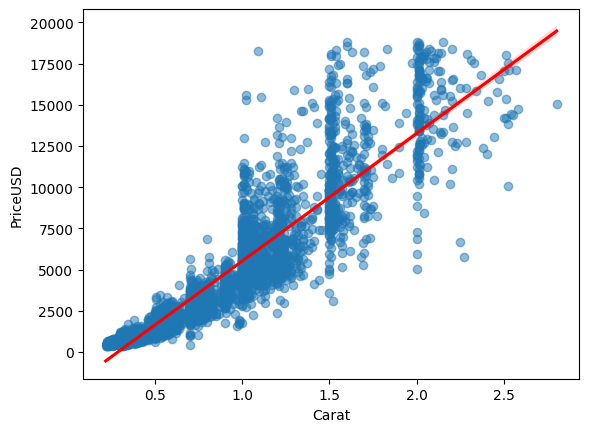

In [36]:
sns.regplot(
    data=df,
    x="Carat",
    y="PriceUSD",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

In [37]:
bins = [0,0.5,1,1.5,2,5]

labels = [
    '0-0.5',
    '0.5-1',
    '1-1.5',
    '1.5-2',
    '2+'
]

df['CaratGroup'] = pd.cut(
    df['Carat'],
    bins=bins,
    labels=labels
)

In [38]:
df.groupby(
    'CaratGroup',
    observed=False
)['PriceUSD'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
CaratGroup,,,
0-0.5,1564,840.588235,781.0
0.5-1,1449,2803.291925,2528.0
1-1.5,1020,6547.575490,5876.0
1.5-2,317,11199.246057,10694.0
2+,148,14882.351351,15171.5


<Axes: xlabel='CaratGroup', ylabel='PriceUSD'>

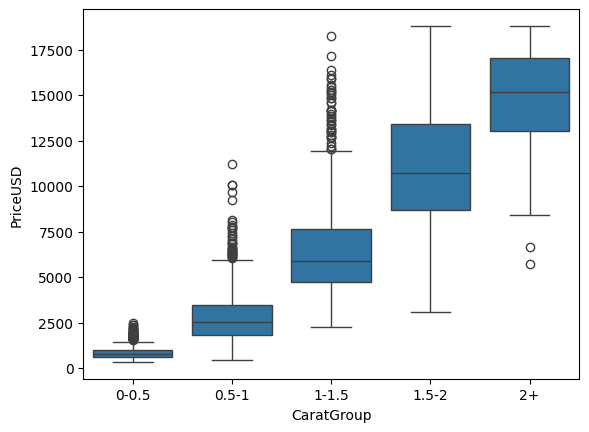

In [39]:
sns.boxplot(
    data=df,
    x='CaratGroup',
    y='PriceUSD'
)

### Analysis and Interpretation

The descriptive statistics indicate that the average diamond weight is approximately **0.80 carats**, while the median is **0.70 carats**, suggesting that most diamonds in the dataset are relatively small. In addition, the average selling price (**$3,959**) is considerably higher than the median (**$2,433**), indicating a right-skewed price distribution influenced by a smaller number of high-value diamonds.

The Pearson correlation coefficient between carat weight and selling price is **0.919**, demonstrating a very strong positive linear relationship. This finding is supported by the regression plot, which shows a clear upward trend: as diamond weight increases, selling price generally increases as well.

The grouped analysis further reinforces this relationship. Both the average and median selling prices rise consistently across all carat-weight groups, with the median price increasing from approximately **$781** for diamonds weighing up to **0.5 carats** to around **$15,172** for diamonds weighing more than **2 carats**.

The boxplot provides additional insight into the distribution of prices within each carat group. While heavier diamonds consistently have higher selling prices, they also exhibit greater price variability. This wider spread suggests that although carat weight is a major pricing factor, other characteristics such as cut, color, and clarity also contribute to differences in selling price among diamonds with similar weights.

### Business Insight

Carat weight is one of the strongest indicators of diamond market value and serves as a reliable first-level predictor of selling price. However, the increasing price variation among heavier diamonds demonstrates that businesses should not rely solely on carat weight when pricing diamonds. Incorporating additional quality characteristics can improve pricing accuracy, support fair market valuation, and enable more effective inventory segmentation.

### Conclusion

The analysis confirms a strong positive relationship between diamond carat weight and selling price. As carat weight increases, the average and median selling prices increase consistently across all weight groups. However, the greater price variation observed among larger diamonds indicates that carat weight alone does not fully explain market value. This provides a strong foundation for the next analysis, which will investigate how additional quality characteristics influence diamond prices.

### 2. <strong style="color:green;">Impact of Diamond Quality Characteristics on Price</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How do diamond quality characteristics (Cut, Color, and Clarity) influence selling price?

<strong style="color:blue;">**Objective:**</strong>  
To examine how the main diamond quality characteristics affect market value and identify which factors have the strongest influence on diamond prices.

In [40]:
# ==========================================
# Define the Logical Order of Quality Grades
# ==========================================

# From lower to higher quality
cut_order = [
    'Fair',
    'Good',
    'Very Good',
    'Premium',
    'Ideal'
]

color_order = [
    'J',
    'I',
    'H',
    'G',
    'F',
    'E',
    'D'
]

clarity_order = [
    'I1',
    'SI2',
    'SI1',
    'VS2',
    'VS1',
    'VVS2',
    'VVS1',
    'IF'
]

In [41]:
# ==========================================
# Distribution of Quality Categories
# ==========================================

quality_columns = ['Cut', 'Color', 'Clarity']

for column in quality_columns:
    count_table = pd.DataFrame({
        'Count': df[column].value_counts(),
        'Percentage': (
            df[column]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })

    print(f'{column} Distribution:')
    display(count_table)

Cut Distribution:


,Count,Percentage
Cut,,
Ideal,1859,41.33
Premium,1134,25.21
Very Good,960,21.34
Good,407,9.05
Fair,138,3.07


Color Distribution:


,Count,Percentage
Color,,
G,965,21.45
F,822,18.27
E,784,17.43
H,685,15.23
D,543,12.07
I,461,10.25
J,238,5.29


Clarity Distribution:


,Count,Percentage
Clarity,,
SI1,1098,24.41
VS2,1003,22.30
SI2,754,16.76
VS1,702,15.61
VVS2,409,9.09
VVS1,333,7.40
IF,143,3.18
I1,56,1.24


In [42]:
# ==========================================
# Diamond Cut Analysis
# ==========================================

cut_price_summary = (
    df.groupby('Cut', observed=True)
      .agg(
          Diamond_Count=('PriceUSD', 'size'),
          Average_Price=('PriceUSD', 'mean'),
          Median_Price=('PriceUSD', 'median')
      )
      .round(2)
      .reindex(cut_order)
)

cut_price_summary

,Diamond_Count,Average_Price,Median_Price
Cut,,,
Fair,138,5007.50,3713.0
Good,407,3802.86,3034.0
Very Good,960,4133.92,2954.5
Premium,1134,4581.44,3273.0
Ideal,1859,3445.51,1755.0


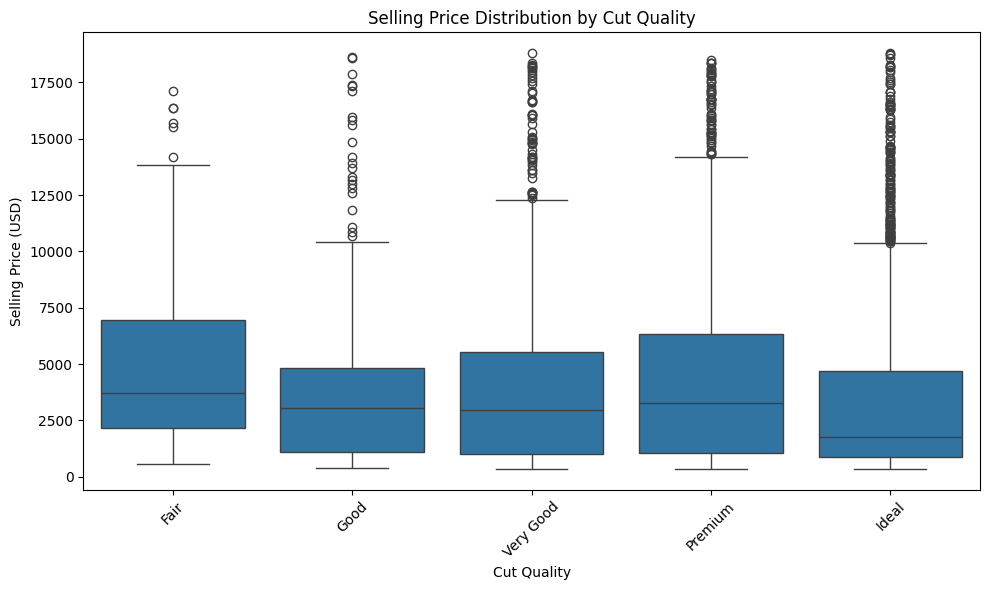

In [43]:
# Price distribution across Cut categories

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Cut',
    y='PriceUSD',
    order=cut_order
)

plt.title('Selling Price Distribution by Cut Quality')
plt.xlabel('Cut Quality')
plt.ylabel('Selling Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

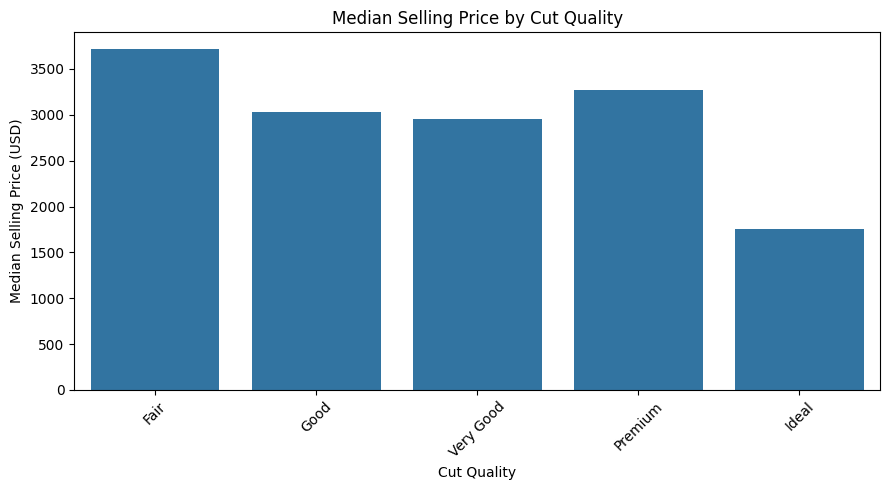

In [44]:
# Median selling price across Cut categories

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cut_price_summary.reset_index(),
    x='Cut',
    y='Median_Price',
    order=cut_order
)

plt.title('Median Selling Price by Cut Quality')
plt.xlabel('Cut Quality')
plt.ylabel('Median Selling Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# Diamond Color Analysis
# ==========================================

color_price_summary = (
    df.groupby('Color', observed=True)
      .agg(
          Diamond_Count=('PriceUSD', 'size'),
          Average_Price=('PriceUSD', 'mean'),
          Median_Price=('PriceUSD', 'median')
      )
      .round(2)
      .reindex(color_order)
)

color_price_summary

,Diamond_Count,Average_Price,Median_Price
Color,,,
J,238,5253.32,4418.5
I,461,5220.07,3610.0
H,685,4307.62,3472.0
G,965,3948.44,2123.0
F,822,3858.14,2655.5
E,784,3140.30,1694.5
D,543,3235.40,1820.0


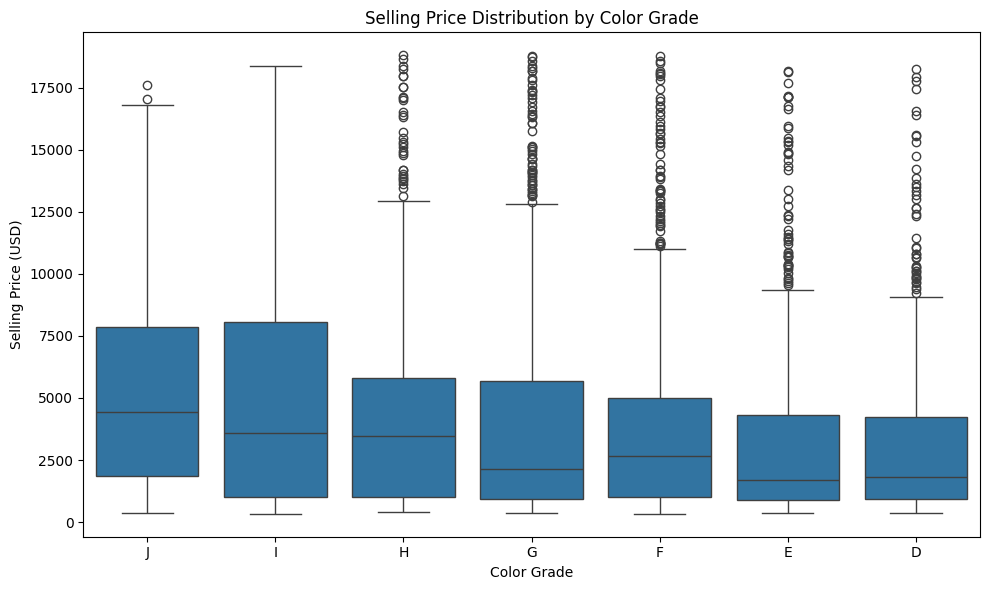

In [46]:
# Price distribution across Color grades

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Color',
    y='PriceUSD',
    order=color_order
)

plt.title('Selling Price Distribution by Color Grade')
plt.xlabel('Color Grade')
plt.ylabel('Selling Price (USD)')
plt.tight_layout()
plt.show()

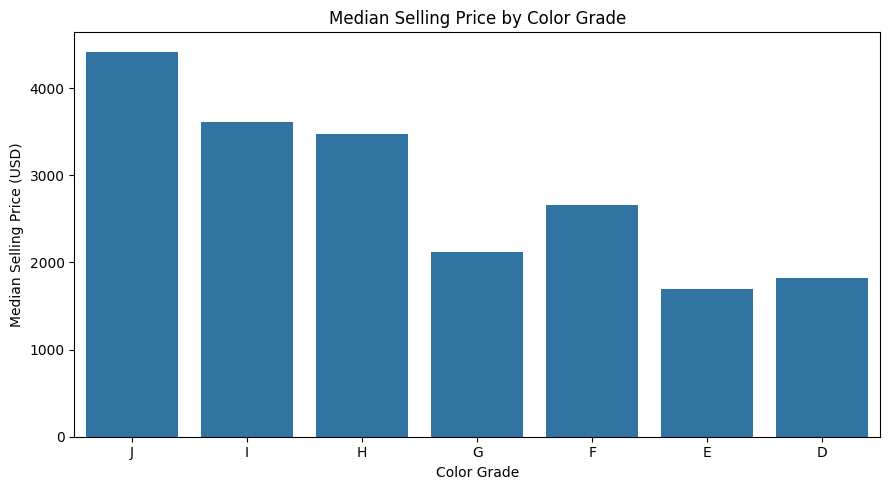

In [47]:
# Median selling price across Color grades

plt.figure(figsize=(9, 5))

sns.barplot(
    data=color_price_summary.reset_index(),
    x='Color',
    y='Median_Price',
    order=color_order
)

plt.title('Median Selling Price by Color Grade')
plt.xlabel('Color Grade')
plt.ylabel('Median Selling Price (USD)')
plt.tight_layout()
plt.show()

In [48]:
# ==========================================
# Diamond Clarity Analysis
# ==========================================

clarity_price_summary = (
    df.groupby('Clarity', observed=True)
      .agg(
          Diamond_Count=('PriceUSD', 'size'),
          Average_Price=('PriceUSD', 'mean'),
          Median_Price=('PriceUSD', 'median')
      )
      .round(2)
      .reindex(clarity_order)
)

clarity_price_summary

,Diamond_Count,Average_Price,Median_Price
Clarity,,,
I1,56,3624.82,3316.0
SI2,754,5106.44,4165.0
SI1,1098,3923.50,2838.0
VS2,1003,4121.93,2240.0
VS1,702,3761.01,1949.5
VVS2,409,3248.72,1233.0
VVS1,333,2621.77,1130.0
IF,143,3289.34,1148.0


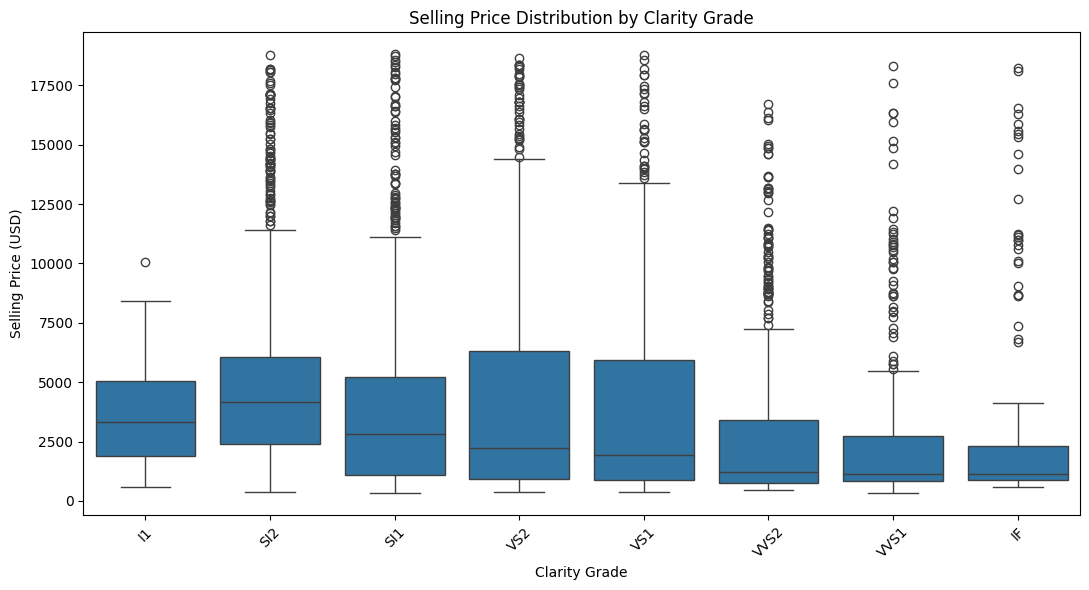

In [49]:
# Price distribution across Clarity grades

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='Clarity',
    y='PriceUSD',
    order=clarity_order
)

plt.title('Selling Price Distribution by Clarity Grade')
plt.xlabel('Clarity Grade')
plt.ylabel('Selling Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

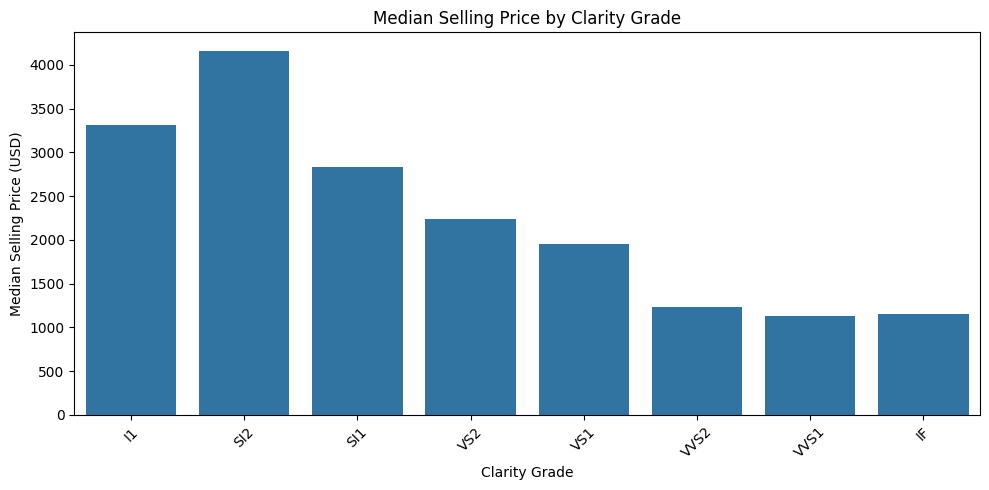

In [50]:
# Median selling price across Clarity grades

plt.figure(figsize=(10, 5))

sns.barplot(
    data=clarity_price_summary.reset_index(),
    x='Clarity',
    y='Median_Price',
    order=clarity_order
)

plt.title('Median Selling Price by Clarity Grade')
plt.xlabel('Clarity Grade')
plt.ylabel('Median Selling Price (USD)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
# ==========================================
# Carat Distribution Across Quality Categories
# ==========================================

for column, order in [
    ('Cut', cut_order),
    ('Color', color_order),
    ('Clarity', clarity_order)
]:
    carat_summary = (
        df.groupby(column, observed=True)
          .agg(
              Diamond_Count=('Carat', 'size'),
              Average_Carat=('Carat', 'mean'),
              Median_Carat=('Carat', 'median')
          )
          .round(2)
          .reindex(order)
    )

    print(f'{column} - Carat Summary:')
    display(carat_summary)

Cut - Carat Summary:


,Diamond_Count,Average_Carat,Median_Carat
Cut,,,
Fair,138,1.14,1.00
Good,407,0.84,0.90
Very Good,960,0.82,0.74
Premium,1134,0.89,0.84
Ideal,1859,0.70,0.54


Color - Carat Summary:


,Diamond_Count,Average_Carat,Median_Carat
Color,,,
J,238,1.17,1.20
I,461,1.02,0.97
H,685,0.90,0.90
G,965,0.77,0.67
F,822,0.75,0.71
E,784,0.66,0.54
D,543,0.66,0.54


Clarity - Carat Summary:


,Diamond_Count,Average_Carat,Median_Carat
Clarity,,,
I1,56,1.26,1.12
SI2,754,1.09,1.01
SI1,1098,0.85,0.76
VS2,1003,0.79,0.70
VS1,702,0.72,0.57
VVS2,409,0.59,0.42
VVS1,333,0.52,0.40
IF,143,0.52,0.36


In [52]:
# ==========================================
# Ordinal Encoding of Quality Characteristics
# ==========================================

quality_analysis = df[
    ['PriceUSD', 'Carat', 'Cut', 'Color', 'Clarity']
].copy()

cut_mapping = {
    'Fair': 1,
    'Good': 2,
    'Very Good': 3,
    'Premium': 4,
    'Ideal': 5
}

color_mapping = {
    'J': 1,
    'I': 2,
    'H': 3,
    'G': 4,
    'F': 5,
    'E': 6,
    'D': 7
}

clarity_mapping = {
    'I1': 1,
    'SI2': 2,
    'SI1': 3,
    'VS2': 4,
    'VS1': 5,
    'VVS2': 6,
    'VVS1': 7,
    'IF': 8
}

quality_analysis['Cut_Score'] = (
    quality_analysis['Cut'].map(cut_mapping)
)

quality_analysis['Color_Score'] = (
    quality_analysis['Color'].map(color_mapping)
)

quality_analysis['Clarity_Score'] = (
    quality_analysis['Clarity'].map(clarity_mapping)
)

quality_analysis[
    [
        'PriceUSD',
        'Carat',
        'Cut_Score',
        'Color_Score',
        'Clarity_Score'
    ]
].head()

,PriceUSD,Carat,Cut_Score,Color_Score,Clarity_Score
0,1547,0.97,1,4,1
1,5584,1.13,3,5,3
2,1061,0.41,5,4,4
3,2583,0.74,5,5,3
4,2839,0.71,4,5,5


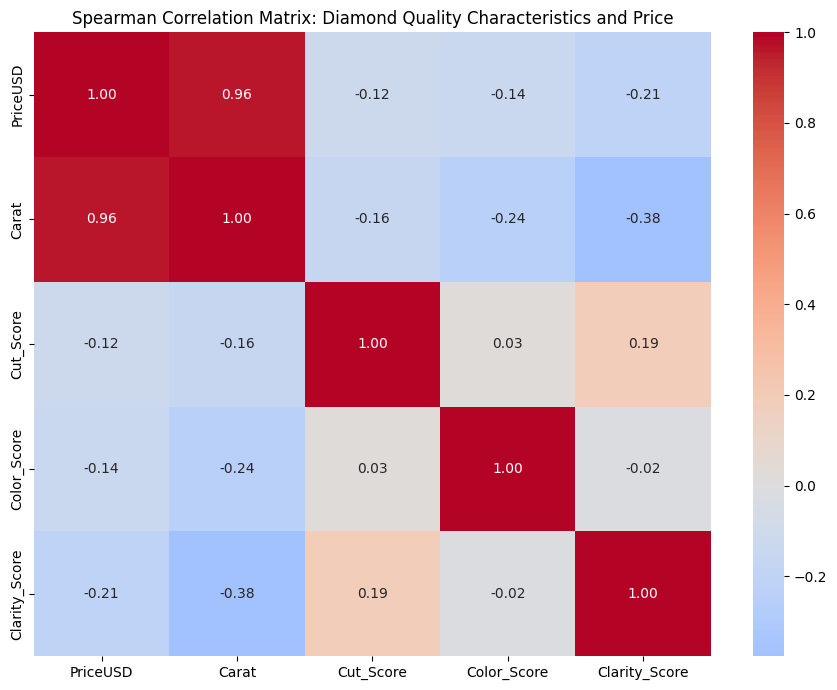

In [53]:
# ==========================================
# Spearman Correlation Matrix
# ==========================================

quality_correlation = quality_analysis[
    [
        'PriceUSD',
        'Carat',
        'Cut_Score',
        'Color_Score',
        'Clarity_Score'
    ]
].corr(method='spearman')

plt.figure(figsize=(9, 7))

sns.heatmap(
    quality_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title(
    'Spearman Correlation Matrix: '
    'Diamond Quality Characteristics and Price'
)

plt.tight_layout()
plt.show()

### Analysis and Interpretation

The analysis examined the relationship between the three primary diamond quality characteristics (Cut, Color, and Clarity) and selling price using descriptive statistics, grouped analysis, boxplots, median price comparisons, and a Spearman correlation matrix.

At first glance, the grouped summaries and boxplots suggest that lower-quality categories often have higher average and median selling prices. For example, diamonds classified as Fair, J color, and SI2 clarity generally show higher selling prices than some higher-quality categories.

However, additional investigation revealed that these lower-quality groups also contain diamonds with substantially larger average carat weights. For example, Fair diamonds have an average weight of **1.14 carats**, compared with **0.70 carats** for Ideal diamonds. Similarly, J-color diamonds average **1.17 carats**, while D-color diamonds average only **0.66 carats**. The same pattern is observed for clarity grades, where lower-clarity diamonds generally have larger average carat weights.

The Spearman correlation matrix further supports this observation. Carat weight shows an extremely strong positive correlation with selling price (**0.96**), whereas Cut (-0.12), Color (-0.14), and Clarity (-0.21) exhibit only weak negative correlations with price.

These findings indicate that the apparent price differences across quality categories are largely influenced by differences in diamond size rather than by quality characteristics alone. Therefore, carat weight acts as a confounding variable that affects the observed relationship between Cut, Color, Clarity, and selling price. The independent contribution of each quality characteristic cannot be determined from these univariate comparisons alone.

### Business Insight

Businesses should avoid evaluating diamond quality characteristics in isolation when estimating market value. Although the raw analysis suggests that lower-quality diamonds often sell for higher prices, this pattern is primarily explained by their larger average carat weights.

Accurate pricing models should therefore consider carat weight together with quality characteristics rather than relying on any single attribute. Incorporating multiple variables leads to more reliable pricing decisions and better inventory segmentation.

### Conclusion

The analysis shows that Cut, Color, and Clarity appear to influence selling price when examined individually. However, further investigation demonstrates that these relationships are strongly affected by differences in average carat weight across quality categories.

Consequently, the raw price comparisons cannot be interpreted as the direct effect of quality characteristics alone. Carat weight is the dominant pricing factor in this dataset and should be controlled before evaluating the true contribution of Cut, Color, and Clarity to diamond prices.

This finding provides the basis for a more detailed analysis in the next stage of the project, where the effect of quality characteristics can be examined while accounting for carat weight.

### 3. <strong style="color:green;">Selling Price vs. Appraisal Value</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How does the selling price compare with the appraisal value?

<strong style="color:blue;">**Objective:**</strong>  
To analyze the differences between appraisal value and actual selling price and determine whether diamonds are usually sold above or below their estimated value.

In [54]:
# ==========================================
# Descriptive Statistics
# ==========================================

df[['PriceUSD','AppraisalUSD']].describe()

,PriceUSD,AppraisalUSD
count,4498.000000,4498.000000
mean,3959.076478,4272.636727
std,3984.469787,4316.320896
min,336.000000,347.000000
25%,951.250000,1028.250000
50%,2432.500000,2643.000000
75%,5370.000000,5783.750000
max,18803.000000,22679.000000


In [55]:
# ==========================================
# Difference Between Selling Price and Appraisal Value
# ==========================================

df['PriceDifference'] = (
    df['PriceUSD'] -
    df['AppraisalUSD']
)

df['PriceDifference'].describe()

count    4498.000000
mean     -313.560249
std       459.939609
min     -4503.000000
25%      -417.000000
50%      -147.000000
75%       -54.000000
max      1085.000000
Name: PriceDifference, dtype: float64

In [56]:
# ==========================================
# Diamonds Sold Above or Below Appraisal
# ==========================================

df['SaleStatus'] = np.where(
    df['PriceDifference'] > 0,
    'Above Appraisal',
    'Below Appraisal'
)

df['SaleStatus'].value_counts()

SaleStatus
Below Appraisal    4098
Above Appraisal     400
Name: count, dtype: int64

In [57]:
# ==========================================
# Percentage of Sales
# ==========================================

(
    df['SaleStatus']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

SaleStatus
Below Appraisal    91.11
Above Appraisal     8.89
Name: proportion, dtype: float64

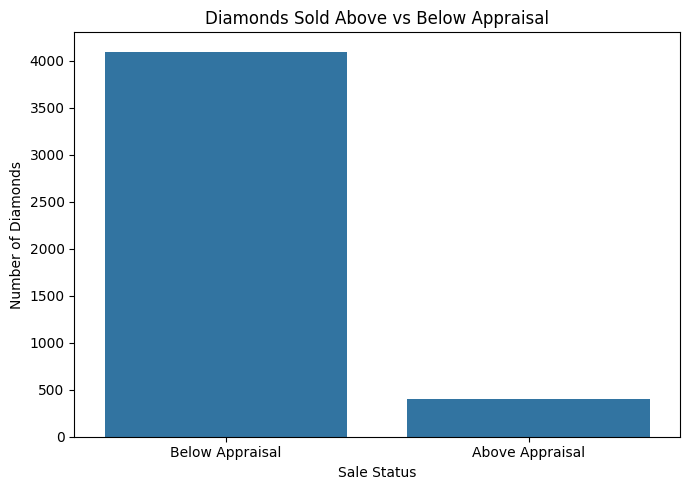

In [58]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='SaleStatus'
)

plt.title(
    'Diamonds Sold Above vs Below Appraisal'
)

plt.xlabel('Sale Status')

plt.ylabel('Number of Diamonds')

plt.tight_layout()

plt.show()

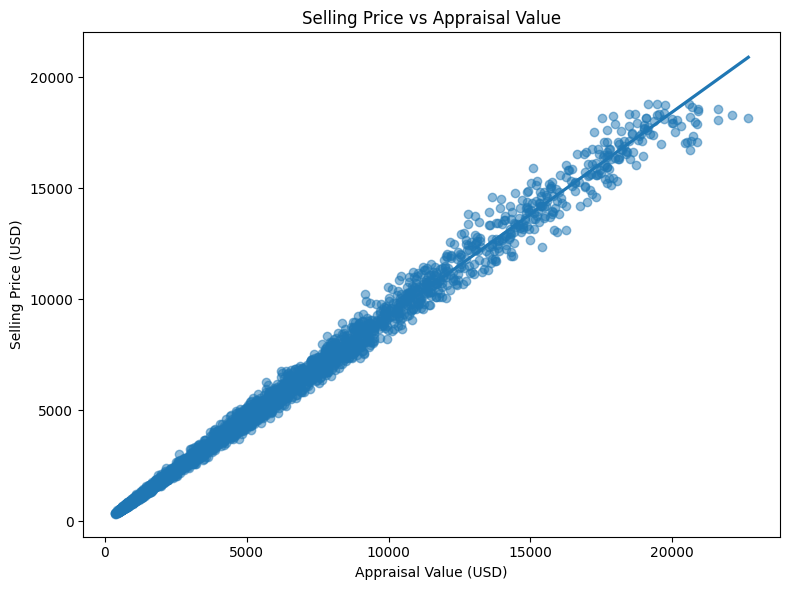

In [59]:
# ==========================================
# Selling Price vs Appraisal Value
# ==========================================

plt.figure(figsize=(8,6))

sns.regplot(
    data=df,
    x='AppraisalUSD',
    y='PriceUSD',
    scatter_kws={'alpha':0.5}
)

plt.title(
    'Selling Price vs Appraisal Value'
)

plt.xlabel('Appraisal Value (USD)')

plt.ylabel('Selling Price (USD)')

plt.tight_layout()

plt.show()

In [60]:
# ==========================================
# Correlation
# ==========================================

df[
    ['PriceUSD',
     'AppraisalUSD']
].corr()

,PriceUSD,AppraisalUSD
PriceUSD,1.000000,0.997051
AppraisalUSD,0.997051,1.000000


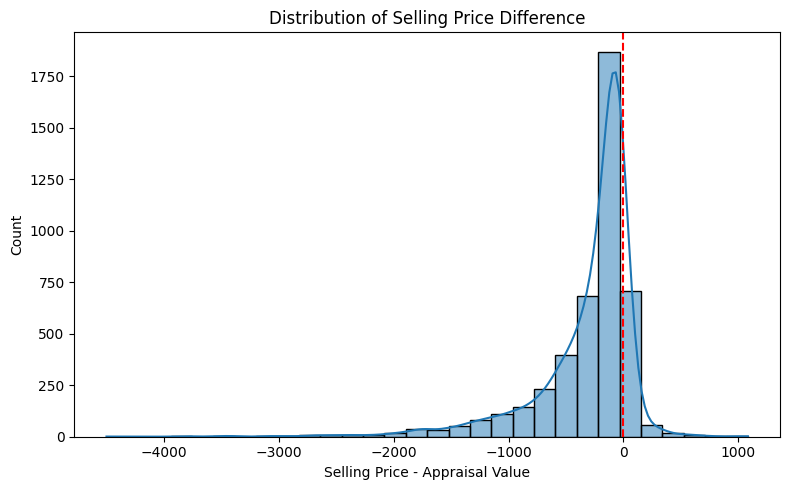

In [61]:
# ==========================================
# Distribution of Price Difference
# ==========================================

plt.figure(figsize=(8,5))

sns.histplot(
    df['PriceDifference'],
    bins=30,
    kde=True
)

plt.axvline(
    0,
    color='red',
    linestyle='--'
)

plt.title(
    'Distribution of Selling Price Difference'
)

plt.xlabel(
    'Selling Price - Appraisal Value'
)

plt.tight_layout()

plt.show()

In [62]:
# ==========================================
# Price Difference Summary
# ==========================================

df.groupby(
    'SaleStatus',
    observed=True
).agg(

    Diamonds=('PriceDifference','size'),

    Average_Difference=('PriceDifference','mean'),

    Median_Difference=('PriceDifference','median')

).round(2)

,Diamonds,Average_Difference,Median_Difference
SaleStatus,,,
Above Appraisal,400,106.9,46.0
Below Appraisal,4098,-354.6,-181.0


### Analysis and Interpretation

The analysis compared each diamond's actual selling price with its appraised value to determine whether diamonds are typically sold above or below their estimated market value.

The descriptive statistics show that selling prices and appraisal values are highly consistent. The scatter plot reveals an almost perfect positive linear relationship between the two variables, indicating that diamonds with higher appraised values generally achieve higher selling prices. This suggests that the appraisal process provides a reliable estimate of market value.

However, examining the price differences reveals an important pattern. Approximately **91%** of all diamonds were sold **below** their appraised value, while only about **9%** were sold **above** it. The histogram confirms that most price differences are negative and clustered close to zero, meaning that although diamonds are generally sold below their estimated value, the differences are usually moderate.

The grouped summary further supports these findings. Diamonds sold below appraisal had an average price difference of approximately **-$355** and a median difference of **-$181**. In contrast, diamonds sold above appraisal exceeded their estimated value by an average of approximately **$107**, with a median difference of **$46**.

Overall, the results indicate that appraisal values closely reflect market prices, although actual transactions are more likely to occur slightly below the estimated value.

### Business Insight

The findings suggest that appraisal values provide a reliable benchmark for pricing decisions. Since most diamonds are sold slightly below their estimated value, businesses should expect modest negotiation discounts during the sales process. Understanding the typical difference between appraisal and selling price can help retailers establish realistic pricing strategies, improve inventory valuation, and set customer expectations more accurately.

### Conclusion

The analysis demonstrates that appraisal value is an excellent predictor of selling price, as evidenced by the strong linear relationship between the two variables. Nevertheless, most diamonds are ultimately sold below their appraised value, indicating that market transactions commonly involve moderate discounts. Therefore, appraisal values should be viewed as realistic market estimates rather than guaranteed selling prices.

### 4. <strong style="color:green;">Diamond Discount Analysis</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How do discount percentages vary across different diamond characteristics and sales channels?

<strong style="color:blue;">**Objective:**</strong>  
To investigate whether diamond characteristics, pricing, and sales channels affect discount strategies and identify patterns in discount behavior.

In [63]:
# ==========================================
# Descriptive Statistics
# ==========================================

df['DiscountPercent'].describe()

count    4498.000000
mean        7.056158
std         5.174797
min       -16.400000
25%         3.700000
50%         7.400000
75%        10.675000
max        22.900000
Name: DiscountPercent, dtype: float64

In [64]:
# ==========================================
# Discount by Sales Channel
# ==========================================

discount_channel = (
    df.groupby(
        'SalesChannel',
        observed=True
    )
    .agg(
        Diamonds=('DiscountPercent', 'size'),
        Average_Discount=('DiscountPercent', 'mean'),
        Median_Discount=('DiscountPercent', 'median')
    )
    .round(2)
)

discount_channel

,Diamonds,Average_Discount,Median_Discount
SalesChannel,,,
Boutique,1153,6.79,7.1
Online,1123,7.08,7.4
Showroom,1538,7.18,7.6
Wholesale,684,7.19,7.5


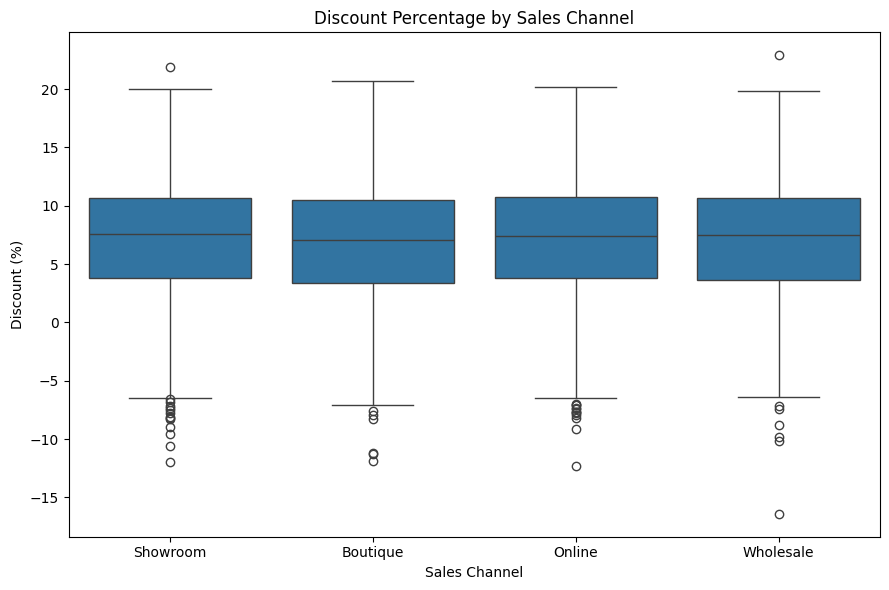

In [65]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='SalesChannel',
    y='DiscountPercent'
)

plt.title('Discount Percentage by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Discount (%)')

plt.tight_layout()
plt.show()

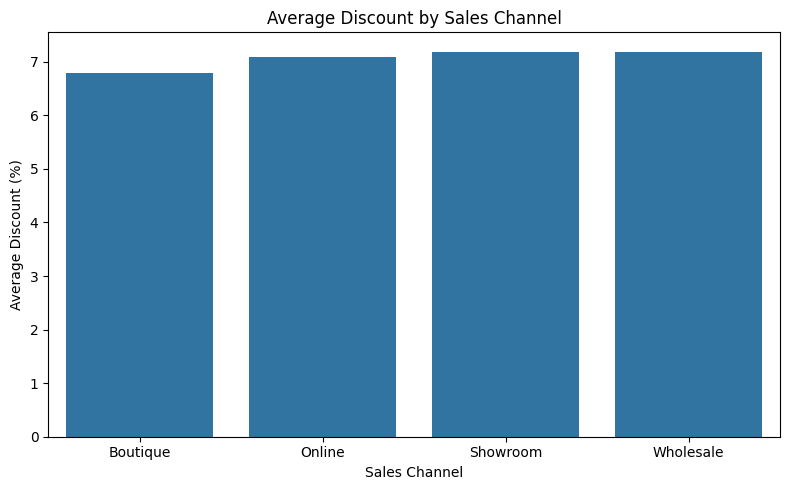

In [66]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=discount_channel.reset_index(),
    x='SalesChannel',
    y='Average_Discount'
)

plt.title('Average Discount by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Average Discount (%)')

plt.tight_layout()
plt.show()

In [67]:
# ==========================================
# Discount by Carat Group
# ==========================================

discount_carat = (
    df.groupby(
        'CaratGroup',
        observed=True
    )
    .agg(
        Diamonds=('DiscountPercent', 'size'),
        Average_Discount=('DiscountPercent', 'mean'),
        Median_Discount=('DiscountPercent', 'median')
    )
    .round(2)
)

discount_carat

,Diamonds,Average_Discount,Median_Discount
CaratGroup,,,
0-0.5,1564,7.03,7.3
0.5-1,1449,7.12,7.6
1-1.5,1020,7.02,7.2
1.5-2,317,7.43,7.9
2+,148,6.24,6.5


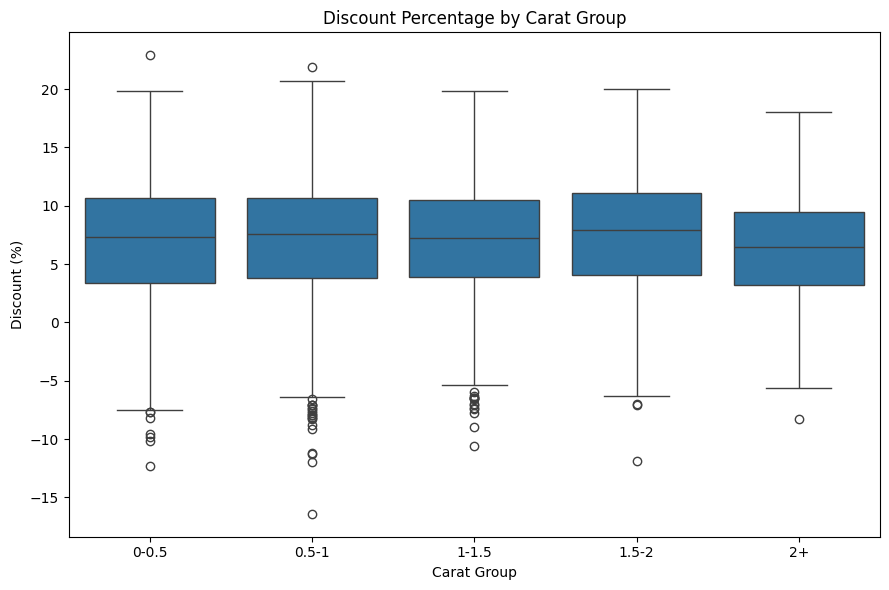

In [68]:
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='CaratGroup',
    y='DiscountPercent'
)

plt.title('Discount Percentage by Carat Group')
plt.xlabel('Carat Group')
plt.ylabel('Discount (%)')

plt.tight_layout()
plt.show()

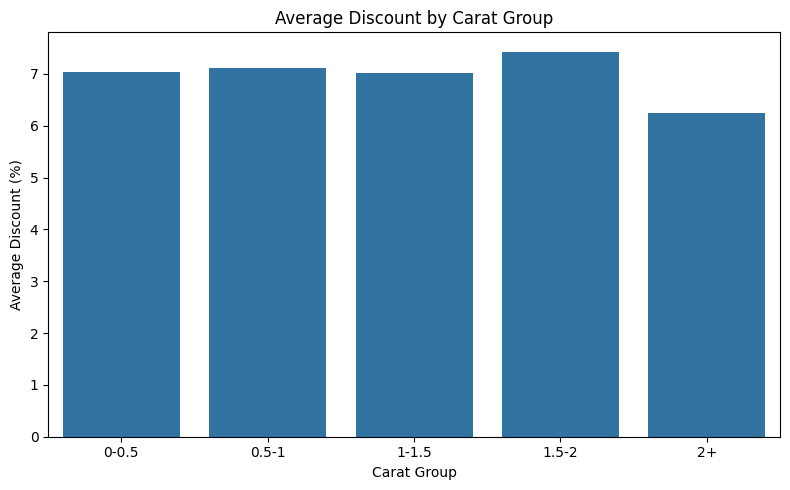

In [69]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=discount_carat.reset_index(),
    x='CaratGroup',
    y='Average_Discount'
)

plt.title('Average Discount by Carat Group')
plt.xlabel('Carat Group')
plt.ylabel('Average Discount (%)')

plt.tight_layout()
plt.show()

In [70]:
# ==========================================
# Correlation Analysis
# ==========================================

discount_corr = df[
    [
        'DiscountPercent',
        'Carat',
        'PriceUSD',
        'AppraisalUSD'
    ]
].corr()

discount_corr

,DiscountPercent,Carat,PriceUSD,AppraisalUSD
DiscountPercent,1.000000,-0.000005,0.000391,0.053920
Carat,-0.000005,1.000000,0.918771,0.914823
PriceUSD,0.000391,0.918771,1.000000,0.997051
AppraisalUSD,0.053920,0.914823,0.997051,1.000000


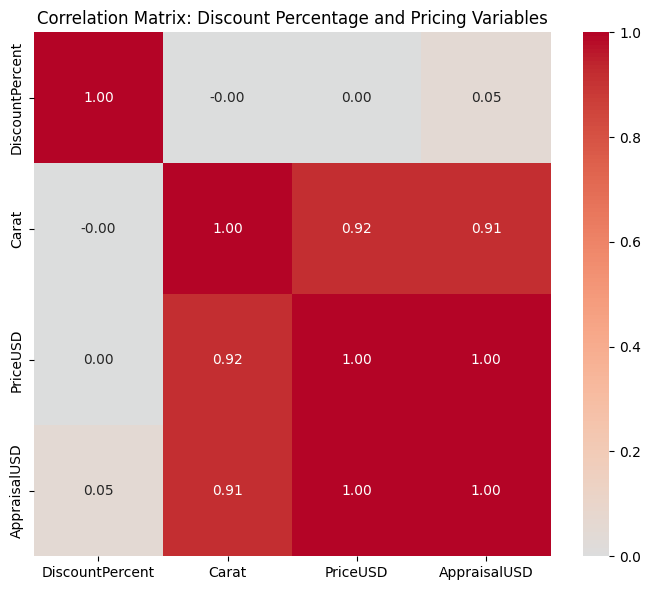

In [71]:
plt.figure(figsize=(7,6))

sns.heatmap(
    discount_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix: Discount Percentage and Pricing Variables')
plt.tight_layout()
plt.show()

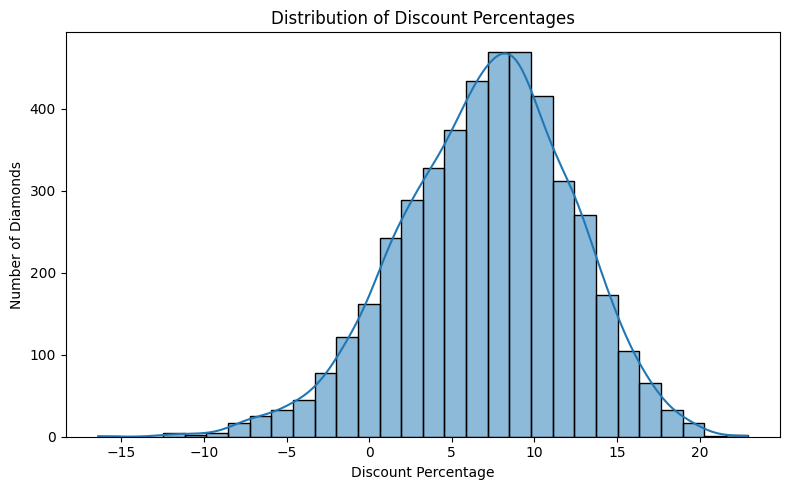

In [72]:
# ==========================================
# Distribution of Discount Percentages
# ==========================================

plt.figure(figsize=(8,5))

sns.histplot(
    df['DiscountPercent'],
    bins=30,
    kde=True
)

plt.title('Distribution of Discount Percentages')
plt.xlabel('Discount Percentage')
plt.ylabel('Number of Diamonds')

plt.tight_layout()
plt.show()

### Analysis and Interpretation

This analysis examined whether discount percentages vary according to sales channels and diamond characteristics, specifically carat weight.

The descriptive statistics indicate that discount percentages are generally concentrated around a moderate range, with most discounts falling between approximately **5% and 10%**. The histogram shows an approximately bell-shaped distribution centered near **7–8%**, suggesting that extremely high or extremely low discounts are relatively uncommon.

The comparison across sales channels reveals only small differences in discount strategies. Both the grouped summaries and boxplots show similar median discounts and comparable distributions for Showroom, Boutique, Online, and Wholesale sales. The average discounts differ only slightly, indicating that businesses apply relatively consistent discount policies regardless of the sales channel.

A similar pattern is observed across the different carat-weight groups. Although diamonds weighing **1.5–2.0 carats** receive slightly higher average discounts, while diamonds above **2 carats** receive somewhat lower discounts, the overall differences remain modest. The boxplots demonstrate considerable overlap between all carat groups, suggesting that diamond size alone is not a major determinant of discount percentage.

The correlation analysis further supports these findings. Discount percentage has virtually **no linear relationship** with carat weight (**r ≈ 0.00**) or selling price (**r ≈ 0.00**), and only a **very weak positive correlation** with appraisal value (**r ≈ 0.05**). These results indicate that discount strategies are largely independent of the main pricing variables in the dataset.

Overall, the analysis suggests that the company follows a relatively standardized discount policy rather than adjusting discounts based on diamond size, selling price, or appraisal value.

### Business Insight

The findings indicate that discount policies are applied consistently across different sales channels and diamond sizes. This consistency simplifies pricing management and provides customers with a predictable purchasing experience. Since discounts are not strongly influenced by product value, businesses may have opportunities to optimize promotional strategies by introducing more targeted discounts for specific customer segments or product categories.

### Conclusion

The analysis shows that discount percentages vary only slightly across sales channels and carat groups. Furthermore, discount percentage exhibits little to no relationship with carat weight, selling price, or appraisal value. Therefore, discount strategies appear to be relatively standardized and are not primarily driven by the physical or financial characteristics of the diamonds.

### 5. <strong style="color:green;">Sales Channel Performance Comparison</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How do selling price, discount percentage, and customer satisfaction differ across sales channels?

<strong style="color:blue;">**Objective:**</strong>  
To compare selling price, discount percentage, and customer satisfaction across different sales channels and identify differences in sales performance.

In [73]:
# ==========================================
# Sales Channel Performance Summary
# ==========================================

sales_summary = (
    df.groupby(
        'SalesChannel',
        observed=True
    )
    .agg(
        Diamonds=('DiamondID', 'size'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Average_Discount=('DiscountPercent', 'mean'),
        Median_Discount=('DiscountPercent', 'median'),
        Average_Satisfaction=('CustomerSatisfaction', 'mean'),
        Median_Satisfaction=('CustomerSatisfaction', 'median'),
        Average_Days=('DaysOnMarket', 'mean')
    )
)

sales_summary.insert(
    1,
    'Percentage',
    (
        sales_summary['Diamonds']
        / sales_summary['Diamonds'].sum()
        * 100
    )
)

sales_summary = sales_summary.round(2)

sales_summary

,Diamonds,Percentage,Average_Price,Median_Price,Average_Discount,Median_Discount,Average_Satisfaction,Median_Satisfaction,Average_Days
SalesChannel,,,,,,,,,
Boutique,1153,25.63,6478.11,5584.0,6.79,7.1,8.28,8.3,48.51
Online,1123,24.97,2819.23,1758.0,7.08,7.4,8.05,8.1,24.89
Showroom,1538,34.19,4096.06,2701.5,7.18,7.6,7.89,8.0,26.25
Wholesale,684,15.21,1276.22,808.0,7.19,7.5,7.80,7.8,23.28


In [74]:
channel_order = [
    'Showroom',
    'Boutique',
    'Online',
    'Wholesale'
]

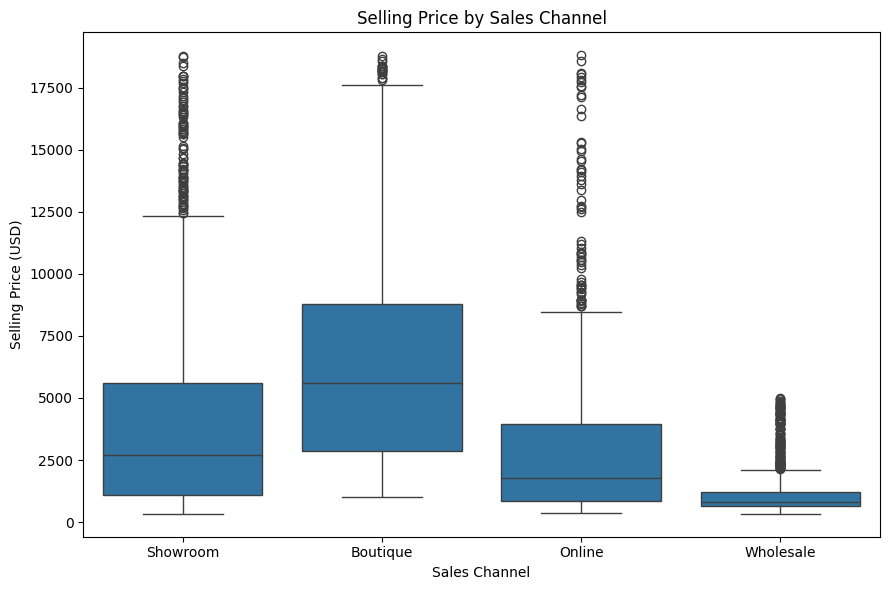

In [75]:
# ==========================================
# Selling Price by Sales Channel
# ==========================================

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='SalesChannel',
    y='PriceUSD',
    order=channel_order
)

plt.title('Selling Price by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Selling Price (USD)')

plt.tight_layout()
plt.show()

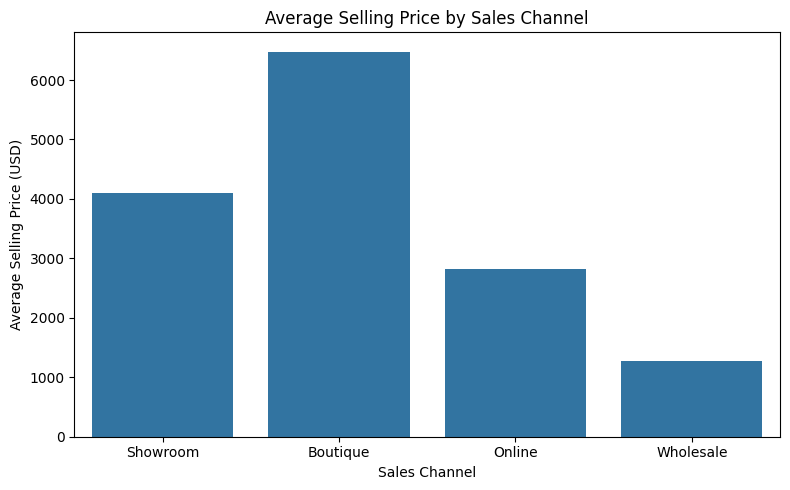

In [76]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=sales_summary.reset_index(),
    x='SalesChannel',
    y='Average_Price',
    order=channel_order
)

plt.title('Average Selling Price by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Average Selling Price (USD)')

plt.tight_layout()
plt.show()

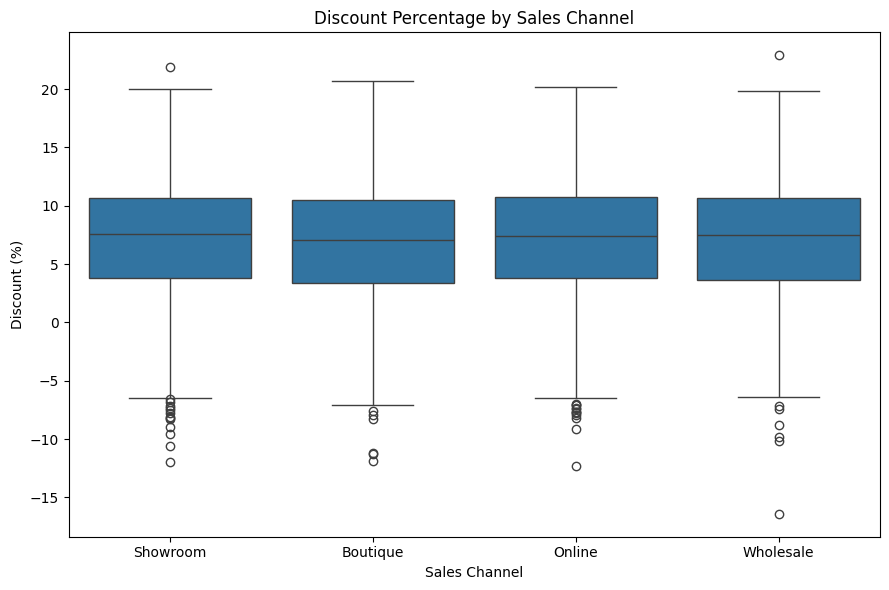

In [77]:
# ==========================================
# Discount Percentage by Sales Channel
# ==========================================

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='SalesChannel',
    y='DiscountPercent',
    order=channel_order
)

plt.title('Discount Percentage by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Discount (%)')

plt.tight_layout()
plt.show()

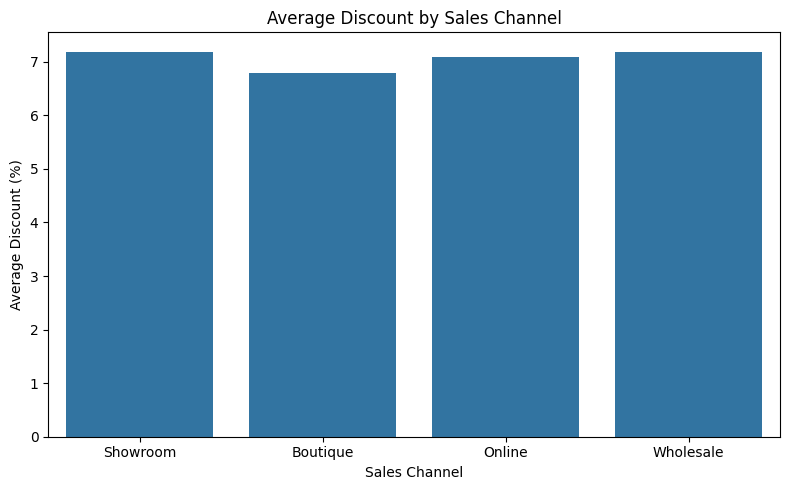

In [78]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=sales_summary.reset_index(),
    x='SalesChannel',
    y='Average_Discount',
    order=channel_order
)

plt.title('Average Discount by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Average Discount (%)')

plt.tight_layout()
plt.show()

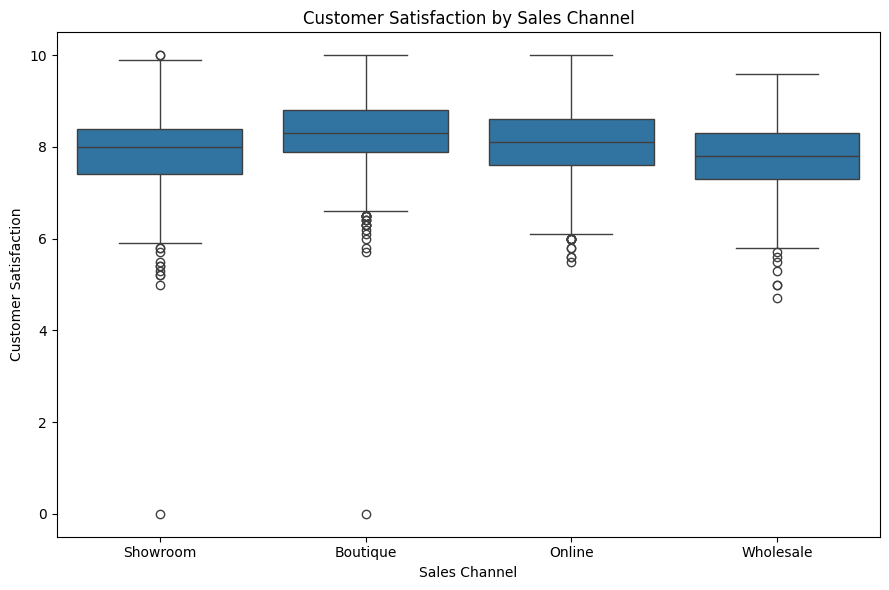

In [79]:
# ==========================================
# Customer Satisfaction by Sales Channel
# ==========================================

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='SalesChannel',
    y='CustomerSatisfaction',
    order=channel_order
)

plt.title('Customer Satisfaction by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Customer Satisfaction')

plt.tight_layout()
plt.show()

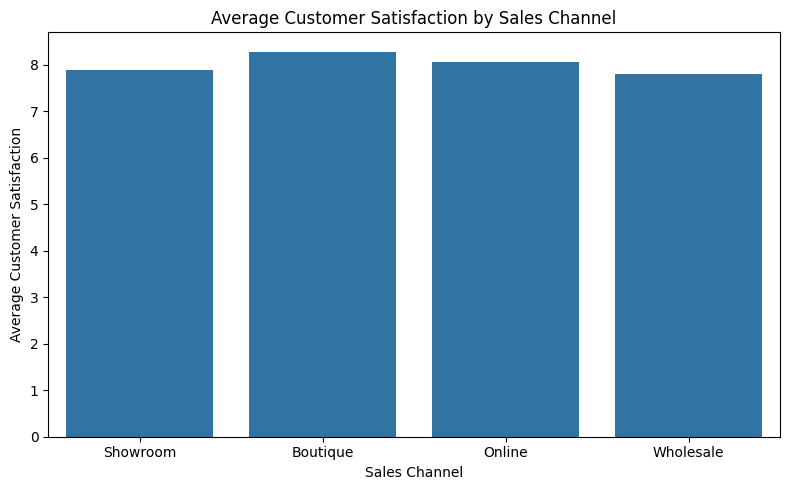

In [80]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=sales_summary.reset_index(),
    x='SalesChannel',
    y='Average_Satisfaction',
    order=channel_order
)

plt.title('Average Customer Satisfaction by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Average Customer Satisfaction')

plt.tight_layout()
plt.show()

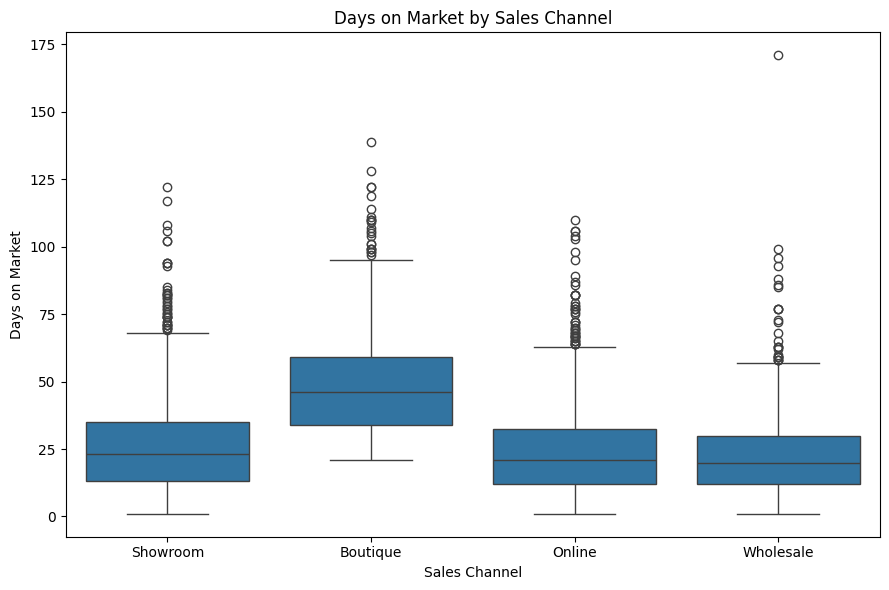

In [81]:
# ==========================================
# Days on Market by Sales Channel
# ==========================================

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='SalesChannel',
    y='DaysOnMarket',
    order=channel_order
)

plt.title('Days on Market by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Days on Market')

plt.tight_layout()
plt.show()

### Analysis and Interpretation

This analysis compared the performance of different sales channels by examining selling price, discount percentage, customer satisfaction, and average time on the market.

The results reveal substantial differences in selling prices across sales channels. **Boutique** recorded the highest average selling price (**$6,478**) with a median price of **$5,584**, indicating that it primarily sells higher-value diamonds. In contrast, **Wholesale** had the lowest average selling price (**$1,276**) and median price (**$808**), reflecting its focus on lower-priced inventory. Showroom and Online channels fell between these two extremes.

Despite these differences in selling price, discount policies remained remarkably consistent across all sales channels. Average discounts ranged only from approximately **6.8% to 7.2%**, and the boxplots showed very similar distributions. This suggests that the company applies a standardized discount strategy regardless of the sales channel.

Customer satisfaction also showed relatively small differences. Boutique achieved the highest average satisfaction score (**8.28**), followed by Online (**8.05**), Showroom (**7.89**), and Wholesale (**7.80**). Although the differences are modest, Boutique consistently demonstrated the highest customer satisfaction among all sales channels.

The analysis of **Days on Market** reveals another important pattern. Diamonds sold through the Boutique channel remained on the market for the longest period, averaging approximately **48.5 days**, whereas Wholesale (**23.3 days**), Online (**24.9 days**), and Showroom (**26.3 days**) sold considerably faster. This suggests that Boutique customers may require more time before purchasing higher-value diamonds.

Overall, the results indicate that sales channels differ substantially in the types of diamonds they sell and the time required to complete a sale, while discount strategies remain largely consistent across all channels.

### Business Insight

The Boutique channel appears to focus on premium diamonds, achieving both the highest selling prices and the highest customer satisfaction. However, these advantages come with a longer sales cycle. In contrast, Wholesale and Online channels generate faster sales but primarily for lower-priced diamonds. Since discount percentages are nearly identical across all channels, the company may benefit from developing channel-specific pricing and promotional strategies rather than applying the same discount policy everywhere.

### Conclusion

The analysis demonstrates that sales channels differ noticeably in selling price, customer satisfaction, and sales duration. Boutique specializes in high-value diamonds and achieves the highest customer satisfaction but requires longer selling periods. Wholesale and Online channels sell lower-priced diamonds more quickly, while discount percentages remain relatively consistent across all sales channels, indicating a standardized discount strategy.

### 6. <strong style="color:green;">Diamond Price Outlier Detection</strong>

<strong style="color:blue;">**Research Question:**</strong>  
Which diamonds have unusually high or low selling prices compared with the rest of the dataset?

<strong style="color:blue;">**Objective:**</strong> 
To identify diamonds with unusually high or low selling prices and determine whether these observations represent exceptional market cases or meaningful business insights.

In [82]:
# ==========================================
# Descriptive Statistics
# ==========================================

df['PriceUSD'].describe()

count     4498.000000
mean      3959.076478
std       3984.469787
min        336.000000
25%        951.250000
50%       2432.500000
75%       5370.000000
max      18803.000000
Name: PriceUSD, dtype: float64

In [83]:
# ==========================================
# IQR Method
# ==========================================

Q1 = df['PriceUSD'].quantile(0.25)
Q3 = df['PriceUSD'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print(f'Lower Bound: {lower_bound:.2f}')
print(f'Upper Bound: {upper_bound:.2f}')

Lower Bound: -5676.88
Upper Bound: 11998.12


In [84]:
# ==========================================
# Detect Price Outliers
# ==========================================

price_outliers = df[
    (df['PriceUSD'] < lower_bound) |
    (df['PriceUSD'] > upper_bound)
]

price_outliers

,DiamondID,SaleDate,Carat,Cut,Color,Clarity,DepthPct,TablePct,LengthMm,WidthMm,...,AppraisalUSD,DiscountPercent,SalesChannel,StoreLocation,Certification,DaysOnMarket,CustomerSatisfaction,CaratGroup,PriceDifference,SaleStatus
18,DIA63831,2023-11-06,1.20,Ideal,D,VVS2,62.7,56.0,6.78,6.81,...,14284,7.8,Boutique,London,GIA,64.0,8.5,1-1.5,-1119,Below Appraisal
24,DIA63828,2024-04-07,1.28,Premium,E,VS1,60.8,60.0,7.03,6.98,...,13082,6.7,Boutique,London,HRD,128.0,7.4,1-1.5,-872,Below Appraisal
32,DIA63124,2024-11-23,2.00,Fair,I,SI1,65.9,60.0,7.80,7.73,...,15514,11.3,Showroom,New York,GIA,23.0,7.9,1.5-2,-1750,Below Appraisal
35,DIA60690,2023-03-24,1.53,Ideal,G,VS1,62.2,56.0,7.36,7.31,...,15255,8.3,Boutique,London,HRD,48.0,7.4,1.5-2,-1261,Below Appraisal
39,DIA61078,2024-10-27,2.01,Ideal,I,SI1,61.9,56.0,8.16,8.08,...,16088,9.5,Online,New York,IGI,47.0,8.9,2+,-1530,Below Appraisal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4437,DIA64194,2024-05-18,1.60,Ideal,H,IF,61.5,53.0,7.57,7.69,...,17841,8.6,Boutique,New York,HRD,93.0,7.4,1.5-2,-1541,Below Appraisal
4456,DIA61400,2022-01-10,1.50,Premium,F,VS2,62.4,57.0,7.38,7.29,...,14604,8.7,Showroom,London,Uncertified,22.0,7.3,1-1.5,-1271,Below Appraisal
4471,DIA61500,2024-06-19,1.54,Ideal,G,VVS1,61.4,56.0,7.42,7.47,...,22121,17.3,Boutique,Dubai,HRD,62.0,8.4,1.5-2,-3827,Below Appraisal
4483,DIA60270,2022-01-13,1.55,Ideal,D,VS2,62.5,55.0,7.38,7.43,...,19205,9.2,Boutique,New York,IGI,88.0,8.7,1.5-2,-1764,Below Appraisal


In [85]:
# ==========================================
# Outlier Summary
# ==========================================

print(f'Total Outliers: {len(price_outliers)}')

print(
    f'Percentage of Dataset: {(len(price_outliers) / len(df) * 100):.2f}%'
)

Total Outliers: 283
Percentage of Dataset: 6.29%


In [86]:
# ==========================================
# Top 10 Highest Price Outliers
# ==========================================

price_outliers.sort_values(
    by='PriceUSD',
    ascending=False
)[
    [
        'DiamondID',
        'Carat',
        'Cut',
        'Color',
        'Clarity',
        'PriceUSD',
        'AppraisalUSD'
    ]
].head(10)

,DiamondID,Carat,Cut,Color,Clarity,PriceUSD,AppraisalUSD
1410,DIA63704,2.00,Very Good,H,SI1,18803,20574
3682,DIA61016,2.15,Ideal,G,SI2,18791,19157
1845,DIA61356,1.60,Ideal,F,VS1,18780,19469
1340,DIA61780,2.01,Ideal,G,SI1,18741,19746
2420,DIA61156,2.01,Good,H,VS2,18640,20689
1024,DIA64316,2.01,Good,G,SI1,18572,21620
3031,DIA60865,1.60,Ideal,F,VS1,18571,20888
3719,DIA64330,2.00,Premium,F,SI1,18493,20904
3691,DIA63712,2.00,Premium,H,SI1,18371,19697
2626,DIA60776,2.20,Premium,I,VS2,18364,18481


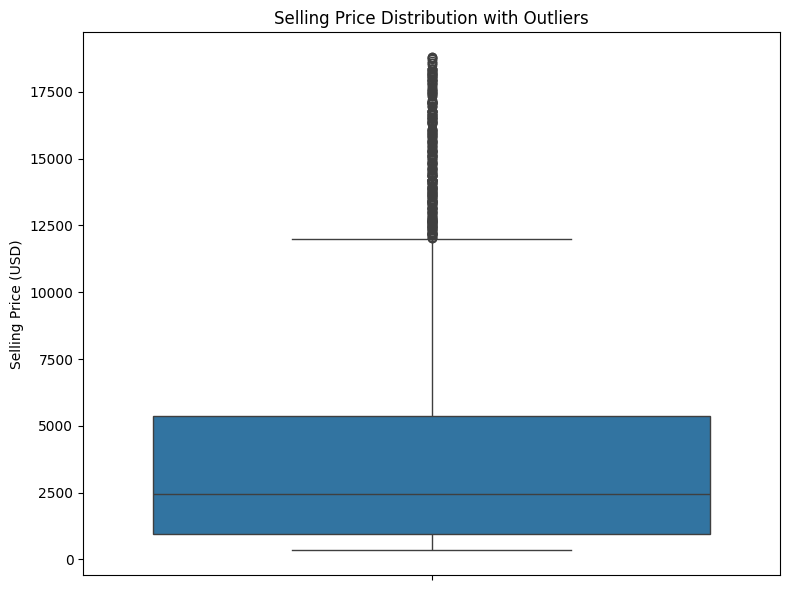

In [87]:
# ==========================================
# Selling Price Boxplot
# ==========================================

plt.figure(figsize=(8,6))

sns.boxplot(
    y=df['PriceUSD']
)

plt.title('Selling Price Distribution with Outliers')

plt.ylabel('Selling Price (USD)')

plt.tight_layout()

plt.show()

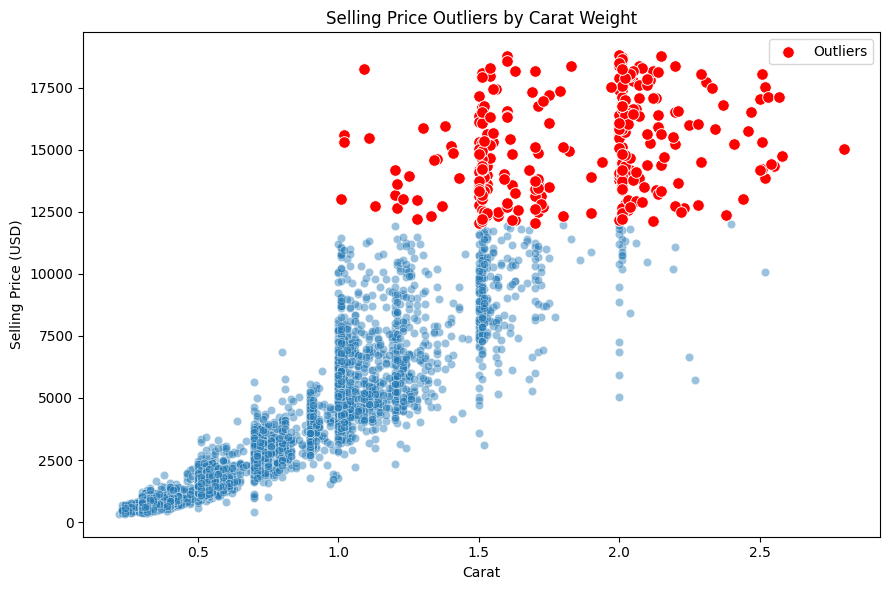

In [88]:
# ==========================================
# Carat vs Selling Price
# ==========================================

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x='Carat',
    y='PriceUSD',
    alpha=0.45
)

sns.scatterplot(
    data=price_outliers,
    x='Carat',
    y='PriceUSD',
    color='red',
    s=70,
    label='Outliers'
)

plt.title('Selling Price Outliers by Carat Weight')

plt.xlabel('Carat')

plt.ylabel('Selling Price (USD)')

plt.legend()

plt.tight_layout()

plt.show()

In [89]:
# ==========================================
# Outlier Characteristics
# ==========================================

price_outliers.groupby(
    'Cut',
    observed=True
).agg(
    Diamonds=('DiamondID', 'size'),
    Average_Carat=('Carat', 'mean'),
    Average_Price=('PriceUSD', 'mean'),
    Average_Appraisal=('AppraisalUSD', 'mean')
).round(2)

,Diamonds,Average_Carat,Average_Price,Average_Appraisal
Cut,,,,
Fair,11,2.12,14657.91,15888.18
Good,18,1.88,15333.67,16841.83
Ideal,95,1.76,14969.62,16133.92
Premium,104,1.88,15006.70,16219.50
Very Good,55,1.83,15300.44,16645.04


### Analysis and Interpretation

This analysis used the Interquartile Range (IQR) method to identify diamonds with unusually high or low selling prices. Based on the IQR thresholds, **283 diamonds (6.29% of the dataset)** were classified as price outliers.

The boxplot confirms that the majority of outliers occur above the upper whisker, indicating that the dataset contains considerably more high-price outliers than unusually low-price diamonds. This reflects the right-skewed distribution of diamond prices observed in previous analyses.

The scatter plot provides additional insight into these observations. Most outliers are concentrated among diamonds with larger carat weights, generally above approximately **1.0–1.5 carats**. This suggests that these observations are not random anomalies but are associated with larger diamonds that naturally command much higher market prices.

The summary of outlier characteristics also supports this conclusion. The identified outliers have substantially higher average carat weight, selling price, and appraisal value than the overall dataset. In addition, Premium and Ideal cut diamonds account for the largest number of price outliers, indicating that exceptional prices are primarily associated with high-quality diamonds rather than data quality issues.

Overall, the analysis suggests that these outliers represent legitimate high-value diamonds instead of erroneous observations. Therefore, they provide meaningful information about the premium segment of the diamond market and should be retained for further analysis.

### Business Insight

High-price outliers represent the luxury segment of the diamond market. Rather than treating these observations as errors, businesses should analyze them separately because they reflect premium products with distinct pricing behavior. Understanding these exceptional diamonds can support pricing strategies, inventory planning, and targeted marketing for high-value customers.

### Conclusion

The IQR analysis identified **283 price outliers (6.29% of the dataset)**. These diamonds are primarily characterized by larger carat weights and substantially higher selling prices and appraisal values. The findings indicate that the detected outliers represent genuine premium diamonds rather than data anomalies, making them valuable observations for business analysis instead of records that should be removed.

### 7. <strong style="color:green;">Diamond Sales Trends Over Time</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How did diamond sales volume and selling prices change over time?

<strong style="color:blue;">**Objective:**</strong>  
To examine monthly sales activity and price trends, identify changes in market performance, and determine whether sales volume and diamond prices followed consistent patterns over the observed period.

In [90]:
# ==========================================
# Monthly Diamond Sales Summary
# ==========================================

df['SaleMonth'] = (
    df['SaleDate']
    .dt.to_period('M')
    .dt.to_timestamp()
)

monthly_sales_summary = (
    df.groupby(
        'SaleMonth',
        observed=True
    )
    .agg(
        Diamonds_Sold=('DiamondID', 'size'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Total_Sales_Value=('PriceUSD', 'sum')
    )
    .round(2)
    .reset_index()
)

monthly_sales_summary

,SaleMonth,Diamonds_Sold,Average_Price,Median_Price,Total_Sales_Value
0,2022-01-01,57,3751.67,1956.0,213845
1,2022-02-01,77,4391.52,2732.0,338147
2,2022-03-01,81,4784.22,3303.0,387522
3,2022-04-01,91,4041.93,2860.0,367816
4,2022-05-01,88,4769.80,2673.5,419742
5,2022-06-01,106,3834.82,1995.5,406491
6,2022-07-01,115,4146.50,2553.0,476848
7,2022-08-01,103,3155.65,2188.0,325032
8,2022-09-01,107,4096.11,2239.0,438284
9,2022-10-01,104,3890.51,2124.5,404613


In [91]:
# ==========================================
# Annual Diamond Sales Summary
# ==========================================

annual_sales_summary = (
    df.assign(
        SaleYear=df['SaleDate'].dt.year
    )
    .groupby(
        'SaleYear',
        observed=True
    )
    .agg(
        Diamonds_Sold=('DiamondID', 'size'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Total_Sales_Value=('PriceUSD', 'sum')
    )
    .round(2)
)

annual_sales_summary['Sales_Volume_Growth_Percent'] = (
    annual_sales_summary['Diamonds_Sold']
    .pct_change()
    .mul(100)
    .round(2)
)

annual_sales_summary['Sales_Value_Growth_Percent'] = (
    annual_sales_summary['Total_Sales_Value']
    .pct_change()
    .mul(100)
    .round(2)
)

annual_sales_summary

,Diamonds_Sold,Average_Price,Median_Price,Total_Sales_Value,Sales_Volume_Growth_Percent,Sales_Value_Growth_Percent
SaleYear,,,,,,
2022,1228,4088.35,2554.0,5020498,NaN,NaN
2023,1578,3783.44,2318.0,5970276,28.50,18.92
2024,1692,4029.05,2429.0,6817152,7.22,14.18


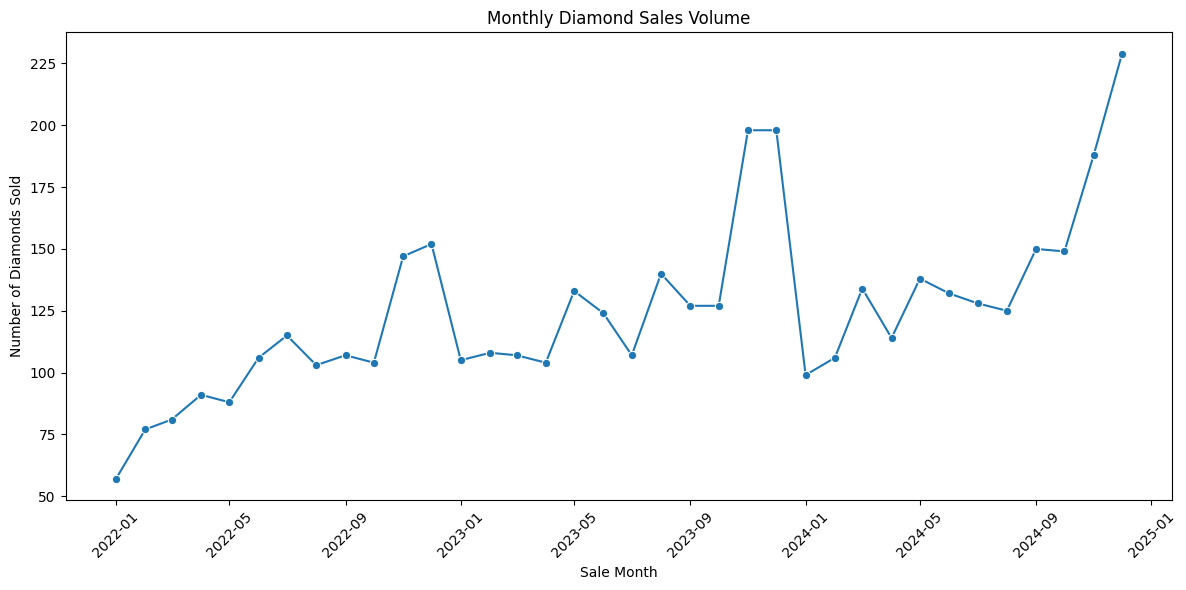

In [92]:
# ==========================================
# Monthly Sales Volume Trend
# ==========================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales_summary,
    x='SaleMonth',
    y='Diamonds_Sold',
    marker='o'
)

plt.title('Monthly Diamond Sales Volume')
plt.xlabel('Sale Month')
plt.ylabel('Number of Diamonds Sold')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

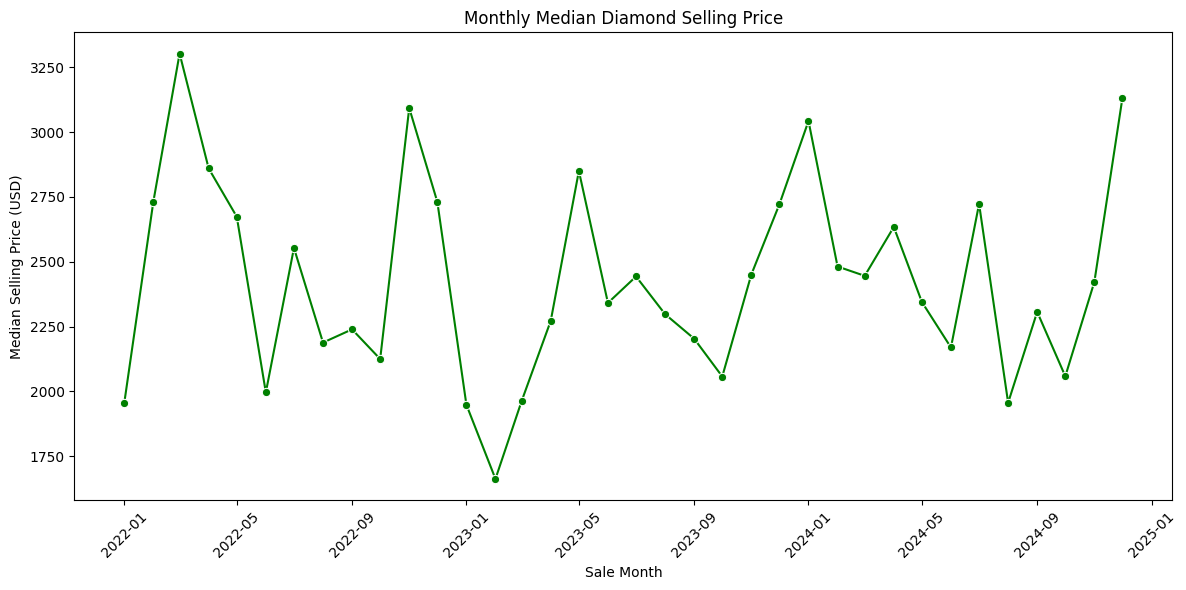

In [93]:
# ==========================================
# Monthly Median Selling Price Trend
# ==========================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales_summary,
    x='SaleMonth',
    y='Median_Price',
    marker='o',
    color='green'
)

plt.title('Monthly Median Diamond Selling Price')
plt.xlabel('Sale Month')
plt.ylabel('Median Selling Price (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Analysis and Interpretation

The time-based analysis examined changes in monthly and annual diamond sales volume, selling prices, and total sales value between 2022 and 2024.

The annual summary reveals a clear increase in sales activity. The number of diamonds sold increased from **1,228 in 2022** to **1,578 in 2023**, representing annual growth of **28.50%**. Sales volume increased further to **1,692 diamonds in 2024**, although the annual growth rate slowed to **7.22%**. Overall, the number of diamonds sold increased by approximately **37.8%** between 2022 and 2024.

Total sales value also increased throughout the observed period, rising from approximately **$5.02 million in 2022** to **$5.97 million in 2023** and **$6.82 million in 2024**. This represents annual sales-value growth of **18.92%** in 2023 and **14.18%** in 2024, as well as an overall increase of approximately **35.8%** between 2022 and 2024.

However, selling prices did not follow a consistent upward trend. The average selling price decreased from approximately **$4,088 in 2022** to **$3,783 in 2023**, before recovering to approximately **$4,029 in 2024**. Similarly, the median price declined from **$2,554** to **$2,318** and then increased to **$2,429**. The monthly median-price graph also shows frequent fluctuations without a clear long-term upward or downward pattern.

The monthly sales-volume graph indicates particularly strong sales activity toward the end of each year. November and December consistently recorded relatively high sales volumes, with **December 2024 reaching the highest monthly volume of 229 diamonds** and the highest monthly sales value of approximately **$971,986**. This recurring pattern suggests possible end-of-year seasonality, although additional years of data would be required to confirm a stable seasonal effect.

Overall, the increase in total sales value appears to have been driven primarily by higher sales volume rather than by a consistent increase in diamond prices.

### Business Insight

The growth in annual sales volume and total sales value indicates expanding market activity over the observed period. Retailers can use this information to improve demand forecasting, inventory planning, staffing, and sales-target preparation.

The recurring increase in activity during November and December suggests that businesses may benefit from preparing additional inventory and marketing resources before the end-of-year sales period. Promotional campaigns, product availability, and staffing levels could be adjusted in advance to support the higher observed demand.

At the same time, the absence of a consistent upward trend in selling prices indicates that revenue growth should not be expected to come from price increases alone. Businesses should continue focusing on sales volume, product mix, inventory turnover, and channel performance while maintaining pricing strategies that reflect diamond characteristics and market conditions.

Because the dataset contains only three years of observations, the apparent end-of-year pattern should be treated as a useful planning indication rather than definitive proof of seasonality.

### Conclusion

The time-based analysis identified substantial growth in diamond sales activity between 2022 and 2024. Annual sales volume increased from **1,228 to 1,692 diamonds**, while total sales value rose from approximately **$5.02 million to $6.82 million**.

Despite this growth, average and median selling prices fluctuated and did not demonstrate a consistent long-term trend. This indicates that the increase in total sales value was driven mainly by the growing number of diamonds sold rather than by continuous price appreciation.

Monthly results also showed recurring increases in sales activity toward the end of each year, particularly during November and December. Although this pattern may indicate seasonal demand, additional years of data would be necessary to confirm it.

Overall, the findings demonstrate the value of time-based analysis for understanding sales growth, supporting inventory planning, and identifying periods of increased market activity.

# 4. <strong style="color:darkblue;">Subgroup Analysis and Population Comparison</strong>

### 1. <strong style="color:green;">Premium vs. Standard Diamond Comparison</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How do premium-quality diamonds differ from standard-quality diamonds in terms of selling price, customer satisfaction, and days on market?

<strong style="color:blue;">**Objective:**</strong>  
To compare premium and standard diamond groups and identify differences in pricing, customer satisfaction, and sales performance.

In [94]:
# ==========================================
# Create Premium and Standard Quality Groups
# ==========================================

premium_cuts = ['Ideal', 'Premium']
standard_cuts = ['Very Good', 'Good', 'Fair']

df['QualityGroup'] = np.select(
    [
        df['Cut'].isin(premium_cuts),
        df['Cut'].isin(standard_cuts)
    ],
    [
        'Premium',
        'Standard'
    ],
    default='Unknown'
)

df['QualityGroup'].value_counts()

QualityGroup
Premium     2993
Standard    1505
Name: count, dtype: int64

In [95]:
df[df['QualityGroup'] == 'Unknown']['Cut'].value_counts()

Series([], Name: count, dtype: int64)

In [96]:
# ==========================================
# Premium vs Standard Summary
# ==========================================

quality_group_summary = (
    df.groupby(
        'QualityGroup',
        observed=True
    )
    .agg(
        Diamonds=('DiamondID', 'size'),
        Average_Carat=('Carat', 'mean'),
        Median_Carat=('Carat', 'median'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Average_Satisfaction=('CustomerSatisfaction', 'mean'),
        Median_Satisfaction=('CustomerSatisfaction', 'median'),
        Average_Days=('DaysOnMarket', 'mean'),
        Median_Days=('DaysOnMarket', 'median')
    )
    .round(2)
)

quality_group_summary

,Diamonds,Average_Carat,Median_Carat,Average_Price,Median_Price,Average_Satisfaction,Median_Satisfaction,Average_Days,Median_Days
QualityGroup,,,,,,,,,
Premium,2993,0.77,0.60,3875.90,2077.0,8.02,8.1,31.19,28.0
Standard,1505,0.86,0.83,4124.49,3084.0,8.01,8.1,31.11,28.0


In [97]:
quality_group_order = [
    'Standard',
    'Premium'
]

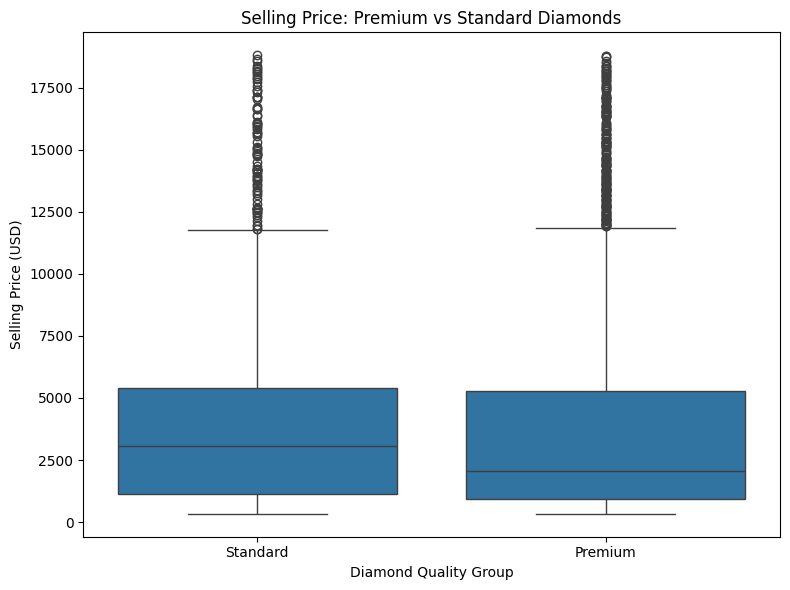

In [98]:
# ==========================================
# Selling Price Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='PriceUSD',
    order=quality_group_order
)

plt.title('Selling Price: Premium vs Standard Diamonds')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Selling Price (USD)')

plt.tight_layout()
plt.show()

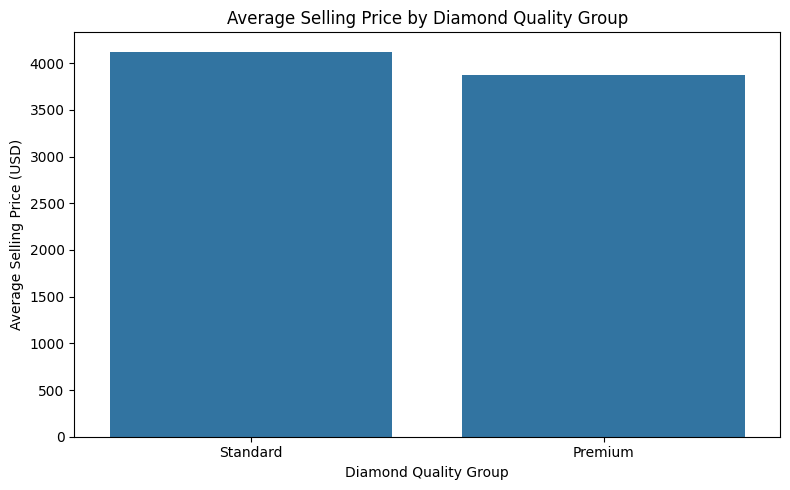

In [99]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quality_group_summary.reset_index(),
    x='QualityGroup',
    y='Average_Price',
    order=quality_group_order
)

plt.title('Average Selling Price by Diamond Quality Group')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Average Selling Price (USD)')

plt.tight_layout()
plt.show()

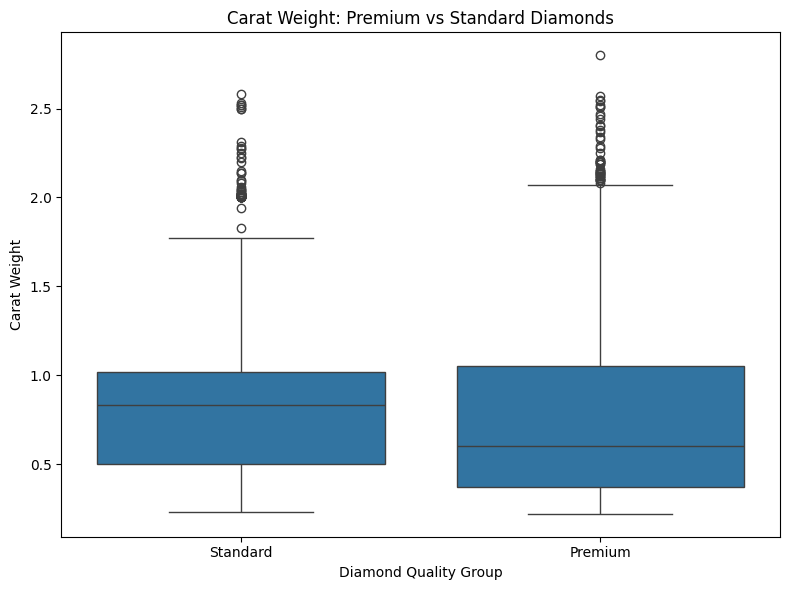

In [100]:
# ==========================================
# Carat Weight Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='Carat',
    order=quality_group_order
)

plt.title('Carat Weight: Premium vs Standard Diamonds')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Carat Weight')

plt.tight_layout()
plt.show()

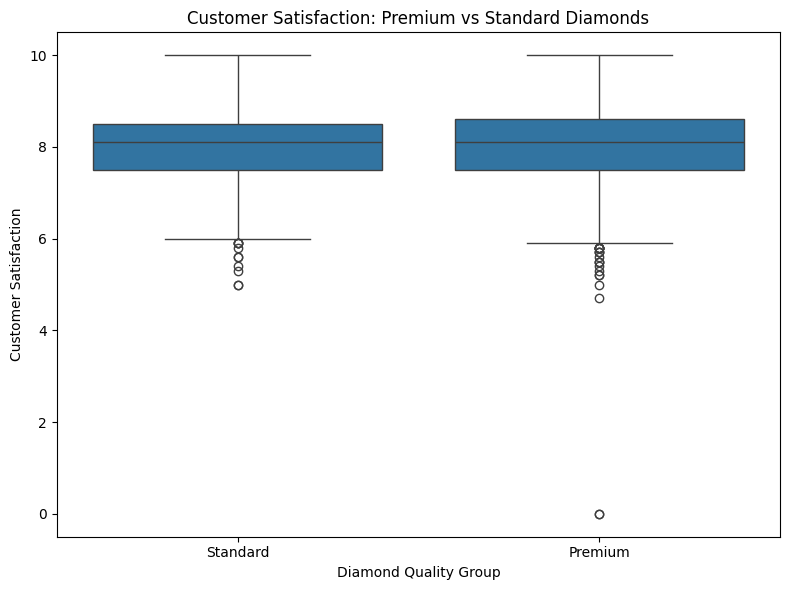

In [101]:
# ==========================================
# Customer Satisfaction Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='CustomerSatisfaction',
    order=quality_group_order
)

plt.title('Customer Satisfaction: Premium vs Standard Diamonds')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Customer Satisfaction')

plt.tight_layout()
plt.show()

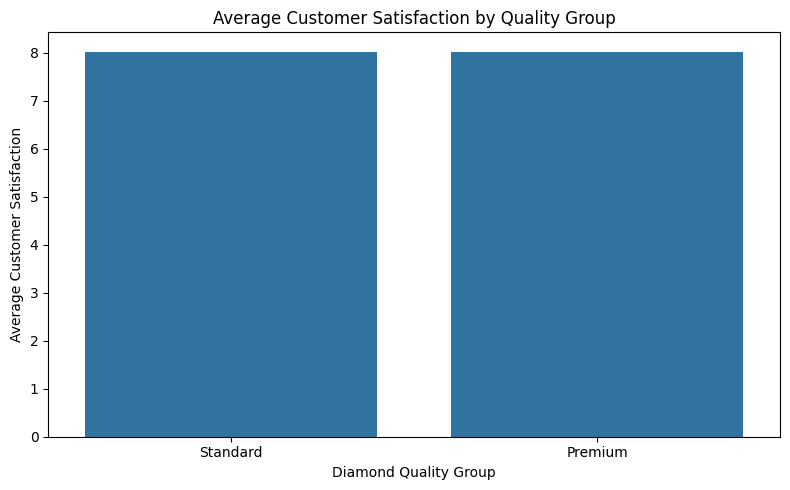

In [102]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quality_group_summary.reset_index(),
    x='QualityGroup',
    y='Average_Satisfaction',
    order=quality_group_order
)

plt.title('Average Customer Satisfaction by Quality Group')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Average Customer Satisfaction')

plt.tight_layout()
plt.show()

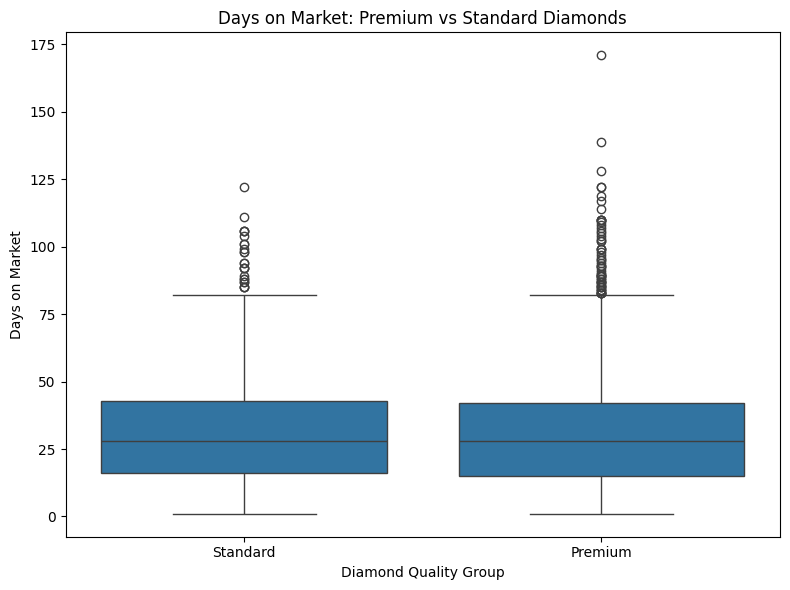

In [103]:
# ==========================================
# Days on Market Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='DaysOnMarket',
    order=quality_group_order
)

plt.title('Days on Market: Premium vs Standard Diamonds')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Days on Market')

plt.tight_layout()
plt.show()

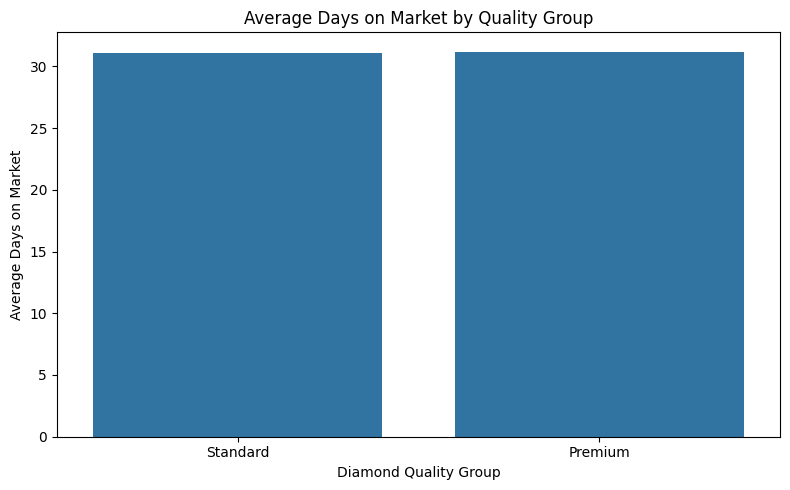

In [104]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quality_group_summary.reset_index(),
    x='QualityGroup',
    y='Average_Days',
    order=quality_group_order
)

plt.title('Average Days on Market by Quality Group')
plt.xlabel('Diamond Quality Group')
plt.ylabel('Average Days on Market')

plt.tight_layout()
plt.show()

In [105]:
# ==========================================
# Quality Group Distribution
# ==========================================

quality_group_distribution = pd.DataFrame({
    'Count': df['QualityGroup'].value_counts(),
    'Percentage': (
        df['QualityGroup']
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

quality_group_distribution

,Count,Percentage
QualityGroup,,
Premium,2993,66.54
Standard,1505,33.46


### Analysis and Interpretation

This analysis compared Premium and Standard diamond groups to evaluate differences in selling price, customer satisfaction, and market performance.

The comparison revealed an unexpected result. Although Premium diamonds represent higher cut quality (Ideal and Premium), the Standard group recorded a slightly higher average selling price. The average selling price was approximately **$4,124** for Standard diamonds compared with approximately **$3,876** for Premium diamonds.

The carat comparison provides an explanation for this finding. Standard diamonds have a higher average carat weight than Premium diamonds, indicating that the higher selling prices are largely associated with larger diamond sizes rather than cut quality alone. This suggests that carat weight has a stronger influence on selling price than the Premium versus Standard quality classification.

Customer satisfaction was nearly identical between the two groups, with both maintaining an average score of approximately **8 out of 10**. Similarly, the average number of days on market was almost the same for both groups, indicating that the quality grouping had little impact on sales speed.

Overall, the analysis suggests that grouping diamonds into Premium and Standard categories does not, by itself, explain differences in market performance. Instead, diamond size appears to be the primary factor influencing selling price, while customer satisfaction and sales duration remain largely consistent across both groups.

### Business Insight

Although Premium cut diamonds are generally perceived as higher-quality products, this analysis demonstrates that pricing decisions should not rely on cut quality alone. Businesses should place greater emphasis on carat weight when estimating market value, while recognizing that Premium and Standard diamonds achieve similar customer satisfaction and comparable sales performance.

### Conclusion

The comparison between Premium and Standard diamonds shows that the two groups perform similarly in terms of customer satisfaction and time on the market. Surprisingly, Standard diamonds achieved a slightly higher average selling price, which is largely explained by their higher average carat weight. These findings reinforce the conclusion from the previous chapter that carat weight is a stronger determinant of selling price than cut category alone.

# 5. <strong style="color:darkblue;">Deep Analysis</strong>

## 1. <strong style="color:green;">In-Depth Analysis of Premium and Standard Diamond Pricing</strong>

<strong style="color:blue;">**Research Question:**</strong>  
What factors explain the unexpected selling-price difference between Premium and Standard diamonds?

<strong style="color:blue;">**Objective:**</strong>  
To determine whether differences in carat weight, appraisal value, and discount percentage explain why Standard diamonds achieved a higher average selling price than Premium diamonds.

In [106]:
# ==========================================
# Verify Premium and Standard Groups
# ==========================================

df['QualityGroup'].value_counts()

QualityGroup
Premium     2993
Standard    1505
Name: count, dtype: int64

In [107]:
# ==========================================
# Detailed Premium vs Standard Summary
# ==========================================

deep_quality_summary = (
    df.groupby(
        'QualityGroup',
        observed=True
    )
    .agg(
        Diamonds=('DiamondID', 'size'),
        Average_Carat=('Carat', 'mean'),
        Median_Carat=('Carat', 'median'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Average_Appraisal=('AppraisalUSD', 'mean'),
        Median_Appraisal=('AppraisalUSD', 'median'),
        Average_Discount=('DiscountPercent', 'mean'),
        Median_Discount=('DiscountPercent', 'median'),
        Average_Satisfaction=('CustomerSatisfaction', 'mean'),
        Average_Days=('DaysOnMarket', 'mean')
    )
    .round(2)
)

deep_quality_summary

,Diamonds,Average_Carat,Median_Carat,Average_Price,Median_Price,Average_Appraisal,Median_Appraisal,Average_Discount,Median_Discount,Average_Satisfaction,Average_Days
QualityGroup,,,,,,,,,,,
Premium,2993,0.77,0.60,3875.90,2077.0,4181.44,2245.0,7.16,7.5,8.02,31.19
Standard,1505,0.86,0.83,4124.49,3084.0,4454.00,3330.0,6.86,7.2,8.01,31.11


In [108]:
# ==========================================
# Additional Pricing Measures
# ==========================================

df['PriceAppraisalDifference'] = (
    df['PriceUSD'] - df['AppraisalUSD']
)

df['PriceToAppraisalRatio'] = (
    df['PriceUSD'] / df['AppraisalUSD']
)

In [109]:
# ==========================================
# Pricing Difference by Quality Group
# ==========================================

pricing_difference_summary = (
    df.groupby(
        'QualityGroup',
        observed=True
    )
    .agg(
        Average_Price_Difference=(
            'PriceAppraisalDifference',
            'mean'
        ),
        Median_Price_Difference=(
            'PriceAppraisalDifference',
            'median'
        ),
        Average_Price_Ratio=(
            'PriceToAppraisalRatio',
            'mean'
        ),
        Median_Price_Ratio=(
            'PriceToAppraisalRatio',
            'median'
        )
    )
    .round(3)
)

pricing_difference_summary

,Average_Price_Difference,Median_Price_Difference,Average_Price_Ratio,Median_Price_Ratio
QualityGroup,,,,
Premium,-305.540,-138.0,0.928,0.925
Standard,-329.511,-170.0,0.931,0.928


In [110]:
# ==========================================
# Price Comparison Within Similar Carat Groups
# ==========================================

controlled_price_summary = (
    df.groupby(
        ['CaratGroup', 'QualityGroup'],
        observed=True
    )
    .agg(
        Diamonds=('DiamondID', 'size'),
        Average_Carat=('Carat', 'mean'),
        Median_Carat=('Carat', 'median'),
        Average_Price=('PriceUSD', 'mean'),
        Median_Price=('PriceUSD', 'median'),
        Average_Appraisal=('AppraisalUSD', 'mean'),
        Average_Discount=('DiscountPercent', 'mean')
    )
    .round(2)
)

controlled_price_summary

Diamonds  Average_Carat  Median_Carat  Average_Price  \
CaratGroup QualityGroup                                                         
0-0.5      Premium           1147           0.35          0.33         858.76   
           Standard           417           0.36          0.33         790.60   
0.5-1      Premium            873           0.69          0.70        2653.51   
           Standard           576           0.78          0.75        3030.31   
1-1.5      Premium            675           1.14          1.11        6652.72   
           Standard           345           1.15          1.09        6341.86   
1.5-2      Premium            203           1.63          1.58       11635.84   
           Standard           114           1.64          1.55       10421.80   
2+         Premium             95           2.15          2.07       15225.14   
           Standard            53           2.13          2.03       14267.92   

                         Median_Price  Average_Appraisal  Average_Discount  
CaratGroup QualityGroup                                                     
0-0.5      Premium              819.0             927.96              7.19  
           Standard             694.0             850.19              6.57  
0.5-1      Premium             2364.0            2864.67              7.14  
           Standard            2823.5            3274.72              7.08  
1-1.5      Premium             6066.0            7190.18              7.29  
           Standard            5599.0            6806.10              6.49  
1.5-2      Premium            11198.0           12588.68              7.17  
           Standard            9494.0           11378.56              7.89  
2+         Premium            15509.0           16220.55              5.88  
           Standard           14194.0           15419.68              6.89

In [111]:
# ==========================================
# Median Price Difference Within Carat Groups
# ==========================================

median_price_pivot = (
    controlled_price_summary[
        'Median_Price'
    ]
    .unstack('QualityGroup')
)

median_price_pivot['Premium_Minus_Standard'] = (
    median_price_pivot['Premium']
    - median_price_pivot['Standard']
)

median_price_pivot.round(2)

QualityGroup,Premium,Standard,Premium_Minus_Standard
CaratGroup,,,
0-0.5,819.0,694.0,125.0
0.5-1,2364.0,2823.5,-459.5
1-1.5,6066.0,5599.0,467.0
1.5-2,11198.0,9494.0,1704.0
2+,15509.0,14194.0,1315.0


In [112]:
# ==========================================
# Sample Size Within Each Carat Group
# ==========================================

sample_size_pivot = (
    controlled_price_summary[
        'Diamonds'
    ]
    .unstack('QualityGroup')
)

sample_size_pivot

QualityGroup,Premium,Standard
CaratGroup,,
0-0.5,1147,417
0.5-1,873,576
1-1.5,675,345
1.5-2,203,114
2+,95,53


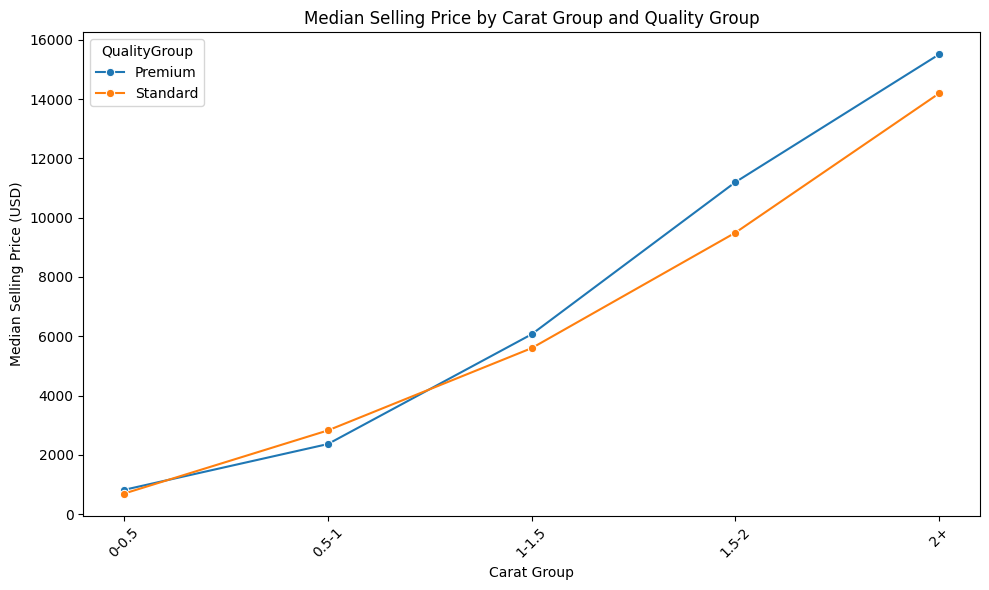

In [113]:
# ==========================================
# Median Price by Carat Group and Quality Group
# ==========================================

controlled_plot_data = (
    controlled_price_summary
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=controlled_plot_data,
    x='CaratGroup',
    y='Median_Price',
    hue='QualityGroup',
    marker='o'
)

plt.title(
    'Median Selling Price by Carat Group and Quality Group'
)
plt.xlabel('Carat Group')
plt.ylabel('Median Selling Price (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

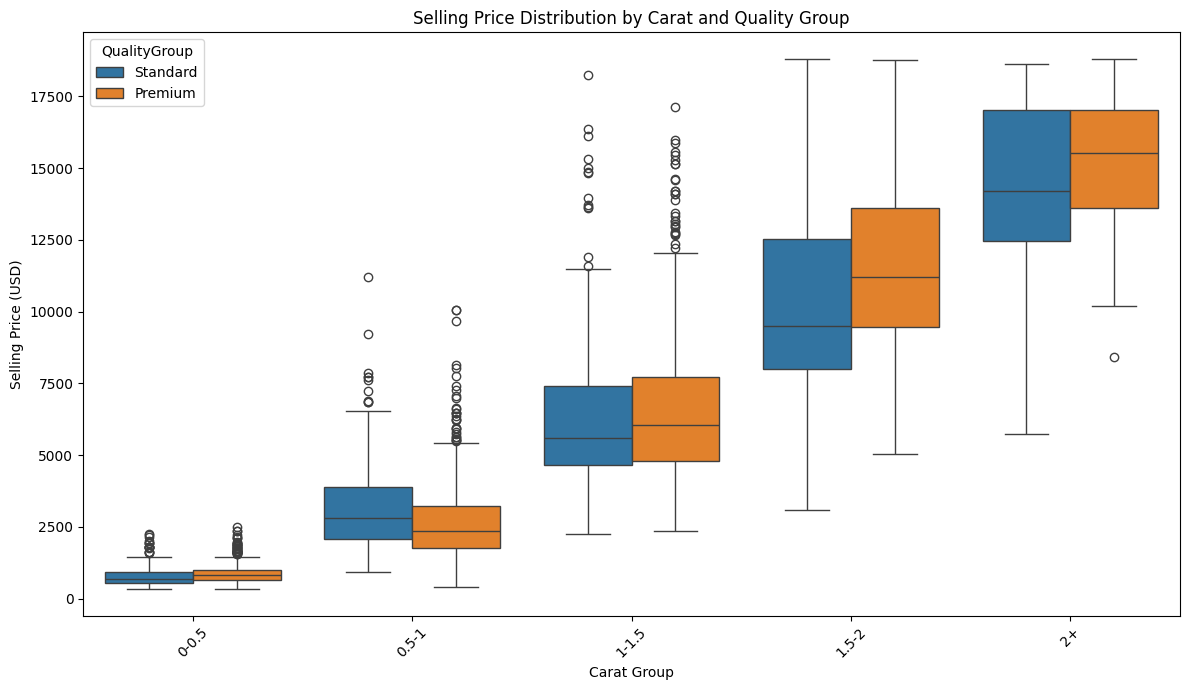

In [114]:
# ==========================================
# Price Distribution Within Carat Groups
# ==========================================

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='CaratGroup',
    y='PriceUSD',
    hue='QualityGroup'
)

plt.title(
    'Selling Price Distribution by Carat and Quality Group'
)
plt.xlabel('Carat Group')
plt.ylabel('Selling Price (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

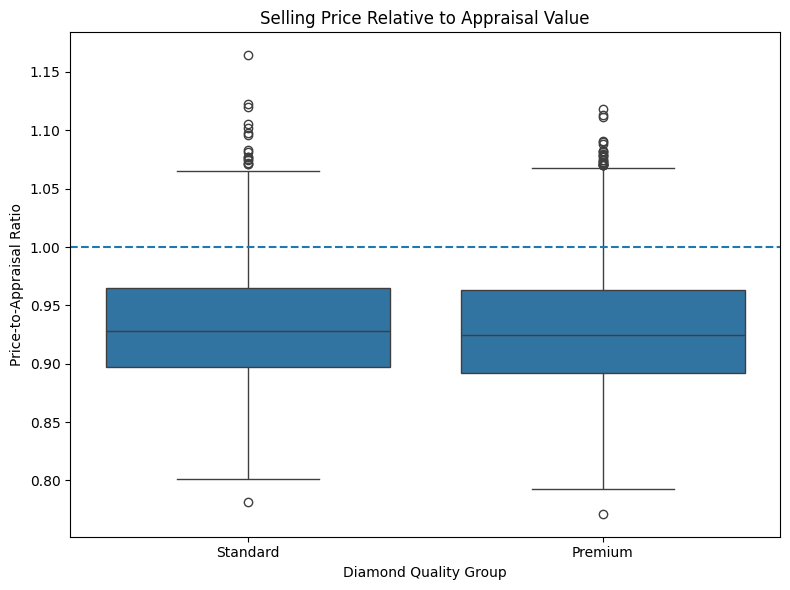

In [115]:
# ==========================================
# Price-to-Appraisal Ratio Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='PriceToAppraisalRatio',
    order=['Standard', 'Premium']
)

plt.axhline(
    1,
    linestyle='--'
)

plt.title(
    'Selling Price Relative to Appraisal Value'
)
plt.xlabel('Diamond Quality Group')
plt.ylabel('Price-to-Appraisal Ratio')

plt.tight_layout()
plt.show()

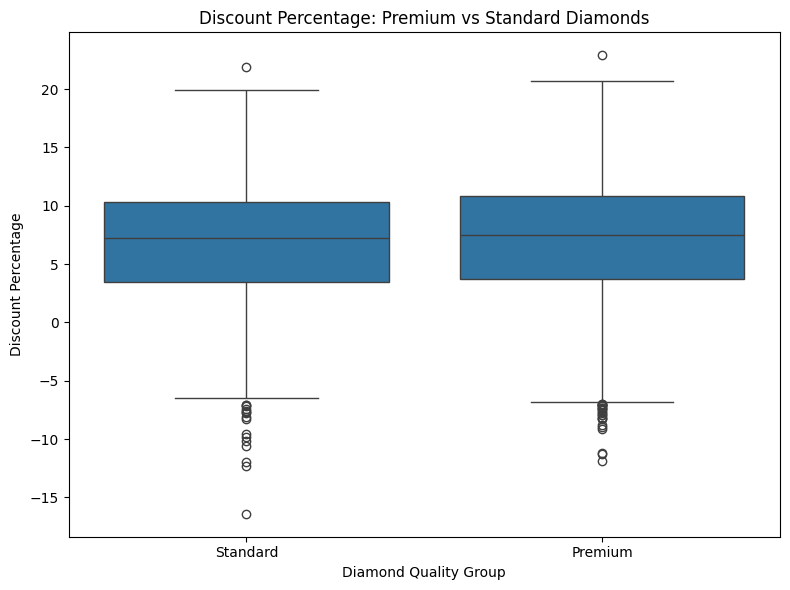

In [116]:
# ==========================================
# Discount Comparison
# ==========================================

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='QualityGroup',
    y='DiscountPercent',
    order=['Standard', 'Premium']
)

plt.title(
    'Discount Percentage: Premium vs Standard Diamonds'
)
plt.xlabel('Diamond Quality Group')
plt.ylabel('Discount Percentage')

plt.tight_layout()
plt.show()

### Analysis and Interpretation

The deep analysis was conducted to explain the unexpected finding identified in Chapter 4, where Standard diamonds exhibited a higher average selling price than Premium diamonds despite Premium diamonds representing higher cut quality.

The initial comparison suggested that Standard diamonds were more expensive overall. However, after comparing the two quality groups within similar carat-weight categories, a different pattern emerged. In the larger carat groups (1–1.5, 1.5–2, and 2+ carats), Premium diamonds consistently achieved higher median selling prices than Standard diamonds. This indicates that the higher overall average price observed for Standard diamonds was primarily driven by differences in carat weight rather than by quality group alone.

The comparison of selling price relative to appraisal value showed that both quality groups have nearly identical Price-to-Appraisal Ratios. In both cases, the median ratio remained slightly below 1.0, indicating that diamonds from both groups are generally sold slightly below their appraised value. Therefore, appraisal value does not explain the pricing differences between the two groups.

Similarly, the discount analysis revealed almost identical discount distributions for Premium and Standard diamonds. This suggests that pricing strategies and discount policies are consistent across both quality groups and are not responsible for the observed price differences.

Overall, the findings demonstrate that carat weight is the primary factor explaining the higher average selling price of Standard diamonds observed in Chapter 4. When diamonds were compared within similar carat-weight ranges, Premium diamonds generally showed higher selling prices in the larger carat groups. This pattern suggests a possible association between higher cut quality and market value, although the descriptive comparison alone does not establish an independent or causal effect.

### Business Insight

The results demonstrate that comparing average selling prices without considering carat weight may lead to misleading conclusions. Retailers and analysts should evaluate diamonds within similar weight categories to obtain a more accurate assessment of product quality and pricing performance. Since both quality groups exhibit similar appraisal ratios and discount policies, differences in market value are primarily explained by the combined effect of carat weight and diamond quality rather than by different pricing strategies.

### Conclusion

The deep analysis successfully explains the unexpected result identified in Chapter 4. Although Standard diamonds displayed a higher overall average selling price, this difference was largely caused by their higher average carat weight. When Premium and Standard diamonds were compared within the same broad carat categories, Premium diamonds generally achieved higher selling prices, particularly in the larger carat groups. These findings reinforce carat weight as the dominant pricing factor. Higher cut quality was associated with higher prices in several comparable carat groups, but this pattern should be interpreted cautiously because it does not by itself demonstrate an independent causal effect.

# 6. <strong style="color:darkblue;">Statistical Hypothesis Testing</strong>

## 1. <strong style="color:green;">Statistical Comparison Between Premium and Standard Diamonds</strong>

<strong style="color:blue;">**Research Question:**</strong>  
Is the difference in selling price between Premium and Standard diamonds within the same carat-weight range statistically significant?

<strong style="color:blue;">**Objective:**</strong>  
To statistically test whether Premium and Standard diamonds within a comparable carat-weight range have significantly different selling prices.

### Statistical Hypotheses

**Null Hypothesis (H₀):**  
There is no statistically significant difference in mean selling price between Premium and Standard diamonds within the selected carat-weight range.

**Alternative Hypothesis (H₁):**  
There is a statistically significant difference in mean selling price between Premium and Standard diamonds within the selected carat-weight range.

**Significance Level:**  
α = 0.05

In [117]:
# ==========================================
# Select Comparable Premium and Standard Groups
# ==========================================

selected_carat_group = '1-1.5'

premium_prices = df.loc[
    (df['CaratGroup'] == selected_carat_group) &
    (df['QualityGroup'] == 'Premium'),
    'PriceUSD'
].dropna()

standard_prices = df.loc[
    (df['CaratGroup'] == selected_carat_group) &
    (df['QualityGroup'] == 'Standard'),
    'PriceUSD'
].dropna()

print(f'Premium sample size: {len(premium_prices)}')
print(f'Standard sample size: {len(standard_prices)}')

Premium sample size: 675
Standard sample size: 345


In [118]:
df['CaratGroup'].value_counts().sort_index()

CaratGroup
0-0.5    1564
0.5-1    1449
1-1.5    1020
1.5-2     317
2+        148
Name: count, dtype: int64

In [119]:
# ==========================================
# Descriptive Statistics
# ==========================================

comparison_summary = pd.DataFrame({
    'Premium': premium_prices.describe(),
    'Standard': standard_prices.describe()
}).round(2)

comparison_summary

,Premium,Standard
count,675.00,345.00
mean,6652.72,6341.86
std,2472.17,2455.85
min,2360.00,2239.00
25%,4803.00,4668.00
50%,6066.00,5599.00
75%,7725.50,7392.00
max,17143.00,18231.00


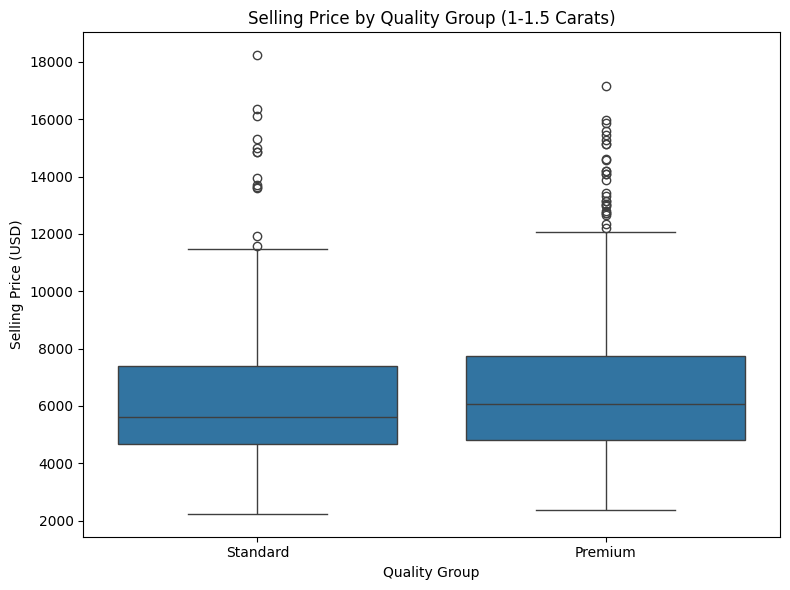

In [120]:
# ==========================================
# Price Distribution Comparison
# ==========================================

test_data = df[
    (df['CaratGroup'] == selected_carat_group) &
    (df['QualityGroup'].isin(['Premium', 'Standard']))
].copy()

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=test_data,
    x='QualityGroup',
    y='PriceUSD',
    order=['Standard', 'Premium']
)

plt.title(
    f'Selling Price by Quality Group '
    f'({selected_carat_group} Carats)'
)
plt.xlabel('Quality Group')
plt.ylabel('Selling Price (USD)')

plt.tight_layout()
plt.show()

In [121]:
# ==========================================
# Levene's Test for Equality of Variances
# ==========================================

from scipy.stats import levene

levene_statistic, levene_p_value = levene(
    premium_prices,
    standard_prices,
    center='median'
)

print(f'Levene statistic: {levene_statistic:.4f}')
print(f'Levene p-value: {levene_p_value:.6f}')

Levene statistic: 0.8456
Levene p-value: 0.358006


In [122]:
# ==========================================
# Independent Samples t-test (Welch)
# ==========================================

from scipy.stats import ttest_ind

t_statistic, p_value = ttest_ind(
    premium_prices,
    standard_prices,
    equal_var=False,
    nan_policy='omit'
)

alpha = 0.05

print(f'T-statistic: {t_statistic:.4f}')
print(f'P-value: {p_value:.6f}')
print(f'Significance level: {alpha}')

if p_value < alpha:
    print(
        'Decision: Reject H0. '
        'The difference in mean selling price is statistically significant.'
    )
else:
    print(
        'Decision: Fail to reject H0. '
        'The difference in mean selling price is not statistically significant.'
    )

T-statistic: 1.9083
P-value: 0.056758
Significance level: 0.05
Decision: Fail to reject H0. The difference in mean selling price is not statistically significant.


In [123]:
# ==========================================
# Effect Size: Cohen's d
# ==========================================

import numpy as np

mean_difference = (
    premium_prices.mean() -
    standard_prices.mean()
)

pooled_standard_deviation = np.sqrt(
    (
        premium_prices.var(ddof=1) +
        standard_prices.var(ddof=1)
    ) / 2
)

cohens_d = (
    mean_difference /
    pooled_standard_deviation
)

print(f'Mean price difference: ${mean_difference:,.2f}')
print(f"Cohen's d: {cohens_d:.3f}")

Mean price difference: $310.87
Cohen's d: 0.126


### Analysis and Interpretation

A statistical hypothesis test was conducted to determine whether the difference in selling price between Premium and Standard diamonds within the 1–1.5 carat group is statistically significant.

Since the two groups represent independent observations and both samples are large, an independent-samples test was appropriate. Welch’s t-test was selected because it provides a robust comparison of group means and does not require the assumption of equal population variances. The large sample sizes also make the test relatively robust to moderate deviations from normality. Before performing the test, Levene's test was used to evaluate the equality of variances. The result was not statistically significant (p = 0.358), indicating that there was no evidence of unequal variances between the two groups.

A Welch's Independent Samples t-test was then performed to compare the mean selling prices of Premium and Standard diamonds. The test produced a t-statistic of approximately 1.91 with a p-value of 0.0568. Because the p-value is greater than the significance level of 0.05, the null hypothesis cannot be rejected.

Although Premium diamonds showed slightly higher selling prices within this carat range, the observed difference is not statistically significant. In addition, Cohen's d was approximately 0.13, indicating a very small practical effect size. Therefore, the observed price difference is small and may reasonably be attributed to normal sampling variation rather than a meaningful difference between the two quality groups.

These findings are consistent with the deep analysis performed in Chapter 5. Although Premium diamonds tended to achieve higher median selling prices after restricting the comparison to the 1–1.5 carat range, the statistical test indicates that the observed difference was not strong enough to conclude that the two populations differ significantly.

### Business Insight

The results suggest that within the 1–1.5 carat category, Premium diamonds do not command a statistically significant price advantage over Standard diamonds. From a business perspective, this implies that factors other than cut quality—such as certification, brand reputation, customer preferences, or additional diamond characteristics—may also contribute to the final selling price. Pricing decisions should therefore consider multiple attributes rather than relying solely on the Premium versus Standard classification.

### Conclusion

The statistical analysis failed to find sufficient evidence of a significant difference in selling price between Premium and Standard diamonds within the selected carat range. Consequently, the null hypothesis was not rejected. While Premium diamonds exhibited slightly higher average prices, the difference was neither statistically significant nor practically large. These findings reinforce the importance of comparing diamond quality groups within similar carat ranges. Within the selected 1–1.5 carat category, the remaining price difference was relatively small and not statistically significant.

# 7. <strong style="color:darkblue;">Machine Learning Model</strong>

## 1. <strong style="color:green;">Diamond Price Prediction Using Linear Regression</strong>

<strong style="color:blue;">**Research Question:**</strong>  
Can diamond prices be predicted based on their physical and quality characteristics?

<strong style="color:blue;">**Objective:**</strong>  
To develop a Linear Regression model that predicts diamond selling prices using relevant diamond features.

In [124]:
# ==========================================
# Feature Selection
# ==========================================

features = [
    'Carat',
    'Cut',
    'Color',
    'Clarity',
    'DepthPct',
    'TablePct',
    'LengthMm',
    'WidthMm',
    'HeightMm',
    'Certification'
]

target = 'PriceUSD'

X = df[features]

y = df[target]

print(X.shape)
print(y.shape)

(4498, 10)
(4498,)


In [125]:
# ==========================================
# One-Hot Encoding
# ==========================================

X = pd.get_dummies(
    X,
    drop_first=True
)

print(X.shape)

X.head()

(4498, 27)


,Carat,DepthPct,TablePct,LengthMm,WidthMm,HeightMm,Cut_Good,Cut_Ideal,Cut_Premium,Cut_Very Good,...,Clarity_SI1,Clarity_SI2,Clarity_VS1,Clarity_VS2,Clarity_VVS1,Clarity_VVS2,Certification_HRD,Certification_IGI,Certification_Uncertified,Certification_Unknown
0,0.97,57.2,60.0,6.59,6.36,3.72,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.13,63.2,56.0,6.66,6.69,4.22,False,False,False,True,...,True,False,False,False,False,False,False,True,False,False
2,0.41,59.8,57.0,4.85,4.81,2.89,False,True,False,False,...,False,False,False,True,False,False,False,True,False,False
3,0.74,62.2,54.0,5.79,5.85,3.62,False,True,False,False,...,True,False,False,False,False,False,False,False,False,False
4,0.71,59.1,61.0,5.84,5.81,3.44,False,False,True,False,...,False,False,True,False,False,False,False,True,False,False


In [126]:
# ==========================================
# Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3598
Testing samples: 900


In [127]:
# ==========================================
# Linear Regression Model Training
# ==========================================

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

y_pred = linear_model.predict(X_test)

print('Linear Regression model trained successfully.')
print('Number of predictions:', len(y_pred))

Linear Regression model trained successfully.
Number of predictions: 900


### Analysis and Interpretation

An initial Linear Regression model was developed to predict diamond selling prices using physical measurements and quality characteristics, including carat weight, cut, color, clarity, dimensions, depth percentage, table percentage, and certification.

The dataset was divided into training and testing sets using an 80/20 split. Categorical variables were transformed using One-Hot Encoding, allowing them to be included in the regression model together with the numerical features.

This initial model served as a baseline for evaluating whether diamond prices could be predicted from the available characteristics. Because the selling-price distribution was strongly right-skewed, additional evaluation was required to determine whether standard Linear Regression performed consistently across both lower-priced and higher-priced diamonds.

The baseline model was therefore evaluated using absolute and relative error metrics, cross-validation, residual analysis, and price-group comparisons. These diagnostics provided the foundation for developing and comparing an improved log-transformed Linear Regression model in the following section.

### Business Insight

A data-driven pricing model can support retailers by providing an initial estimate of a diamond's selling price based on its physical and quality characteristics. Such estimates can assist with inventory valuation, product listing, pricing consistency, and the identification of unusually priced diamonds.

However, model performance should be evaluated across different price ranges before the predictions are used for business decisions. A model may explain the overall variation in prices while still producing large relative errors for specific product segments, particularly lower-priced diamonds.

Therefore, the initial Linear Regression model was treated as a baseline rather than immediately adopted as the final pricing model.

### Conclusion

The baseline Linear Regression model established that diamond selling prices can be predicted using physical measurements and quality characteristics. However, training the model alone was not sufficient to determine whether its predictions were accurate, stable, and appropriate across the full price range.

The next stage evaluates the baseline model using multiple performance metrics and diagnostic methods, compares it with a log-transformed alternative, and selects the model that provides the strongest and most reliable predictive performance.

## 2. <strong style="color:green;">Model Evaluation</strong>

<strong style="color:blue;">**Research Question:**</strong>  
How accurately can the model predict diamond prices?

<strong style="color:blue;">**Objective:**</strong>  
To evaluate the performance of the regression model using appropriate evaluation metrics such as R² and MAE.

In [128]:
# ==========================================
# Model Evaluation Metrics
# ==========================================

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

r2 = r2_score(
    y_test,
    y_pred
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

mape = mean_absolute_percentage_error(
    y_test,
    y_pred
) * 100

print(f'R² Score: {r2:.4f}')
print(f'Mean Absolute Error: ${mae:,.2f}')
print(f'Root Mean Squared Error: ${rmse:,.2f}')
print(f'Mean Absolute Percentage Error: {mape:.2f}%')

R² Score: 0.9253
Mean Absolute Error: $743.78
Root Mean Squared Error: $1,106.92
Mean Absolute Percentage Error: 41.98%


In [129]:
# ==========================================
# Relative Error Analysis
# ==========================================

percentage_errors = (
    np.abs(y_test - y_pred) /
    y_test
) * 100

median_absolute_percentage_error = np.median(
    percentage_errors
)

weighted_absolute_percentage_error = (
    np.abs(y_test - y_pred).sum() /
    y_test.sum()
) * 100

negative_predictions = (
    y_pred < 0
).sum()

print(
    f'Median Absolute Percentage Error: '
    f'{median_absolute_percentage_error:.2f}%'
)

print(
    f'Weighted Absolute Percentage Error: '
    f'{weighted_absolute_percentage_error:.2f}%'
)

print(
    f'Negative Predictions: '
    f'{negative_predictions}'
)

Median Absolute Percentage Error: 20.01%
Weighted Absolute Percentage Error: 18.92%
Negative Predictions: 76


In [130]:
# ==========================================
# Model Performance by Price Group
# ==========================================

evaluation_data = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': y_pred
})

evaluation_data['Absolute_Error'] = np.abs(
    evaluation_data['Actual_Price'] -
    evaluation_data['Predicted_Price']
)

evaluation_data['Absolute_Percentage_Error'] = (
    evaluation_data['Absolute_Error'] /
    evaluation_data['Actual_Price']
) * 100

evaluation_data['Price_Group'] = pd.cut(
    evaluation_data['Actual_Price'],
    bins=[0, 2000, 5000, 10000, np.inf],
    labels=[
        'Up to $2,000',
        '$2,001–$5,000',
        '$5,001–$10,000',
        'Above $10,000'
    ]
)

price_group_evaluation = (
    evaluation_data
    .groupby(
        'Price_Group',
        observed=True
    )
    .agg(
        Diamonds=('Actual_Price', 'size'),
        Average_Actual_Price=('Actual_Price', 'mean'),
        MAE=('Absolute_Error', 'mean'),
        MAPE=('Absolute_Percentage_Error', 'mean'),
        Median_APE=('Absolute_Percentage_Error', 'median')
    )
    .round(2)
)

price_group_evaluation

,Diamonds,Average_Actual_Price,MAE,MAPE,Median_APE
Price_Group,,,,,
"Up to $2,000",428,985.95,563.35,72.69,47.56
"$2,001–$5,000",230,3534.23,538.45,15.93,13.16
"$5,001–$10,000",154,7153.19,797.05,10.98,8.38
"Above $10,000",88,13648.39,2064.80,14.93,13.28


In [131]:
# ==========================================
# Linear Regression Cross-Validation
# ==========================================

cv_r2_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print(
    'Cross-Validation R² Scores:',
    np.round(cv_r2_scores, 4)
)

print(
    f'Mean Cross-Validation R²: '
    f'{cv_r2_scores.mean():.4f}'
)

print(
    f'Cross-Validation Standard Deviation: '
    f'{cv_r2_scores.std():.4f}'
)

Cross-Validation R² Scores: [0.9128 0.9189 0.9204 0.9103 0.9289]
Mean Cross-Validation R²: 0.9183
Cross-Validation Standard Deviation: 0.0065


In [132]:
# ==========================================
# Log-Transformed Linear Regression Model
# ==========================================

log_linear_model = LinearRegression()

log_linear_model.fit(
    X_train,
    np.log1p(y_train)
)

log_y_pred = np.expm1(
    log_linear_model.predict(X_test)
)

log_r2 = r2_score(
    y_test,
    log_y_pred
)

log_mae = mean_absolute_error(
    y_test,
    log_y_pred
)

log_rmse = mean_squared_error(
    y_test,
    log_y_pred
) ** 0.5

log_mape = mean_absolute_percentage_error(
    y_test,
    log_y_pred
) * 100

log_median_ape = np.median(
    np.abs(y_test - log_y_pred) /
    y_test
) * 100

log_wape = (
    np.abs(y_test - log_y_pred).sum() /
    y_test.sum()
) * 100

log_negative_predictions = (
    log_y_pred < 0
).sum()

print(f'Log Model R² Score: {log_r2:.4f}')
print(f'Log Model MAE: ${log_mae:,.2f}')
print(f'Log Model RMSE: ${log_rmse:,.2f}')
print(f'Log Model MAPE: {log_mape:.2f}%')
print(f'Log Model Median APE: {log_median_ape:.2f}%')
print(f'Log Model WAPE: {log_wape:.2f}%')
print(f'Log Model Negative Predictions: {log_negative_predictions}')

Log Model R² Score: 0.9605
Log Model MAE: $434.22
Log Model RMSE: $804.81
Log Model MAPE: 10.70%
Log Model Median APE: 9.32%
Log Model WAPE: 11.05%
Log Model Negative Predictions: 0


In [133]:
# ==========================================
# Original vs Log-Transformed Model
# ==========================================

model_comparison = pd.DataFrame({
    'Model': [
        'Original Linear Regression',
        'Log-Transformed Linear Regression'
    ],
    'R²': [
        r2,
        log_r2
    ],
    'MAE': [
        mae,
        log_mae
    ],
    'RMSE': [
        rmse,
        log_rmse
    ],
    'MAPE': [
        mape,
        log_mape
    ],
    'Median_APE': [
        median_absolute_percentage_error,
        log_median_ape
    ],
    'WAPE': [
        weighted_absolute_percentage_error,
        log_wape
    ],
    'Negative_Predictions': [
        negative_predictions,
        log_negative_predictions
    ]
}).round(2)

model_comparison

,Model,R²,MAE,RMSE,MAPE,Median_APE,WAPE,Negative_Predictions
0,Original Linear Regression,0.93,743.78,1106.92,41.98,20.01,18.92,76
1,Log-Transformed Linear Regression,0.96,434.22,804.81,10.70,9.32,11.05,0


In [134]:
# ==========================================
# Log-Transformed Model Cross-Validation
# ==========================================

log_cv_model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

log_cv_r2_scores = cross_val_score(
    log_cv_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print(
    'Log Model Cross-Validation R² Scores:',
    np.round(log_cv_r2_scores, 4)
)

print(
    f'Log Model Mean Cross-Validation R²: '
    f'{log_cv_r2_scores.mean():.4f}'
)

print(
    f'Log Model Cross-Validation Standard Deviation: '
    f'{log_cv_r2_scores.std():.4f}'
)

Log Model Cross-Validation R² Scores: [0.9442 0.9497 0.955  0.9488 0.9546]
Log Model Mean Cross-Validation R²: 0.9505
Log Model Cross-Validation Standard Deviation: 0.0040


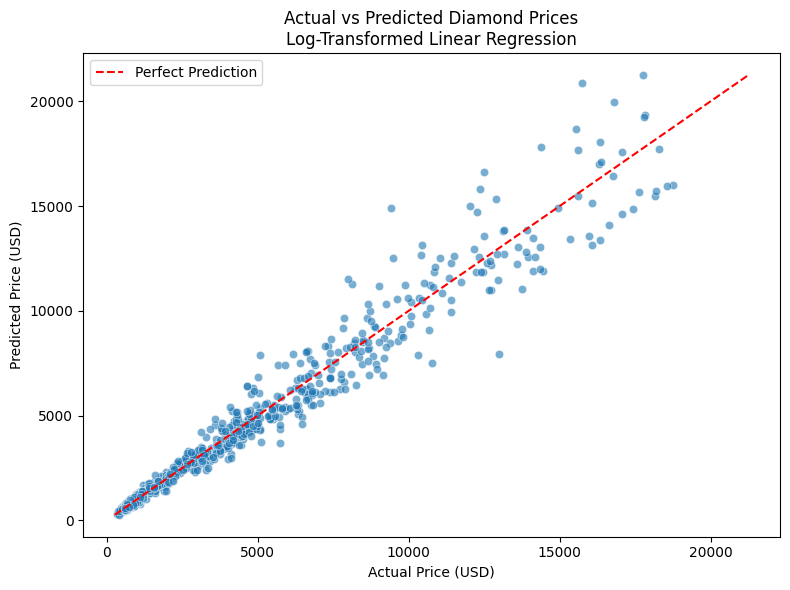

In [135]:
# ==========================================
# Actual vs Predicted Prices
# Final Log-Transformed Model
# ==========================================

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=log_y_pred,
    alpha=0.6
)

minimum_price = min(
    y_test.min(),
    log_y_pred.min()
)

maximum_price = max(
    y_test.max(),
    log_y_pred.max()
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.title(
    'Actual vs Predicted Diamond Prices\n'
    'Log-Transformed Linear Regression'
)

plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')

plt.legend()
plt.tight_layout()
plt.show()

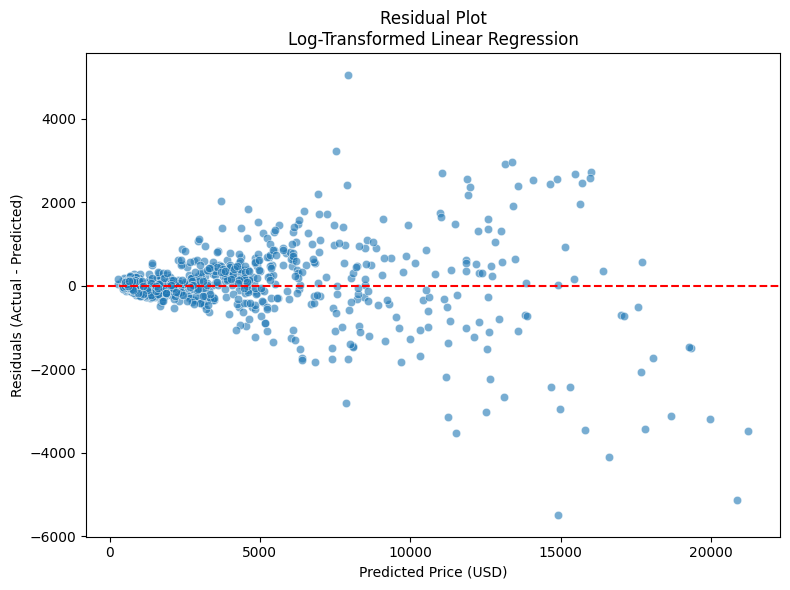

In [136]:
# ==========================================
# Residual Analysis
# Final Log-Transformed Model
# ==========================================

log_residuals = (
    y_test - log_y_pred
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=log_y_pred,
    y=log_residuals,
    alpha=0.6
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.title(
    'Residual Plot\n'
    'Log-Transformed Linear Regression'
)

plt.xlabel('Predicted Price (USD)')
plt.ylabel('Residuals (Actual - Predicted)')

plt.tight_layout()
plt.show()

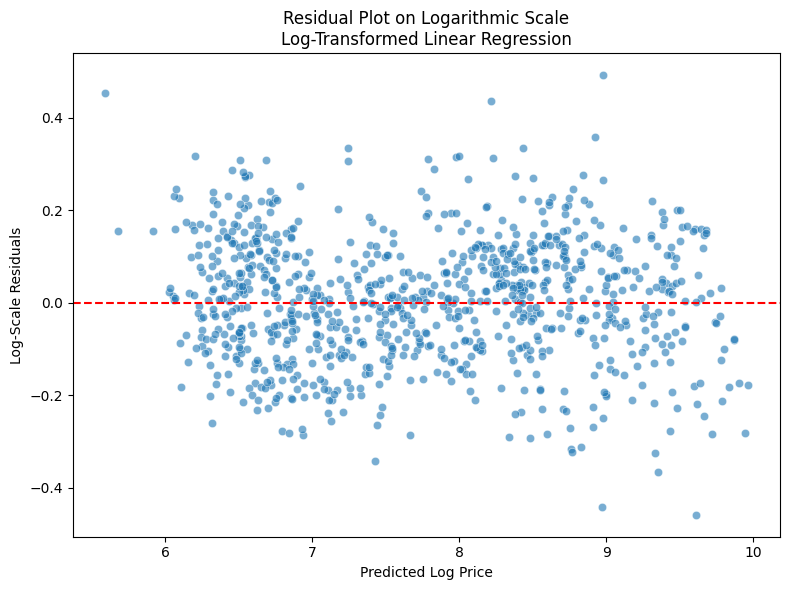

In [137]:
# ==========================================
# Log-Scale Residual Analysis
# ==========================================

log_actual_values = np.log1p(
    y_test
)

log_predicted_values = log_linear_model.predict(
    X_test
)

log_scale_residuals = (
    log_actual_values -
    log_predicted_values
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=log_predicted_values,
    y=log_scale_residuals,
    alpha=0.6
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.title(
    'Residual Plot on Logarithmic Scale\n'
    'Log-Transformed Linear Regression'
)

plt.xlabel('Predicted Log Price')
plt.ylabel('Log-Scale Residuals')

plt.tight_layout()
plt.show()

In [138]:
# ==========================================
# Final Log-Transformed Model
# ==========================================

final_log_model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

final_log_model.fit(
    X_train,
    y_train
)

print(
    'Final log-transformed model trained successfully.'
)

Final log-transformed model trained successfully.


In [139]:
# ==========================================
# Permutation Feature Importance
# ==========================================

permutation_results = permutation_importance(
    final_log_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

permutation_importance_summary = (
    pd.DataFrame({
        'Feature': X.columns,
        'Importance_Mean': permutation_results.importances_mean,
        'Importance_Std': permutation_results.importances_std
    })
    .sort_values(
        'Importance_Mean',
        ascending=False
    )
    .reset_index(drop=True)
)

permutation_importance_summary.head(15).round(4)

,Feature,Importance_Mean,Importance_Std
0,Carat,11.0663,1.2108
1,LengthMm,3.2080,0.1004
2,Clarity_VS2,0.5060,0.0833
3,Clarity_VVS2,0.5055,0.0927
4,Clarity_VVS1,0.4972,0.0986
5,Clarity_VS1,0.4963,0.0788
6,HeightMm,0.4448,0.0076
7,Clarity_SI1,0.3190,0.0329
8,Clarity_IF,0.1999,0.1027
9,Clarity_SI2,0.1254,0.0191


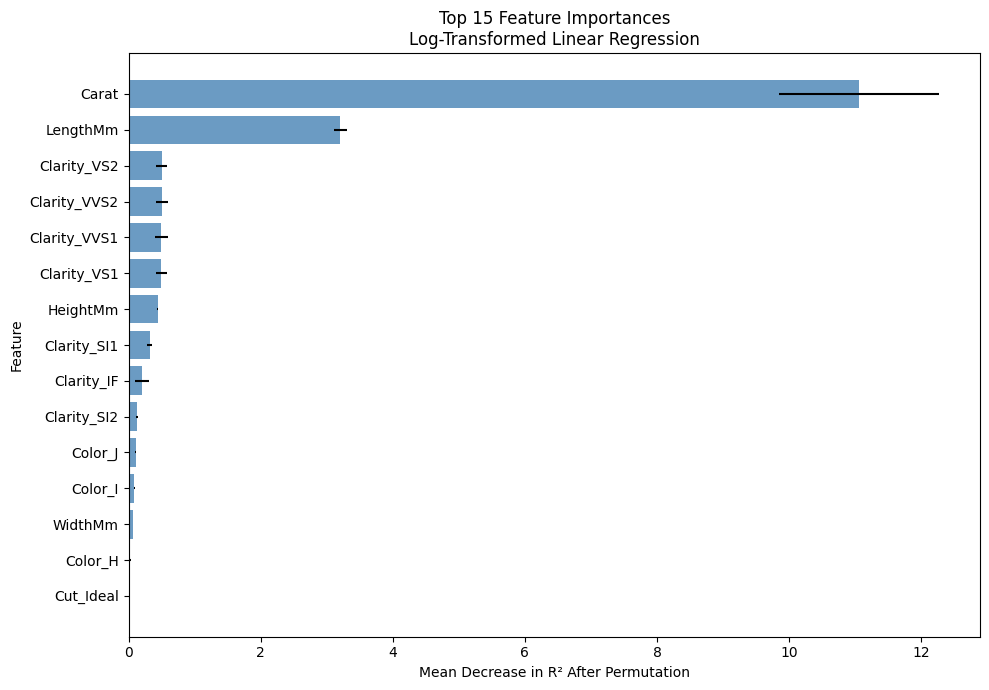

In [140]:
# ==========================================
# Top 15 Permutation Feature Importances
# ==========================================

top_permutation_features = (
    permutation_importance_summary
    .head(15)
    .sort_values(
        'Importance_Mean',
        ascending=True
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation_features['Feature'],
    top_permutation_features['Importance_Mean'],
    xerr=top_permutation_features['Importance_Std'],
    color='steelblue',
    alpha=0.8
)

plt.title(
    'Top 15 Feature Importances\n'
    'Log-Transformed Linear Regression'
)

plt.xlabel('Mean Decrease in R² After Permutation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

Permutation importance was used to evaluate the contribution of each feature to the predictive performance of the final log-transformed model. This method measures how much the model's R² score decreases when the values of a feature are randomly shuffled.

Carat weight was the most influential predictor by a substantial margin, followed by diamond length. Several clarity categories also contributed meaningfully to price prediction, while color and cut characteristics generally showed smaller individual contributions.

These results reinforce the earlier exploratory findings that diamond size is the primary driver of selling price, while quality characteristics provide additional predictive information. However, permutation importance should not be interpreted as a causal effect. Carat weight and physical dimensions are strongly related, and correlated predictors may influence how importance is distributed among individual features.

### Analysis and Interpretation

The baseline Linear Regression model achieved an R² score of **0.9253** on the test set, indicating that it explained approximately **92.5% of the variation** in diamond selling prices. Its Mean Absolute Error (MAE) was approximately **$744**, while the Root Mean Squared Error (RMSE) was approximately **$1,107**.

Five-fold cross-validation produced a mean R² score of **0.9183** with a standard deviation of **0.0065**. The narrow range of cross-validation scores indicated that the baseline model was stable across different data partitions and that its test-set performance was not caused by a favorable train-test split.

However, relative-error analysis revealed an important limitation. The baseline model produced a Mean Absolute Percentage Error (MAPE) of **41.98%**, a Median Absolute Percentage Error of **20.01%**, and a Weighted Absolute Percentage Error of **18.92%**. It also generated **76 negative price predictions**, which are not meaningful in a real pricing context.

The price-group analysis showed that this weakness was concentrated primarily among diamonds priced below **$2,000**, where the model achieved a MAPE of **72.69%** and a median percentage error of **47.56%**. In comparison, the model performed considerably better for diamonds priced between **$5,001 and $10,000**, achieving a MAPE of **10.98%**. These findings demonstrated that a high overall R² score did not guarantee consistent accuracy across all price segments.

Because diamond prices were strongly right-skewed, an improved Linear Regression model was trained using a logarithmic transformation of the target variable. Predictions were then transformed back into their original dollar scale for evaluation.

The log-transformed model outperformed the baseline model across every evaluation metric. It achieved an R² score of **0.9605**, an MAE of **$434.22**, an RMSE of **$804.81**, a MAPE of **10.70%**, a Median Absolute Percentage Error of **9.32%**, and a Weighted Absolute Percentage Error of **11.05%**. In addition, it produced **no negative predictions**.

Five-fold cross-validation confirmed that this improvement was stable. The log-transformed model achieved cross-validation R² scores ranging from **0.9442 to 0.9550**, with a mean of **0.9505** and a standard deviation of only **0.0040**. The close agreement between the test-set R² and the cross-validation average indicates strong and consistent generalization performance.

The Actual vs. Predicted plot showed that most predictions were positioned close to the perfect-prediction line, particularly for lower-priced and mid-priced diamonds. Prediction errors became larger in dollar terms among the highest-priced diamonds. The residual plot on the original dollar scale displayed increasing variance at higher predicted prices, while the log-scale residual plot showed a more balanced distribution around zero. This indicates that the logarithmic transformation improved the model's treatment of the right-skewed price distribution, although some uncertainty remains for high-value diamonds.

Permutation importance identified **Carat** as the most influential predictive feature by a substantial margin, followed by **LengthMm**. Several clarity categories also contributed meaningfully, while color and cut characteristics generally had smaller individual contributions. Because carat weight and physical dimensions are correlated, these importance values should be interpreted as predictive contributions rather than isolated causal effects.

Overall, the log-transformed Linear Regression model provided more accurate, stable, and practically meaningful price predictions than the original baseline model.

### Business Insight

The final log-transformed model can support diamond pricing, inventory valuation, product listing, and the identification of unusually priced products. Compared with the baseline model, it reduced the Mean Absolute Error from approximately **$744 to $434** and the Mean Absolute Percentage Error from **41.98% to 10.70%**, while eliminating all negative price predictions.

The model's mean cross-validation R² of **0.9505**, together with the low standard deviation of **0.0040**, indicates that its performance remains consistent across different subsets of the data. This stability increases confidence in its use as a pricing-support tool for newly listed diamonds.

The feature-importance analysis confirms that carat weight and physical size are the primary drivers of predicted price, while clarity, color, cut, and certification provide additional information. Businesses should therefore avoid pricing diamonds using a single quality characteristic and instead consider the combined contribution of physical and quality features.

Despite its strong overall performance, prediction errors remain larger in dollar terms for some high-value diamonds. The model should therefore support, rather than replace, professional appraisal and market judgment, particularly when evaluating rare or exceptionally expensive products.

### Conclusion

The model evaluation demonstrated that the original Linear Regression model explained a large proportion of price variation but had important practical limitations. Although it achieved a test-set R² of **0.9253**, its MAPE was **41.98%**, and it generated **76 negative price predictions**, with particularly weak relative performance among diamonds priced below $2,000.

Applying a logarithmic transformation to the target variable substantially improved the results. The final model achieved an R² score of **0.9605**, an MAE of **$434.22**, an RMSE of **$804.81**, a MAPE of **10.70%**, and no negative predictions.

Five-fold cross-validation produced a mean R² of **0.9505** with a standard deviation of only **0.0040**, confirming that the improved performance was stable and not dependent on a single train-test split. Residual analysis further showed that the logarithmic transformation produced a more balanced error structure, although larger dollar errors remained among some high-value diamonds.

Overall, the log-transformed Linear Regression model was selected as the final pricing model because it provided the strongest combination of explanatory power, prediction accuracy, stability, and practical validity. It is suitable as a decision-support tool for diamond pricing while still requiring professional judgment for exceptional market cases.

## 3. <strong style="color:green;">Diamond Segmentation Using K-Means Clustering</strong>

<strong style="color:blue;">**Research Question:**</strong>  
Can diamonds be grouped into meaningful clusters based on their physical and pricing characteristics?

<strong style="color:blue;">**Objective:**</strong>  
To identify natural groups of diamonds using the K-Means clustering algorithm and analyze the characteristics of each cluster.

In [141]:
# ==========================================
# Feature Selection for K-Means
# ==========================================

kmeans_features = [
    'Carat',
    'PriceUSD',
    'DepthPct',
    'TablePct',
    'LengthMm',
    'WidthMm',
    'HeightMm'
]

X_cluster = df[kmeans_features]

X_cluster.head()

,Carat,PriceUSD,DepthPct,TablePct,LengthMm,WidthMm,HeightMm
0,0.97,1547,57.2,60.0,6.59,6.36,3.72
1,1.13,5584,63.2,56.0,6.66,6.69,4.22
2,0.41,1061,59.8,57.0,4.85,4.81,2.89
3,0.74,2583,62.2,54.0,5.79,5.85,3.62
4,0.71,2839,59.1,61.0,5.84,5.81,3.44


In [142]:
# ==========================================
# Feature Scaling
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

print(X_scaled.shape)

(4498, 7)


In [143]:
# ==========================================
# Elbow Method
# ==========================================

inertia = []

k_values = range(1, 11)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(
        model.inertia_
    )

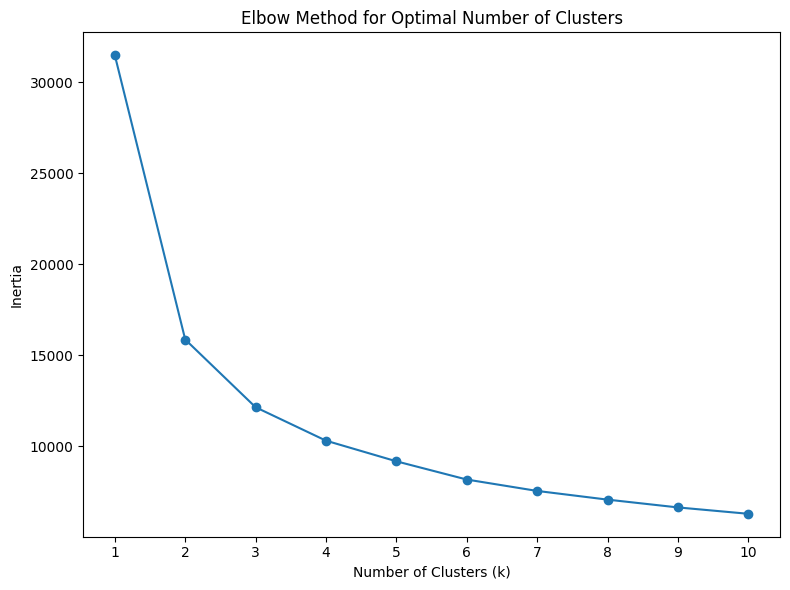

In [144]:
# ==========================================
# Elbow Curve
# ==========================================

plt.figure(figsize=(8,6))

plt.plot(
    k_values,
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')

plt.xlabel('Number of Clusters (k)')

plt.ylabel('Inertia')

plt.xticks(k_values)

plt.tight_layout()

plt.show()

In [145]:
# ==========================================
# Train K-Means Model
# ==========================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df['Cluster'].value_counts().sort_index()

Cluster
0    2079
1     619
2    1800
Name: count, dtype: int64

In [146]:
# ==========================================
# K-Means Cluster Quality Evaluation
# ==========================================

silhouette_avg = silhouette_score(
    X_scaled,
    df['Cluster']
)

davies_bouldin = davies_bouldin_score(
    X_scaled,
    df['Cluster']
)

print(f'Silhouette Score: {silhouette_avg:.3f}')
print(f'Davies-Bouldin Score: {davies_bouldin:.3f}')

Silhouette Score: 0.381
Davies-Bouldin Score: 1.042


In [147]:
# ==========================================
# Assign Meaningful Cluster Names
# ==========================================

cluster_names = {
    0: 'Entry-Level Diamonds',
    1: 'Premium Diamonds',
    2: 'Mid-Value Diamonds'
}

df['ClusterName'] = df['Cluster'].map(cluster_names)

(
    df[['Cluster', 'ClusterName']]
    .drop_duplicates()
    .sort_values('Cluster')
    .reset_index(drop=True)
)

,Cluster,ClusterName
0,0,Entry-Level Diamonds
1,1,Premium Diamonds
2,2,Mid-Value Diamonds


In [148]:
# ==========================================
# Cluster Summary
# ==========================================

cluster_summary = (
    df.groupby(
        'ClusterName',
        observed=True
    )
    .agg(
        Diamonds=('DiamondID', 'size'),
        Average_Carat=('Carat', 'mean'),
        Average_Price=('PriceUSD', 'mean'),
        Average_Depth=('DepthPct', 'mean'),
        Average_Table=('TablePct', 'mean'),
        Average_Length=('LengthMm', 'mean'),
        Average_Width=('WidthMm', 'mean'),
        Average_Height=('HeightMm', 'mean')
    )
)

cluster_summary.insert(
    1,
    'Percentage',
    (
        cluster_summary['Diamonds']
        / cluster_summary['Diamonds'].sum()
        * 100
    )
)

cluster_summary = cluster_summary.round(2)

cluster_summary

,Diamonds,Percentage,Average_Carat,Average_Price,Average_Depth,Average_Table,Average_Length,Average_Width,Average_Height
ClusterName,,,,,,,,,
Entry-Level Diamonds,2079,46.22,0.40,1056.45,61.65,56.93,4.71,4.72,2.91
Mid-Value Diamonds,1800,40.02,0.95,4582.40,61.77,57.73,6.29,6.28,3.88
Premium Diamonds,619,13.76,1.69,11895.39,61.87,58.01,7.60,7.59,4.69


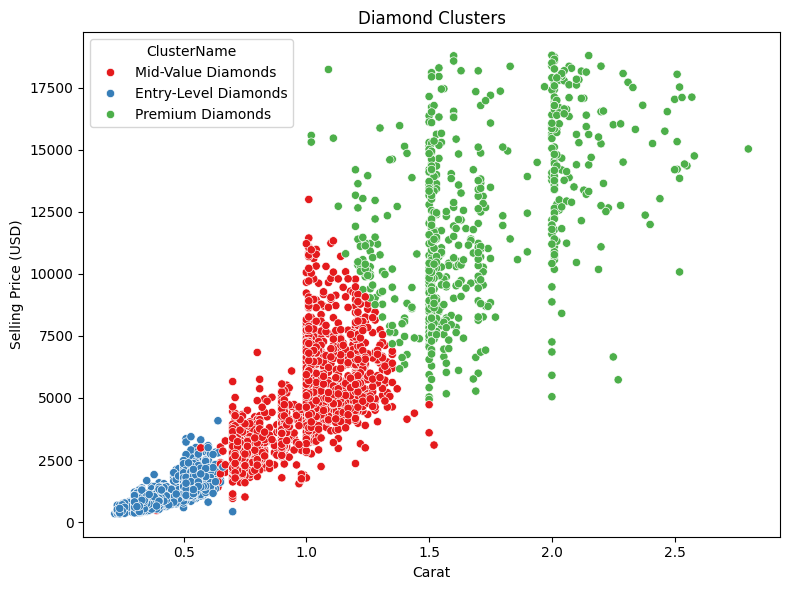

In [149]:
# ==========================================
# Cluster Visualization
# ==========================================

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x='Carat',
    y='PriceUSD',
    hue='ClusterName',
    palette='Set1'
)

plt.title('Diamond Clusters')

plt.xlabel('Carat')

plt.ylabel('Selling Price (USD)')

plt.tight_layout()

plt.show()

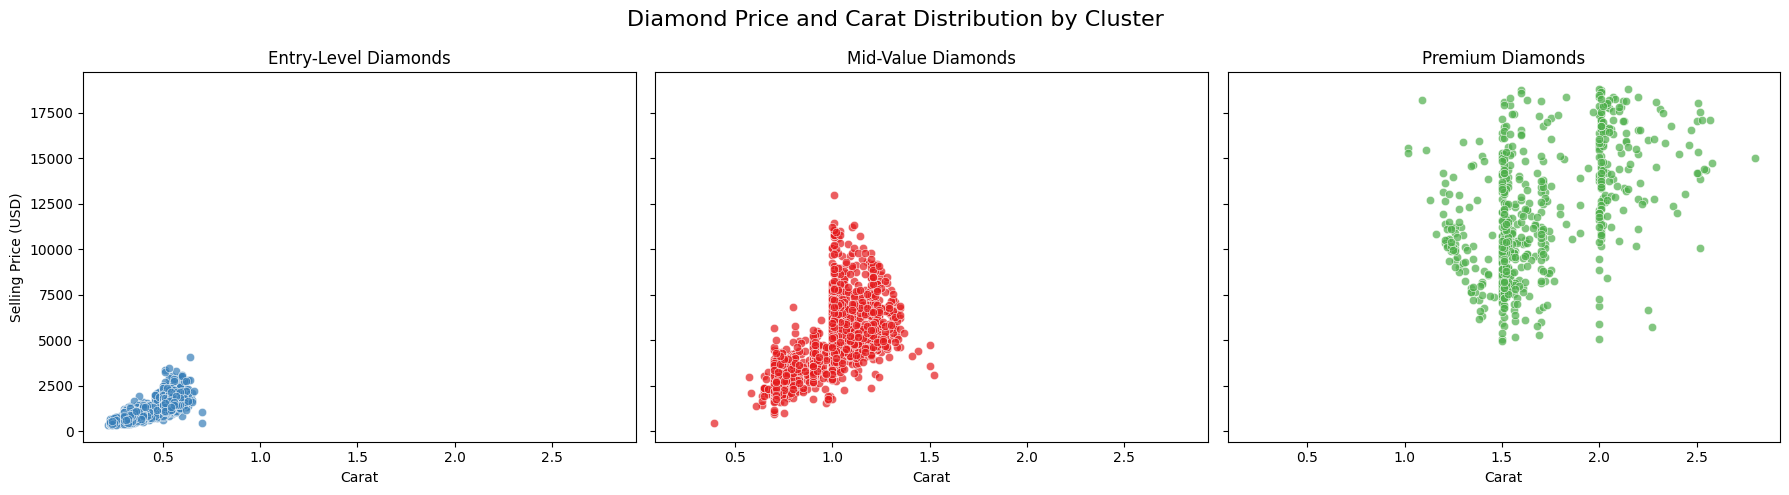

In [150]:
# ==========================================
# Separate Visualization for Each Cluster
# ==========================================

cluster_order = [
    'Entry-Level Diamonds',
    'Mid-Value Diamonds',
    'Premium Diamonds'
]

cluster_colors = {
    'Entry-Level Diamonds': '#377eb8',  # כחול של Set1
    'Mid-Value Diamonds': '#e41a1c',    # אדום של Set1
    'Premium Diamonds': '#4daf4a'       # ירוק של Set1
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, cluster_name in zip(axes, cluster_order):

    cluster_data = df[
        df['ClusterName'] == cluster_name
    ]

    sns.scatterplot(
        data=cluster_data,
        x='Carat',
        y='PriceUSD',
        color=cluster_colors[cluster_name],
        alpha=0.7,
        ax=ax
    )

    ax.set_title(cluster_name)
    ax.set_xlabel('Carat')
    ax.set_ylabel('Selling Price (USD)')

plt.suptitle(
    'Diamond Price and Carat Distribution by Cluster',
    fontsize=16
)

plt.tight_layout()
plt.show()

### Analysis and Interpretation

The K-Means clustering algorithm was applied to identify natural groups of diamonds based on their physical measurements and selling prices. Before training the model, all numerical variables were standardized using `StandardScaler` to ensure that each feature contributed equally to the clustering process.

The Elbow Method indicated that **three clusters** provided an appropriate balance between model simplicity and within-cluster variation. After applying K-Means with three clusters, the algorithm separated the diamonds into three interpretable market segments.

The quality of the clustering solution was evaluated using the **Silhouette Score** and the **Davies–Bouldin Index**. The model achieved a Silhouette Score of **0.381**, indicating a moderate clustering structure with some overlap between neighboring clusters. The Davies–Bouldin Score was **1.042**, suggesting that the clusters are reasonably distinct, although their separation is not especially strong. Overall, these metrics support the use of three clusters as a useful and interpretable segmentation while indicating that some diamonds share similar characteristics across cluster boundaries.

The first cluster represents **Entry-Level Diamonds**, characterized by relatively small carat weights and low selling prices. The second cluster contains **Mid-Value Diamonds**, which exhibit moderate carat weights and intermediate market prices. The third cluster represents **Premium Diamonds**, consisting of larger diamonds with substantially higher selling prices and larger physical dimensions.

The scatter plots show recognizable regions in the price–carat space, although some overlap exists between neighboring clusters. Together with the evaluation metrics, the results indicate that K-Means identified a moderately structured and interpretable market segmentation without using predefined labels.

### Business Insight

The identified clusters provide a practical and interpretable segmentation of the diamond market. Retailers can use these segments to develop targeted pricing strategies, improve inventory organization, personalize marketing campaigns, support product recommendation systems, and better understand customer purchasing patterns. The segmentation can also assist with inventory planning and product positioning by distinguishing between Entry-Level, Mid-Value, and Premium diamond groups.

However, the Silhouette Score of **0.381** and the Davies–Bouldin Score of **1.042** indicate that the separation between the clusters is moderate rather than perfect. Therefore, the clusters should be treated as broad market segments and decision-support categories rather than strict classifications of individual diamonds. Products located near cluster boundaries may share characteristics with more than one segment and should be evaluated using additional factors such as cut, color, clarity, certification, and customer demand.

Despite this overlap, the clustering results remain useful for identifying general market patterns, supporting data-driven business decisions, and developing differentiated strategies for lower-value, mid-value, and higher-value diamond products.

### Conclusion

The K-Means clustering algorithm successfully identified three meaningful and interpretable groups of diamonds based on their physical characteristics and selling prices. The resulting clusters represent broad market segments ranging from Entry-Level Diamonds to Mid-Value and Premium Diamonds.

The Silhouette Score of **0.381** and the Davies–Bouldin Score of **1.042** indicate a moderate clustering structure with some overlap between neighboring groups. Although the clusters are not perfectly separated, they provide a useful representation of the main patterns within the dataset.

Overall, the results demonstrate that unsupervised machine learning can effectively reveal hidden patterns and support practical diamond market segmentation. However, the clusters should be treated as general decision-support categories rather than strict classifications, particularly for diamonds located near cluster boundaries.

# 8. <strong style="color:darkblue;">Conclusions</strong>

This project investigated the factors influencing diamond prices through data cleaning, exploratory data analysis, time-based analysis, subgroup comparison, statistical hypothesis testing, predictive modeling, and unsupervised machine learning.

The data-cleaning process corrected inconsistent formats, standardized categorical values, handled missing and invalid observations, investigated duplicate records, and preserved legitimate outliers. The final cleaned dataset contained **4,498 rows and 19 columns**, with no missing values or fully duplicated records.

The exploratory analysis demonstrated that diamond prices are primarily driven by physical characteristics, particularly carat weight. Carat weight had a Pearson correlation of approximately **0.919** with selling price, indicating a very strong positive relationship. Quality characteristics such as cut, color, clarity, and certification also contributed to price, although their apparent effects were often influenced by differences in carat weight.

Selling prices and appraisal values were strongly related, with a correlation of approximately **0.997**. Nevertheless, approximately **91%** of diamonds were sold below their appraised value, indicating that moderate discounts are common in actual transactions. Discount percentages were relatively consistent across sales channels and carat groups and showed little relationship with carat weight, selling price, or appraisal value.

The time-based analysis identified substantial growth in sales activity between 2022 and 2024. Annual sales volume increased from **1,228 diamonds in 2022** to **1,692 diamonds in 2024**, representing overall growth of approximately **37.8%**. Total sales value increased from approximately **$5.02 million to $6.82 million**, an overall increase of approximately **35.8%**. Average and median prices fluctuated without a consistent long-term trend, indicating that sales-value growth was driven primarily by higher transaction volume. November and December repeatedly showed strong sales activity, suggesting possible end-of-year seasonality, although additional years of data would be required to confirm this pattern.

The subgroup analysis revealed that Standard diamonds had a higher overall average selling price than Premium diamonds. Further investigation showed that this unexpected result was largely explained by the higher average carat weight of the Standard group. After comparing diamonds within similar carat ranges, Premium diamonds generally achieved slightly higher prices.

A Welch's Independent Samples t-test was conducted within the 1–1.5 carat group. The test produced a p-value of approximately **0.0568**, and Cohen's d was approximately **0.126**. Therefore, the null hypothesis was not rejected at the 5% significance level, and the observed price difference between Premium and Standard diamonds was not statistically significant or practically large within the selected carat range.

The predictive-modeling stage began with a standard Linear Regression model. Although the baseline model achieved a strong test-set R² score of **0.9253**, additional evaluation revealed a MAPE of **41.98%** and **76 negative price predictions**. Its relative errors were particularly large among diamonds priced below $2,000, demonstrating that a high R² score alone did not guarantee reliable performance across all price segments.

To address the right-skewed price distribution, an improved Linear Regression model was trained using a logarithmic transformation of the target variable. The final log-transformed model achieved an R² score of **0.9605**, an MAE of **$434.22**, an RMSE of **$804.81**, a MAPE of **10.70%**, and no negative predictions. Five-fold cross-validation produced a mean R² of **0.9505** with a standard deviation of only **0.0040**, confirming strong and stable generalization performance.

Residual analysis showed that prediction errors increased in dollar terms for some high-value diamonds, while the residual distribution was more balanced on the logarithmic scale. Permutation importance identified carat weight as the strongest predictor by a substantial margin, followed by diamond length and several clarity characteristics. These results reinforced the exploratory finding that physical size is the dominant driver of diamond price.

The K-Means clustering algorithm identified three interpretable market segments representing Entry-Level, Mid-Value, and Premium diamonds. The Silhouette Score of **0.381** and Davies–Bouldin Score of **1.042** indicated a moderate clustering structure with some overlap between neighboring groups. Although the clusters were not perfectly separated, they provided a useful broad segmentation of the diamond market for inventory organization, product positioning, and marketing analysis.

Overall, the project demonstrates how exploratory analysis, statistical inference, supervised learning, and unsupervised learning can be combined to support diamond pricing, inventory management, market segmentation, sales planning, and business strategy. The final results also demonstrate the importance of evaluating models with multiple metrics rather than relying on a single performance score.

### Limitations and Future Work

Several limitations should be considered when interpreting the findings. The analysis is based on a single dataset and may not fully represent the wider diamond market. Important external factors such as brand reputation, retailer-specific pricing strategies, economic conditions, customer characteristics, and changing market demand were not available.

Missing numerical values were replaced using median imputation, while missing categorical values were labeled as Unknown. Although these methods preserved the available records, imputation may reduce natural variation within the affected variables.

The apparent end-of-year sales pattern is based on only three years of data and should not be treated as definitive evidence of seasonality. Additional years of observations would be required to confirm whether the pattern is stable over time.

The final regression model achieved strong overall performance, but prediction uncertainty remained greater for some high-value diamonds. The K-Means evaluation also indicated moderate rather than perfect cluster separation, meaning that the clusters should be treated as broad decision-support segments rather than strict product classifications.

Future work could incorporate additional years of data, external economic and market variables, customer-level information, and retailer-specific characteristics. The predictive analysis could also compare the log-transformed Linear Regression model with regularized regression, Random Forest, Gradient Boosting, and other machine learning algorithms. Cluster stability analysis and alternative clustering methods could further improve market segmentation.